# Exploratory Data Analysis (EDA)

| File | Content | Key |
|---|---|---|
| `movies_metadata.csv` | Title, release date, runtime, budget, revenue, votes and nested genres, companies, countries, languages and collection | `id` (TMDB) |
| `credits.csv` | Nested cast and crew lists per movie | `id` (TMDB) |
| `keywords.csv` | Nested list of plot keywords per movie | `id` (TMDB) |
| `links.csv` / `links_small.csv` | Mapping between MovieLens, IMDb and TMDB ids | `movieId` (MovieLens), `tmdbId` |
| `ratings.csv` / `ratings_small.csv` | User ratings (0.5–5 stars) with a Unix timestamp | `userId`, `movieId` (MovieLens) |

## 1. Setup

### 1.1 Imports

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import pycountry
import ast
import json
import os
import re

from collections import Counter
from matplotlib.colors import LogNorm

### 1.2 Helper Functions

In [2]:
def classify_nested_column(values, expected_type) -> pd.DataFrame:
    """
    Classify every value of an array/object column and convert valid values into comparable keys.

    The key is the value as JSON with sorted dictionary keys, so equal arrays/objects get the same
    key regardless of quoting, spacing and key order (the order of the array items is kept).

    Args:
        values (pd.Series): The raw Python-literal strings, e.g. "[{'id': 16, 'name': 'Animation'}]".
        expected_type (type): list or dict, the type every parsed value should have.
    Returns:
        pd.DataFrame: One row per value with its status ("Missing", "Empty", "Invalid" or "Valid"),
            its key (NaN unless valid) and whether the same object appears more than once in the array.
    """
    def classify(value):
        if not isinstance(value, str) or not value.strip():
            return "Missing", np.nan, False
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError, MemoryError):
            return "Invalid", np.nan, False
        if not isinstance(parsed, expected_type):
            return "Invalid", np.nan, False
        if not parsed:
            return "Empty", np.nan, False
        if expected_type is dict:
            return "Valid", json.dumps(parsed, sort_keys=True), False
        items = [json.dumps(item, sort_keys=True) for item in parsed]
        return "Valid", "[" + ", ".join(items) + "]", len(set(items)) < len(items)

    return pd.DataFrame(
        values.map(classify).tolist(),
        index=values.index,
        columns=["status", "key", "repeated_objects"]
    )

def column_overview(df, column_types, nested_columns=None) -> pd.DataFrame:
    """
    Summarise the type, completeness, validity and cardinality of every column, and of every field
    inside the array/object columns.

    Every column gives one row, and an array/object column is followed by one row per field of its
    objects, e.g. the id and name of every genre. A column row counts the rows of the file, while a
    field row counts the objects in all arrays (or the single object of an object column).

    - Missing: NaN/None, or an object without the field.
    - Empty: a blank string, an empty array [] or an empty object {}.
    - Invalid: a value that does not fit its type. A column must fit its type in column_types (see
      parse_column), an array/object column must parse to a list/dict, and the type of a field is
      its most common type, so values of any other type are invalid.
    - Unique: the distinct valid values, where equal arrays/objects count as one value.

    Args:
        df (pd.DataFrame): The raw DataFrame.
        column_types (dict[str, str]): The type of every non-nested column, see parse_column.
        nested_columns (dict[str, type] | None): The array (list) and object (dict) columns of df.
    Returns:
        pd.DataFrame: One row per (column, field), where the field is "" for the column itself.
    """
    def is_missing(value):
        return value is None or (isinstance(value, float) and np.isnan(value))

    def is_empty(value):
        return isinstance(value, (str, list, dict)) and len(value.strip() if isinstance(value, str) else value) == 0

    def summarise(type_name, missing, empty, invalid, valid_values):
        return {
            "Type": type_name,
            "Values": len(missing),
            "Missing values": missing.sum(),
            "Empty values": empty.sum(),
            "Invalid values": invalid.sum(),
            "Missing or empty (%)": 100 * (missing | empty).mean(),
            "Unique values": valid_values.nunique()
        }

    nested_columns = nested_columns or {}
    summary = {}
    for column in df.columns:
        values = df[column]
        if column not in nested_columns:
            missing = values.isna()
            empty = ~missing & values.astype(str).str.strip().eq("") if not pd.api.types.is_numeric_dtype(values) else missing & False
            invalid = parse_column(values, column_types[column])[1] & ~empty
            summary[(column, "")] = summarise(str(values.dtype), missing, empty, invalid, values[~missing & ~empty & ~invalid])
            continue

        expected_type = nested_columns[column]
        classified = classify_nested_column(values, expected_type)
        status = classified["status"]
        summary[(column, "")] = summarise(
            expected_type.__name__, status.eq("Missing"), status.eq("Empty"), status.eq("Invalid"), classified["key"].dropna()
        )

        parsed, _ = parse_literal_column(values, expected_type)
        objects = [
            item
            for value in parsed if value
            for item in ([value] if expected_type is dict else value)
            if isinstance(item, dict)
        ]
        for field in dict.fromkeys(field for item in objects for field in item):
            field_values = pd.Series([item.get(field) for item in objects], dtype=object)
            missing = field_values.map(is_missing).astype(bool)
            empty = field_values.map(is_empty).astype(bool)
            types = field_values.map(lambda value: type(value).__name__)
            present_types = types[~missing & ~empty]
            field_type = present_types.mode().iloc[0] if not present_types.empty else "-"
            invalid = ~missing & ~empty & types.ne(field_type)
            summary[(column, field)] = summarise(field_type, missing, empty, invalid, field_values[~missing & ~empty & ~invalid].map(str))

    overview = pd.DataFrame.from_dict(summary, orient="index")
    overview.index.names = ["Column", "Field"]
    return overview

def style_column_overview(overview):
    """
    Show a column overview as one table, where the fields of an array/object column are listed
    as a tree below the column ("├─ id", "└─ name") on a shaded background. The column names are
    shown in a monospace font, so that the tree lines up.

    Args:
        overview (pd.DataFrame): The result of column_overview.
    Returns:
        pandas.io.formats.style.Styler: The formatted table.
    """
    columns = overview.index.get_level_values("Column")
    fields = overview.index.get_level_values("Field")
    is_field = fields != ""
    is_last_field = is_field & (np.append(columns[1:], None) != columns)
    labels = [
        ("└─ " if last else "├─ ") + field if field else column
        for column, field, last in zip(columns, fields, is_last_field)
    ]
    table = overview.reset_index(drop=True)
    table.insert(0, "Column", labels)
    return (
        table.style
        .hide(axis="index")
        .format(precision=2, thousands=",")
        .apply(lambda row: [NESTED_FIELD_STYLE if is_field[row.name] else "" for _ in row], axis=1)
        .set_properties(subset=["Column"], **{"text-align": "left", "font-family": "Menlo, Consolas, monospace"})
        .set_table_styles([{"selector": "th.col_heading", "props": "text-align: right;"},
                           {"selector": "th.col_heading.col0", "props": "text-align: left;"}])
    )

def parse_literal_column(values, expected_type) -> tuple[pd.Series, int]:
    """
    Parse a column of Python-literal strings (e.g. "[{'id': 16, 'name': 'Animation'}]").

    The nested fields are stored with single quotes, so they are not valid JSON and
    are parsed with ast.literal_eval. Missing values become an empty list (or None for
    dictionaries), and malformed values or values of the wrong type are counted as failures.

    Args:
        values (pd.Series): The raw string values.
        expected_type (type): list or dict, the type every parsed value should have.
    Returns:
        tuple: The parsed values and the number of values that could not be parsed.
    """
    default = [] if expected_type is list else None
    failures = 0

    def parse(value):
        nonlocal failures
        if not isinstance(value, str) or not value.strip():
            return default
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError, MemoryError):
            failures += 1
            return default
        if not isinstance(parsed, expected_type):
            failures += 1
            return default
        return parsed

    return values.map(parse), failures

def extract_field(items, key) -> list:
    """
    Extract one field from every dictionary in a parsed nested list.

    Args:
        items (list[dict]): A parsed nested list, e.g. the genres of one movie.
        key (str): The dictionary key to extract, e.g. "name".
    Returns:
        list: The extracted values, skipping dictionaries without the key.
    """
    return [item[key] for item in items if key in item]

def count_nested_values(lists) -> pd.Series:
    """
    Count how many rows each value appears in, across a column of lists.

    Args:
        lists (pd.Series): A column where every value is a list.
    Returns:
        pd.Series: The number of rows per value, sorted in descending order.
    """
    return pd.Series(Counter(value for values in lists for value in set(values))).sort_values(ascending=False)

def top_billed_cast(cast, n=5) -> list:
    """
    Return the n top-billed cast members of a movie, sorted by their billing order.

    The order field does not always start at 0, so the members are sorted
    instead of filtered on order < n.
    """
    return sorted(cast, key=lambda member: member.get("order", np.inf))[:n]

def compute_iqr_bounds(values, k=1.5) -> dict:
    """
    Compute the IQR and lower/upper outlier fences for a numeric series.

    Args:
        values (pd.Series): The numeric values to analyse.
        k (float): The IQR multiplier used for the fences (1.5 by default).

    Returns:
        dict: Q1, Q3, IQR, lower and upper fences, and outlier counts.
    """
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr

    n_lower = (values < lower).sum()
    n_upper = (values > upper).sum()

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower fence": lower,
        "Upper fence": upper,
        "Outliers below": n_lower,
        "Outliers above": n_upper,
        "Total outliers": n_lower + n_upper,
        "Outlier share (%)": 100 * (n_lower + n_upper) / len(values)
    }

def plot_outlier_boxplot(values, title, xlabel, output_path, unit="movies", log_scale=False) -> dict:
    """
    Plot two separate boxplots of a numeric series, one with and one without
    outliers, mark the IQR fences, save both figures and return the IQR statistics.

    Args:
        values (pd.Series): The numeric values to plot.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        output_path (str): The file path to save the plot with outliers. The plot
            without outliers is saved with "_without_outliers" added to the name.
        unit (str): What one value represents, used in the title (e.g. "movies").
        log_scale (bool): Compute the fences on log10 values and use a log x-axis,
            for strongly right-skewed variables such as budget and revenue.
    Returns:
        dict: The IQR statistics computed by compute_iqr_bounds.
    """
    bounds = compute_iqr_bounds(np.log10(values) if log_scale else values)
    if log_scale:
        for key in ["Q1", "Q3", "Lower fence", "Upper fence"]:
            bounds[key] = 10 ** bounds[key]
        bounds["IQR"] = bounds["Q3"] - bounds["Q1"]
    root, extension = os.path.splitext(output_path)

    for show_fliers, subtitle, path in [
        (True, f"All {unit}", output_path),
        (False, "Without outliers", f"{root}_without_outliers{extension}")
    ]:
        fig, ax = plt.subplots(figsize=(10, 3.5))
        ax.boxplot(
            np.log10(values) if log_scale else values,
            orientation="horizontal",
            whis=1.5,
            showfliers=show_fliers,
            flierprops={"marker": ".", "markersize": 2, "alpha": 0.3}
        )
        transform = np.log10 if log_scale else (lambda value: value)
        ax.axvline(transform(bounds["Upper fence"]), color="red", linestyle="--", label="Upper fence (Q3 + 1.5·IQR)")
        if bounds["Lower fence"] >= values.min():
            ax.axvline(transform(bounds["Lower fence"]), color="orange", linestyle="--", label="Lower fence (Q1 − 1.5·IQR)")
        if log_scale:
            ticks = ax.get_xticks()
            ax.set_xticks(ticks)
            ax.set_xticklabels([f"{10 ** tick:,.0f}" for tick in ticks], rotation=30)
        ax.set_title(
            f"{title} – {subtitle}\n"
            f"{bounds['Total outliers']:,} outliers detected "
            f"({bounds['Outlier share (%)']:.2f}% of {len(values):,} {unit})"
        )
        ax.set_xlabel(xlabel + (" (log scale)" if log_scale else ""))
        ax.set_yticks([])
        ax.legend(loc="upper right")
        plt.tight_layout()
        plt.savefig(path, bbox_inches="tight")
        plt.show()

    return bounds

def language_name(code) -> str:
    """
    Convert an ISO 639-1 language code into a readable name, e.g. "fr" -> "French".

    TMDB-specific codes are looked up in LANGUAGE_NAME_OVERRIDES, and unknown codes are
    returned unchanged so that no movie is lost.
    """
    if not isinstance(code, str) or not code:
        return "Unknown"
    if code in LANGUAGE_NAME_OVERRIDES:
        return LANGUAGE_NAME_OVERRIDES[code]
    try:
        language = pycountry.languages.get(alpha_2=code)
    except (KeyError, LookupError):
        language = None
    # Remove qualifiers such as "Modern Greek (1453-)" -> "Modern Greek"
    return re.sub(r"\s*\(.*\)$", "", language.name) if language else code

def country_name(code) -> str:
    """
    Convert an ISO 3166-1 alpha-2 country code into a readable name, e.g. "FR" -> "France".

    Historical codes are looked up in COUNTRY_NAME_OVERRIDES, the common name is preferred
    (e.g. "South Korea" instead of "Korea, Republic of"), and unknown codes are returned unchanged.
    """
    if not isinstance(code, str) or not code:
        return "Unknown"
    if code in COUNTRY_NAME_OVERRIDES:
        return COUNTRY_NAME_OVERRIDES[code]
    try:
        country = pycountry.countries.get(alpha_2=code)
    except (KeyError, LookupError):
        country = None
    return getattr(country, "common_name", country.name) if country else code

def decade_label(decade) -> str:
    """Format a decade as a label, e.g. 1990 -> "1990s"."""
    return f"{int(decade)}s"

def period_5y_label(start) -> str:
    """Format a 5-year interval as a label, e.g. 1990 -> "1990–1994"; the last interval ends at MAX_RELEASE_YEAR."""
    return f"{int(start)}–{min(int(start) + 4, MAX_RELEASE_YEAR)}"

def plot_share_bar_chart(values, bins, labels, title, xlabel, ylabel, output_path,
                         color="#4C78A8", log_scale=False) -> pd.Series:
    """
    Group values into bins and plot the number of values per bin as a bar chart,
    with each bar labelled by its percentage share of all values.

    Args:
        values (pd.Series): The values to group, without missing values.
        bins (list): The bin edges passed to pd.cut (right-inclusive).
        labels (list[str]): The label of each bin.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        ylabel (str): The label for the y-axis.
        output_path (str): The file path to save the plot image.
        color (str): The colour of the bars.
        log_scale (bool): Use a logarithmic y-axis.
    Returns:
        pd.Series: The number of values per bin.
    """
    groups = (
        pd.cut(values, bins=bins, labels=labels, include_lowest=True)
        .value_counts(sort=False)
        .reindex(labels, fill_value=0)
    )
    shares = 100 * groups / len(values)

    ax = groups.plot(
        kind="bar",
        figsize=(12, 5),
        color=color,
        title=title,
        xlabel=xlabel,
        rot=0
    )

    if log_scale:
        ax.set_yscale("log")
    ax.set_ylabel(ylabel + (" (log scale)" if log_scale else ""))
    for patch, value, share in zip(ax.patches, groups, shares):
        if value > 0:
            label = f"{share:.1f}%" if share >= 0.1 else "< 0.1%"
            ax.annotate(label, (patch.get_x() + patch.get_width() / 2, value),
                        ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

    return groups

def plot_average_per_period(values, periods, title, xlabel, ylabel, output_path, label=None,
                            kind="bar", color="#4C78A8", min_count=0) -> pd.DataFrame:
    """
    Plot the mean of a numeric series per period, as bars or as a line.

    Periods with fewer than min_count values are left out, because their mean is unreliable.
    In a line plot they appear as gaps.

    Args:
        values (pd.Series): The values to average, without missing values.
        periods (pd.Series): The period of every value, e.g. its decade.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        ylabel (str): The label for the y-axis.
        output_path (str): The file path to save the plot image.
        label (callable | None): Formats a period as a tick label, e.g. decade_label.
        kind (str): "bar" or "line".
        color (str): The colour of the bars or the line.
        min_count (int): The minimum number of values a period needs to be shown.
    Returns:
        pd.DataFrame: The mean and the number of values per period.
    """
    stats = values.groupby(periods).agg(["mean", "size"]).rename(columns={"mean": "Mean", "size": "Movies"})
    stats = stats[stats["Movies"] >= min_count]
    means = stats["Mean"].rename(index=label) if label else stats["Mean"]

    fig, ax = plt.subplots(figsize=(12, 5))
    if kind == "bar":
        means.plot(kind="bar", ax=ax, color=color, title=title, xlabel=xlabel, rot=45)
    else:
        # Reindex to every period so that left-out periods become gaps in the line
        means = means.reindex(range(int(means.index.min()), int(means.index.max()) + 1))
        means.plot(kind="line", ax=ax, color=color, title=title, xlabel=xlabel, marker=".")
    ax.set_ylabel(ylabel)

    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

    return stats

def plot_average_over_time(values, release_years, name, ylabel, output_prefix, color="#4C78A8") -> pd.DataFrame:
    """
    Plot the mean of a numeric series per decade and per 5-year interval (bars) and per release year (line).

    The granularities and their minimum number of values per period are defined in TIME_GRANULARITIES.

    Args:
        values (pd.Series): The values to average, without missing values.
        release_years (pd.Series): The release year of every value.
        name (str): What the values are, used in the titles, e.g. "Runtime".
        ylabel (str): The label for the y-axis.
        output_prefix (str): The path the three images start with; "_per_decade.png",
            "_per_5_years.png" and "_per_release_year.png" are added.
        color (str): The colour of the bars and the line.
    Returns:
        pd.DataFrame: The mean and the number of values per decade.
    """
    results = {}
    for key, size, period_name, xlabel, label, kind, min_count in TIME_GRANULARITIES:
        results[key] = plot_average_per_period(
            values, release_years // size * size, f"Average {name} per {period_name}", xlabel, ylabel,
            f"{output_prefix}_{key}.png", label=label, kind=kind, color=color, min_count=min_count
        )
    return results["per_decade"]

def plot_distinct_over_time(values, release_years, name, ylabel, output_prefix, colors=None) -> pd.DataFrame:
    """
    Plot the number of distinct values (e.g. languages) per decade and per 5-year interval (bars)
    and per release year (line), with one series per entry of values.

    A distinct count grows with the number of movies in a period, so periods with fewer movies than
    the minimum in TIME_GRANULARITIES are left out (gaps in the line plot).

    Args:
        values (dict[str, pd.DataFrame]): One DataFrame per series, with one row per (movie, value)
            and the columns movie_id, value and release_year.
        release_years (pd.Series): The release year of every movie in the analysis, used to count
            the movies per period.
        name (str): What the values are, used in the titles, e.g. "Languages".
        ylabel (str): The label for the y-axis.
        output_prefix (str): The path the three images start with; "_per_decade.png",
            "_per_5_years.png" and "_per_release_year.png" are added.
        colors (list[str] | None): The colour of every series.
    Returns:
        pd.DataFrame: The number of distinct values of every series and the number of movies per decade.
    """
    results = {}
    for key, size, period_name, xlabel, label, kind, min_movies in TIME_GRANULARITIES:
        movies_per_period = (release_years // size * size).value_counts()
        counts = pd.DataFrame({
            series: frame.groupby(frame["release_year"] // size * size)["value"].nunique()
            for series, frame in values.items()
        }).fillna(0).astype(int)
        counts = counts[counts.index.map(movies_per_period).fillna(0) >= min_movies].sort_index()
        results[key] = counts.assign(Movies=counts.index.map(movies_per_period))

        fig, ax = plt.subplots(figsize=(12, 5))
        if kind == "bar":
            counts.rename(index=label).plot(kind="bar", ax=ax, color=colors, rot=45)
        else:
            counts.reindex(range(counts.index.min(), counts.index.max() + 1)).plot(ax=ax, color=colors, marker=".")
        ax.set_title(f"Number of Distinct {name} per {period_name}")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        if len(values) == 1:
            ax.get_legend().remove()
        plt.tight_layout()
        plt.savefig(f"{output_prefix}_{key}.png", bbox_inches="tight")
        plt.show()

    return results["per_decade"]

def plot_gender_over_time(credits_with_years, name, output_prefix) -> pd.DataFrame:
    """
    Plot the number of female and male credits per decade, per 5-year interval and per release year as grouped bars.

    Credits with an unknown gender are left out, and so are periods with fewer movies than the
    minimum in TIME_GRANULARITIES.

    Args:
        credits_with_years (pd.DataFrame): One row per (movie, person) with the columns movie_id,
            gender and release_year.
        name (str): What the credits are, used in the titles, e.g. "Cast Members".
        output_prefix (str): The path the three images start with; "_per_decade.png",
            "_per_5_years.png" and "_per_release_year.png" are added.
    Returns:
        pd.DataFrame: The female and male credits and the female share per decade.
    """
    known = credits_with_years[credits_with_years["gender"].map(GENDER_NAMES).isin(["Female", "Male"])]
    results = {}
    for key, size, period_name, xlabel, label, _, min_movies in TIME_GRANULARITIES:
        movies_per_period = credits_with_years.groupby(credits_with_years["release_year"] // size * size)["movie_id"].nunique()
        counts = (
            pd.crosstab(known["release_year"] // size * size, known["gender"].map(GENDER_NAMES))
            .reindex(columns=["Female", "Male"], fill_value=0)
        )
        counts = counts[counts.index.map(movies_per_period).fillna(0) >= min_movies]
        results[key] = counts.assign(**{"Female (%)": 100 * counts["Female"] / counts.sum(axis=1)})

        yearly = key == "per_release_year"
        fig, ax = plt.subplots(figsize=(16 if yearly else 12, 5))
        (counts.rename(index=label) if label else counts).plot(
            kind="bar",
            ax=ax,
            color=[GENDER_COLORS["Female"], GENDER_COLORS["Male"]],
            width=0.8,
            rot=45
        )
        if yearly:
            # One bar pair per year: label every fifth year to keep the axis readable
            positions = list(range(0, len(counts), 5))
            ax.set_xticks(positions)
            ax.set_xticklabels([counts.index[position] for position in positions], rotation=45)
        ax.set_title(f"Female and Male {name} per {period_name}")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(f"Number of {name}")
        ax.legend(title="Gender")
        plt.tight_layout()
        plt.savefig(f"{output_prefix}_{key}.png", bbox_inches="tight")
        plt.show()

    return results["per_decade"]

def plot_money_availability(values, name, output_path, minimum, maximum) -> pd.DataFrame:
    """
    Plot how many budget or revenue values are known, outside the plausible limits, 0 or missing (see money_status).

    Args:
        values (pd.Series): The raw budget or revenue values.
        name (str): "Budget" or "Revenue", used in the title.
        output_path (str): The file path to save the plot image.
        minimum (float): The smallest plausible value in USD.
        maximum (float): The largest plausible value in USD.
    Returns:
        pd.DataFrame: The number and share of movies per value status.
    """
    counts = money_status(values, minimum, maximum).value_counts().reindex(list(MONEY_STATUS_COLORS), fill_value=0)

    ax = counts.plot(
        kind="bar",
        figsize=(9, 4),
        color=list(MONEY_STATUS_COLORS.values()),
        title=f"Availability of {name} (plausible: {minimum:,.0f}–{maximum:,.0f} USD)",
        xlabel="Value Status",
        rot=0
    )
    ax.set_xticklabels([status.replace(" (", "\n(") for status in counts.index])
    ax.set_ylabel("Number of Movies")
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

    return pd.DataFrame({"Movies": counts, "Share (%)": 100 * counts / len(values)})

def plot_money_distribution(values, title, output_path, color="#4C78A8", limits=None) -> None:
    """
    Plot positive budget or revenue values as a histogram with logarithmic bins and mark the median.

    Args:
        values (pd.Series): Positive values in USD, without missing values.
        title (str): The title of the plot; the number of movies is added.
        output_path (str): The file path to save the plot image.
        color (str): The colour of the bars.
        limits (tuple[float, float] | None): The plausible (minimum, maximum), drawn as vertical
            lines in the unfiltered distribution.
    """
    ax = values.plot(
        kind="hist",
        bins=np.logspace(np.log10(values.min()), np.log10(values.max()), 50),
        figsize=(10, 4),
        color=color,
        title=f"{title}, {len(values):,} movies"
    )
    ax.set_xscale("log")
    handles = [ax.axvline(values.median(), color="#E45756", linestyle="--", label=f"Median: {values.median():,.0f} USD")]
    if limits is not None:
        for limit in limits:
            handles.append(ax.axvline(limit, color="black", linestyle=":", label=f"Plausible limit: {limit:,.0f} USD"))
    ax.set_xlabel("USD (log scale)")
    ax.set_ylabel("Number of Movies")
    ax.legend(handles=handles)
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

def count_entities_per_period(pairs, entity_column, period_column="decade") -> pd.DataFrame:
    """
    Count the number of distinct movies of every entity in every period.

    A movie linked to an entity several times (e.g. an actor with two roles) is counted once,
    while a movie linked to several entities (e.g. three genres) counts once for each of them.

    Args:
        pairs (pd.DataFrame): One row per (movie, entity) link with the columns movie_id,
            entity_column and period_column.
        entity_column (str): The column identifying the entity.
        period_column (str): The column identifying the period.
    Returns:
        pd.DataFrame: The number of movies with one row per entity and one column per period.
    """
    return (
        pairs.drop_duplicates(["movie_id", entity_column])
        .groupby([entity_column, period_column])
        .size()
        .unstack(period_column, fill_value=0)
    )

def top_entities_per_period(counts, n) -> list:
    """
    Return the union of the n entities with most movies in each period, ordered by the
    period in which each entity has most movies (so the rows form a timeline).

    Args:
        counts (pd.DataFrame): Movies per entity (rows) and period (columns).
        n (int): The number of top entities taken from each period.
    Returns:
        list: The selected entities.
    """
    top = {entity for period in counts.columns for entity in counts[period].nlargest(n).index}
    subset = counts.loc[list(top)]
    return list(
        subset.assign(peak=subset.idxmax(axis=1), total=subset.sum(axis=1))
        .sort_values(["peak", "total"], ascending=[True, False])
        .index
    )

def describe_leaders(counts, name=lambda entity: entity) -> pd.Series:
    """Return the entity with most movies in each period, formatted as "name (movies)"."""
    return pd.Series({
        period: f"{name(entity)} ({counts.loc[entity, period]:,})"
        for period, entity in counts.idxmax().items()
    })

def plot_period_heatmap(values, title, ylabel, output_path, color_values=None,
                        colorbar_label="Number of Movies", value_format="{:,.0f}",
                        log_color=False, cmap="Blues", xlabel="Decade") -> None:
    """
    Plot entities (rows) over periods (columns) as an annotated heatmap.

    Args:
        values (pd.DataFrame): The values written in the cells; cells with 0 are left empty.
        title (str): The title of the plot.
        ylabel (str): The label for the y-axis.
        output_path (str): The file path to save the plot image.
        color_values (pd.DataFrame | None): The values used for the colours, e.g. shares when
            the cells show counts. Defaults to values.
        colorbar_label (str): The label of the colour bar.
        value_format (str): The format of the cell annotations.
        log_color (bool): Use a logarithmic colour scale, for values spanning several orders of magnitude.
        cmap (str): The colour map.
        xlabel (str): The label for the x-axis.
    """
    color_values = values if color_values is None else color_values
    annotations = values.map(lambda value: value_format.format(value) if value > 0 else "")

    plt.figure(figsize=(12, max(4, 0.4 * len(values) + 1.5)))
    sns.heatmap(
        color_values,
        mask=values.eq(0),
        annot=annotations,
        fmt="",
        cmap=cmap,
        norm=LogNorm() if log_color else None,
        linewidths=0.5,
        linecolor="white",
        annot_kws={"fontsize": 8},
        cbar_kws={"label": colorbar_label}
    )
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=0)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

def plot_log_histogram(values, title, xlabel, ylabel, output_path, bins=50, threshold=None,
                       threshold_label=None, color="#4C78A8") -> None:
    """
    Plot a histogram with logarithmic bins and log-scaled axes, for heavy-tailed counts
    such as ratings per user, and optionally mark a threshold used by the assignment.

    Args:
        values (pd.Series): Positive values to plot.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        ylabel (str): The label for the y-axis.
        output_path (str): The file path to save the plot image.
        bins (int): The number of logarithmic bins.
        threshold (float | None): A value to mark with a vertical line.
        threshold_label (str | None): The legend label of the threshold line.
        color (str): The colour of the bars.
    """
    # Integer-aligned bin edges, so small counts (1, 2, 3, ...) each get their own bar without gaps
    edges = np.unique(np.round(np.logspace(np.log10(values.min()), np.log10(values.max() + 1), bins))) - 0.5

    ax = values.plot(kind="hist", bins=edges, figsize=(10, 4), color=color, title=title)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if threshold is not None:
        line = ax.axvline(threshold, color="#E45756", linestyle="--", label=threshold_label)
        ax.legend(handles=[line])

    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

def money_status(values, minimum, maximum) -> pd.Series:
    """
    Classify budget or revenue values by how much information they carry.

    Args:
        values (pd.Series): The raw budget or revenue values.
        minimum (float): The smallest plausible value; smaller positive values are placeholders
            (e.g. "5" for 5 million).
        maximum (float): The largest plausible value.
    Returns:
        pd.Series: "Missing", "0 (unknown)", "Placeholder (below minimum)", "Above maximum" or "Known" per value.
    """
    return pd.Series(
        np.select(
            [values.isna(), values.eq(0), values.lt(minimum), values.gt(maximum)],
            ["Missing", "0 (unknown)", "Placeholder (below minimum)", "Above maximum"],
            default="Known"
        ),
        index=values.index
    )

def duplicate_summary(df, key, file_name) -> dict:
    """
    Count repeated keys and exact duplicate rows in a DataFrame.

    Nested values (lists and dictionaries) are compared as strings.

    Args:
        df (pd.DataFrame): The DataFrame to check.
        key (str): The column that should identify a row.
        file_name (str): The file name shown in the summary.
    Returns:
        dict: The number of repeated keys, extra rows from repeated keys and exact duplicate rows.
    """
    as_text = df.astype(str)
    return {
        "File": file_name,
        "Key": key,
        "Keys appearing more than once": df.loc[df[key].duplicated(keep=False), key].nunique(),
        "Extra rows from repeated keys": df[key].duplicated().sum(),
        "Extra rows that are exact duplicates": as_text.duplicated().sum()
    }

def count_duplicates(df, key) -> pd.Series:
    """
    Count rows that share a primary key and rows that are exact copies of an earlier row.

    Rows with a duplicated key count every occurrence (two rows with id = 1 and three with
    id = 2 give 5 rows and 2 distinct keys), while completely duplicate rows exclude the first
    occurrence. Rows with a missing key are ignored in the key counts. Nested values are still
    the raw strings, so equal arrays/objects only match if they are written identically.

    Args:
        df (pd.DataFrame): The DataFrame to check.
        key (str | list[str]): The primary key column, or the columns of a composite key.
    Returns:
        pd.Series: The number of rows with a duplicated key, completely duplicate rows and
            distinct keys appearing more than once.
    """
    key = [key] if isinstance(key, str) else list(key)
    keys = df[key].dropna()
    repeated = keys.duplicated(keep=False)
    return pd.Series({
        "Rows with a duplicated primary key": repeated.sum(),
        "Completely duplicate rows": df.duplicated().sum(),
        "Distinct primary keys appearing more than once": len(keys[repeated].drop_duplicates())
    }, name=f"Count (key: {', '.join(key)})")

def parse_column(values, column_type) -> tuple[pd.Series, pd.Series]:
    """
    Convert a raw column to its expected type and find the values that do not fit it.

    Missing values stay missing and are not counted as failures. Integers are returned as float
    so that failures can become NaN; parse_columns restores the integer type afterwards.

    Args:
        values (pd.Series): The raw values of one column.
        column_type (str): "int", "float", "bool", "date", "text", or a regular expression
            that every value must match completely, e.g. r"tt\\d{7,8}" for IMDb ids.
    Returns:
        tuple: The parsed values (failures become missing) and a mask of the failed values.
    """
    present = values.notna()
    if column_type in ("int", "float"):
        parsed = pd.to_numeric(values, errors="coerce")
        if column_type == "int":
            parsed = parsed.where(parsed % 1 == 0)
    elif column_type == "bool":
        parsed = values.astype(str).map({"True": True, "False": False}).astype("boolean")
    elif column_type == "date":
        parsed = pd.to_datetime(values, errors="coerce", format="%Y-%m-%d")
    elif column_type == "text":
        parsed = values
    else:
        parsed = values.where(values.astype(str).str.fullmatch(column_type))
    return parsed, present & parsed.isna()

def parse_columns(df, column_types, key) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    Parse every non-nested column of a DataFrame and remove the rows whose primary key cannot be parsed.

    A key that does not fit its type means that the CSV columns of the row are shifted, so the whole
    row is unreliable. Other values that do not fit their type only become missing. Integer and
    boolean columns without missing values get a plain int/bool type (integer columns with missing
    values stay float, as pandas reads them).

    Args:
        df (pd.DataFrame): The raw DataFrame.
        column_types (dict[str, str]): The type of every non-nested column, see parse_column.
        key (str | list[str]): The primary key column, or the columns of a composite key.
    Returns:
        tuple: The parsed DataFrame, one summary row per column, and the raw rows with at least
            one failed value (with the failed columns listed in "failed_columns").
    """
    key = [key] if isinstance(key, str) else list(key)
    parsed, failures = df.copy(), pd.DataFrame(index=df.index)
    for column, column_type in column_types.items():
        parsed[column], failures[column] = parse_column(df[column], column_type)

    invalid_key = failures[key].any(axis=1)
    parsed = parsed[~invalid_key]
    for column, column_type in column_types.items():
        if column_type == "int" and parsed[column].notna().all():
            parsed[column] = parsed[column].astype(df[column].dtype if pd.api.types.is_integer_dtype(df[column]) else "int64")
        elif column_type == "bool" and parsed[column].notna().all():
            parsed[column] = parsed[column].astype(bool)

    summary = pd.DataFrame({
        "Type": pd.Series(column_types),
        "Parsed type": parsed[list(column_types)].dtypes.astype(str),
        "Missing values": df[list(column_types)].isna().sum(),
        "Parsed values": df[list(column_types)].notna().sum() - failures.sum(),
        "Failed values": failures.sum(),
        "Failed (%)": 100 * failures.mean(),
        "Rows removed (invalid key)": invalid_key.sum()
    })
    failed = failures[failures.any(axis=1)]
    failed_rows = df.loc[failed.index].assign(
        failed_columns=failed.dot(failed.columns + ", ").str.removesuffix(", ")
    )
    return parsed, summary, failed_rows

def match_keys(key, reference, keys, reference_keys) -> dict:
    """
    Check how many keys of one file can be found in the file they reference.

    Missing keys (NaN, or ids that are not valid integers) count as unmatched, so every row of the
    file is accounted for. Rows count every row, while distinct keys count each id once.

    Args:
        key (str): The name of the key column, e.g. "credits.id".
        reference (str): The name of the referenced column, e.g. "movies_metadata.id".
        keys (pd.Series): The key values, one per row.
        reference_keys (set): The values the keys should be found in.
    Returns:
        dict: Row and distinct key counts of matched, missing and unmatched keys.
    """
    matched = keys.isin(reference_keys)
    return {
        "Key": key,
        "References": reference,
        "Rows": len(keys),
        "Missing key": keys.isna().sum(),
        "Unmatched rows": (~matched).sum(),
        "Matched rows (%)": 100 * matched.mean(),
        "Distinct keys": keys.nunique(),
        "Unmatched distinct keys": keys[~matched].nunique()
    }

def era_keyword_shares(keyword_pairs, start, end) -> pd.Series:
    """
    Compute how many of the movies with keywords released in [start, end] have each keyword.

    Args:
        keyword_pairs (pd.DataFrame): One row per (movie, keyword) with movie_id, keyword and release_year.
        start (int): The first release year of the era.
        end (int): The last release year of the era.
    Returns:
        pd.Series: The share (%) of the era's movies with keywords that have each keyword.
    """
    era = keyword_pairs[keyword_pairs["release_year"].between(start, end)]
    return 100 * era.groupby("keyword").size() / era["movie_id"].nunique()

### 1.3 Constants

In [3]:
DATA_FOLDER = "data/"
RESULT_FOLDER = "../src/results/figures/"
PARSE_FAILURE_FOLDER = "../src/results/parse_failures/"

MOVIES_METADATA_PATH = DATA_FOLDER + "movies_metadata.csv"
CREDITS_PATH = DATA_FOLDER + "credits.csv"
KEYWORDS_PATH = DATA_FOLDER + "keywords.csv"
LINKS_PATH = DATA_FOLDER + "links.csv"
LINKS_SMALL_PATH = DATA_FOLDER + "links_small.csv"
RATINGS_PATH = DATA_FOLDER + "ratings.csv"
RATINGS_SMALL_PATH = DATA_FOLDER + "ratings_small.csv"

# Columns stored as Python-literal arrays (list) or objects (dict)
MOVIES_NESTED_COLUMNS = {
    "belongs_to_collection": dict,
    "genres": list,
    "production_companies": list,
    "production_countries": list,
    "spoken_languages": list
}
CREDITS_NESTED_COLUMNS = {"cast": list, "crew": list}
KEYWORDS_NESTED_COLUMNS = {"keywords": list}

# Expected type of every non-nested column: "int", "float", "bool", "date", "text" or a regex every value must match
MOVIES_COLUMN_TYPES = {
    "adult": "bool",
    "budget": "int",
    "homepage": "text",
    "id": "int",
    "imdb_id": r"tt\d{7,8}",
    "original_language": r"[a-z]{2}",
    "original_title": "text",
    "overview": "text",
    "popularity": "float",
    "poster_path": r"/\S+\.(jpg|png)",
    "release_date": "date",
    "revenue": "int",
    "runtime": "int",
    "status": "text",
    "tagline": "text",
    "title": "text",
    "video": "bool",
    "vote_average": "float",
    "vote_count": "int"
}
CREDITS_COLUMN_TYPES = {"id": "int"}
KEYWORDS_COLUMN_TYPES = {"id": "int"}
LINKS_COLUMN_TYPES = {"movieId": "int", "imdbId": "int", "tmdbId": "int"}
RATINGS_COLUMN_TYPES = {"userId": "int", "movieId": "int", "rating": "float", "timestamp": "int"}

RATINGS_DTYPES = {"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"}

# Plausible limits. Values outside them are shown in the unfiltered distributions, but left out of the filtered distributions and of every statistic over time.

MIN_RELEASE_YEAR = 1874                     # The oldest release in the dataset (Passage of Venus)
MAX_RELEASE_YEAR = 2017                     # The dataset was collected in July 2017; later dates are planned releases
MIN_RUNTIME = 10                            # Shorter "movies" are mostly trailers, shorts or compilations
MAX_RUNTIME = 300                           # Longer "movies" are mostly series or compilations
MIN_BUDGET_USD = 1_000                      # Smaller budgets are placeholders (e.g. "5" for 5 million)
MAX_BUDGET_USD = 400_000_000                # Above the most expensive movie in the dataset (380 million USD)
MIN_REVENUE_USD = 1_000                     # Smaller revenues are placeholders
MAX_REVENUE_USD = 3_000_000_000             # Above the highest-grossing movie in the dataset (2.79 billion USD)

MIN_VOTE_COUNT = 50                         # Vote averages based on fewer votes are unreliable
MIN_USER_RATINGS = 20                       # Rating variance based on fewer ratings is unreliable
TOP_BILLED_CAST = 5                         # Leading roles of a movie

MIN_MOVIES_PER_DECADE = 100                 # Smaller decades give unreliable shares
MIN_MOVIES_PER_PERIOD = 50                  # Minimum movies in a 5-year interval
MIN_MOVIES_PER_YEAR = 30                    # Minimum valid values in a single year

TOP_PER_DECADE = 3                          # Top actors, directors and companies shown per decade
TOP_LANGUAGES_PER_DECADE = 5
TOP_KEYWORDS_PER_DECADE = 4
MIN_KEYWORD_MOVIES = 100                    # Keywords used for the rising/declining comparison
KEYWORD_ERAS = {"1950–1979": (1950, 1979), f"1990–{MAX_RELEASE_YEAR}": (1990, MAX_RELEASE_YEAR)}

# Time granularities of the plots over time: (file suffix, years per period, period name, x-axis label, tick label, plot kind, minimum values per period)
TIME_GRANULARITIES = [
    ("per_decade", 10, "Decade", "Decade", decade_label, "bar", MIN_MOVIES_PER_DECADE),
    ("per_5_years", 5, "5-Year Interval", "Release Period", period_5y_label, "bar", MIN_MOVIES_PER_PERIOD),
    ("per_release_year", 1, "Release Year", "Release Year", None, "line", MIN_MOVIES_PER_YEAR)
]

# TMDB codes that are not (or no longer) in ISO 639-1 / ISO 3166-1, and shorter names for official ones
LANGUAGE_NAME_OVERRIDES = {"cn": "Cantonese", "xx": "No Language"}
COUNTRY_NAME_OVERRIDES = {
    "AN": "Netherlands Antilles",
    "CS": "Serbia and Montenegro",
    "SU": "Soviet Union",
    "XC": "Czechoslovakia",
    "XG": "East Germany",
    "YU": "Yugoslavia",
    "RU": "Russia"
}

# Style of the nested field rows in the column overviews (readable in light and dark themes)
NESTED_FIELD_STYLE = "background-color: rgba(128, 128, 128, 0.15); font-style: italic;"

TOP_N = 15
GENDER_NAMES = {0: "Unknown", 1: "Female", 2: "Male"}
GENDER_COLORS = {"Unknown": "#BAB0AC", "Female": "#E45756", "Male": "#4C78A8"}

MONEY_STATUS_COLORS = {
    "Known": "#54A24B",
    "Placeholder (below minimum)": "#F58518",
    "Above maximum": "#B279A2",
    "0 (unknown)": "#E45756",
    "Missing": "#BAB0AC"
}

# Bins for "number of movies per director/actor/company" distributions
MOVIE_COUNT_BINS = [0, 1, 2, 3, 4, 5, 10, 20, 50, np.inf]
MOVIE_COUNT_LABELS = ["1", "2", "3", "4", "5", "6–10", "11–20", "21–50", "> 50"]

# Every section saves its figures in its own folder inside RESULT_FOLDER
FIGURE_FOLDERS = [
    "release_dates", "genres", "languages", "countries", "companies", "runtime", "budget", "revenue",
    "votes", "release_status", "collections", "cast", "crew", "gender", "directors", "actors",
    "keywords", "ratings", "relationships", "data_quality"
]

for folder in FIGURE_FOLDERS:
    os.makedirs(RESULT_FOLDER + folder, exist_ok=True)
os.makedirs(PARSE_FAILURE_FOLDER, exist_ok=True)

### 1.4 Load Dataset

In [4]:
movies_df = pd.read_csv(MOVIES_METADATA_PATH, low_memory=False)
credits_df = pd.read_csv(CREDITS_PATH)
keywords_df = pd.read_csv(KEYWORDS_PATH)
links_df = pd.read_csv(LINKS_PATH)
links_small_df = pd.read_csv(LINKS_SMALL_PATH)
ratings_df = pd.read_csv(RATINGS_PATH, dtype=RATINGS_DTYPES)
ratings_small_df = pd.read_csv(RATINGS_SMALL_PATH, dtype=RATINGS_DTYPES)

## 2. Dataset Overview

Every file is summarised in one column overview. Each column gives one row, and an array/object column is followed by the fields of its objects, listed as a tree (`├─`, `└─`) on a shaded background, e.g. the `id` and `name` of the genres. A column row counts the rows of the file, while a field row counts the objects in all arrays (or the single object) of the column.

- **Missing values**: NaN, or an object without the field.
- **Empty values**: a blank string, an empty array `[]` or an empty object `{}`.
- **Invalid values**: values that do not fit their type. Columns are checked against `*_COLUMN_TYPES` (see 1.3), arrays/objects must parse to a list/dict, and a field must have its most common type.
- **Missing or empty (%)**: the share of missing and empty values.
- **Unique values**: the distinct valid values, where equal arrays/objects count as one value.

In [5]:
datasets = {
    "movies_metadata.csv": movies_df,
    "credits.csv": credits_df,
    "keywords.csv": keywords_df,
    "links.csv": links_df,
    "links_small.csv": links_small_df,
    "ratings.csv": ratings_df,
    "ratings_small.csv": ratings_small_df
}

dataset_overview = pd.DataFrame({
    "Rows": {name: len(df) for name, df in datasets.items()},
    "Columns": {name: df.shape[1] for name, df in datasets.items()},
    "Memory (MB)": {name: df.memory_usage(deep=True).sum() / 1e6 for name, df in datasets.items()}
})

display(dataset_overview.round(1))

,Rows,Columns,Memory (MB)
movies_metadata.csv,45466,24,78.3
credits.csv,45476,3,202.4
keywords.csv,46419,2,8.5
links.csv,45843,3,1.1
links_small.csv,9125,3,0.2
ratings.csv,26024289,4,520.5
ratings_small.csv,100004,4,2.0


### 2.1 Movies Metadata

Main metadata file with 45,000+ movies. Includes title, original title, overview, tagline, status, release date, runtime, budget, revenue, vote average, vote count, genres, production companies, production countries, spoken languages, and optional franchise/collection membership. It also holds the TMDB `id`, `imdb_id`, `original_language`, `popularity`, `homepage`, `poster_path` and the `adult`/`video` flags.

**Columns containing arrays or nested objects:**

- `belongs_to_collection`: object (`id`, `name`, `poster_path`, `backdrop_path`), only present if the movie belongs to a franchise/series
- `genres`: array of genre objects (`id`, `name`)
- `production_companies`: array of production company objects (`id`, `name`)
- `production_countries`: array of country objects (`iso_3166_1`, `name`)
- `spoken_languages`: array of language objects (`iso_639_1`, `name`)

In [6]:
display(style_column_overview(column_overview(movies_df, MOVIES_COLUMN_TYPES, MOVIES_NESTED_COLUMNS)))

Column,Type,Values,Missing values,Empty values,Invalid values,Missing or empty (%),Unique values
adult,str,"45,466",0,0,3,0.00,2
belongs_to_collection,dict,"45,466","40,972",0,3,90.12,"1,695"
├─ id,int,"4,491",0,0,0,0.00,"1,695"
├─ name,str,"4,491",0,0,0,0.00,"1,695"
├─ poster_path,str,"4,491",543,0,0,12.09,"1,403"
└─ backdrop_path,str,"4,491","1,228",0,0,27.34,"1,122"
budget,str,"45,466",0,0,3,0.00,"1,223"
genres,list,"45,466",0,"2,442",0,5.37,"4,068"
├─ id,int,"91,106",0,0,0,0.00,32
└─ name,str,"91,106",0,0,0,0.00,32


In [7]:
display(count_duplicates(movies_df, "id").to_frame())

,Count (key: id)
Rows with a duplicated primary key,59
Completely duplicate rows,17
Distinct primary keys appearing more than once,29


In [8]:
display(movies_df.head())

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


### 2.2 Credits

Information on cast and crew for each movie. The cast field includes actor names, characters, and billing order. The crew field lists members with their job and department (e.g., “Director”, “Producer”).

**Columns containing arrays or nested objects:**

- `cast`: array of cast member objects (`cast_id`, `character`, `credit_id`, `gender`, `id`, `name`, `order`, `profile_path`)
- `crew`: array of crew member objects (`credit_id`, `department`, `gender`, `id`, `job`, `name`, `profile_path`)

In [9]:
display(style_column_overview(column_overview(credits_df, CREDITS_COLUMN_TYPES, CREDITS_NESTED_COLUMNS)))

Column,Type,Values,Missing values,Empty values,Invalid values,Missing or empty (%),Unique values
cast,list,"45,476",0,"2,418",0,5.32,"43,018"
├─ cast_id,int,"562,474",0,0,0,0.00,574
├─ character,str,"562,474",0,"25,783",0,4.58,"319,326"
├─ credit_id,str,"562,474",0,0,0,0.00,"562,044"
├─ gender,int,"562,474",0,0,0,0.00,3
├─ id,int,"562,474",0,0,0,0.00,"206,158"
├─ name,str,"562,474",0,0,0,0.00,"202,747"
├─ order,int,"562,474",0,0,0,0.00,313
└─ profile_path,str,"562,474","173,856",0,0,30.91,"77,370"
crew,list,"45,476",0,771,0,1.70,"44,668"


In [10]:
display(count_duplicates(credits_df, "id").to_frame())

,Count (key: id)
Rows with a duplicated primary key,87
Completely duplicate rows,37
Distinct primary keys appearing more than once,43


In [11]:
display(credits_df.head())

,cast,crew,id
0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...",862
1,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...",8844
2,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...",15602
3,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de...",31357
4,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de...",11862


### 2.3 Keywords

Contains plot keywords for movies as an array of keyword objects.

**Columns containing arrays or nested objects:**

- `keywords`: array of keyword objects (`id`, `name`)

In [12]:
display(style_column_overview(column_overview(keywords_df, KEYWORDS_COLUMN_TYPES, KEYWORDS_NESTED_COLUMNS)))

Column,Type,Values,Missing values,Empty values,Invalid values,Missing or empty (%),Unique values
id,int64,"46,419",0,0,0,0.00,"45,432"
keywords,list,"46,419",0,"14,795",0,31.87,"25,988"
├─ id,int,"158,680",0,0,0,0.00,"19,956"
└─ name,str,"158,680",0,4,0,0.00,"19,955"


In [13]:
display(count_duplicates(keywords_df, "id").to_frame())

,Count (key: id)
Rows with a duplicated primary key,1972
Completely duplicate rows,987
Distinct primary keys appearing more than once,985


In [14]:
display(keywords_df.head())

,id,keywords
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."
3,31357,"[{'id': 818, 'name': 'based on novel'}, {'id':..."
4,11862,"[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n..."


### 2.4 Ratings

Contains the full ratings data with 26 million ratings (0.5–5 stars in half-star steps) from 270,000 users on 45,000 movies. Each record includes userId, movieId, rating, and timestamp. No single column identifies a rating, so duplicates are checked on the composite key (`userId`, `movieId`), since a user rates each movie at most once.

In [15]:
display(style_column_overview(column_overview(ratings_df, RATINGS_COLUMN_TYPES)))

Column,Type,Values,Missing values,Empty values,Invalid values,Missing or empty (%),Unique values
userId,int32,"26,024,289",0,0,0,0.00,"270,896"
movieId,int32,"26,024,289",0,0,0,0.00,"45,115"
rating,float32,"26,024,289",0,0,0,0.00,10
timestamp,int64,"26,024,289",0,0,0,0.00,"20,549,435"


In [16]:
display(count_duplicates(ratings_df, ["userId", "movieId"]).to_frame())

,"Count (key: userId, movieId)"
Rows with a duplicated primary key,0
Completely duplicate rows,0
Distinct primary keys appearing more than once,0


In [17]:
display(ratings_df.head())

,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556


### 2.5 Ratings small

Subset of 100,000 ratings from 671 users on 9,066 movies. Each record includes userId, movieId, rating, and timestamp. No single column identifies a rating, so duplicates are checked on the composite key (`userId`, `movieId`), since a user rates each movie at most once.

In [18]:
display(style_column_overview(column_overview(ratings_small_df, RATINGS_COLUMN_TYPES)))

Column,Type,Values,Missing values,Empty values,Invalid values,Missing or empty (%),Unique values
userId,int32,"100,004",0,0,0,0.00,671
movieId,int32,"100,004",0,0,0,0.00,"9,066"
rating,float32,"100,004",0,0,0,0.00,10
timestamp,int64,"100,004",0,0,0,0.00,"78,141"


In [19]:
display(count_duplicates(ratings_small_df, ["userId", "movieId"]).to_frame())

,"Count (key: userId, movieId)"
Rows with a duplicated primary key,0
Completely duplicate rows,0
Distinct primary keys appearing more than once,0


In [20]:
display(ratings_small_df.head())

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205


### 2.6 Links

Maps MovieLens ids (`movieId`) to IMDb ids (`imdbId`, numeric without the "tt" prefix used in `movies_metadata.imdb_id`) and TMDB ids (`tmdbId`), allowing joins between ratings and metadata. `tmdbId` is read as float because 219 rows have no TMDB id.

In [21]:
display(style_column_overview(column_overview(links_df, LINKS_COLUMN_TYPES)))

Column,Type,Values,Missing values,Empty values,Invalid values,Missing or empty (%),Unique values
movieId,int64,"45,843",0,0,0,0.00,"45,843"
imdbId,int64,"45,843",0,0,0,0.00,"45,843"
tmdbId,float64,"45,843",219,0,0,0.48,"45,594"


In [22]:
display(count_duplicates(links_df, "movieId").to_frame())

,Count (key: movieId)
Rows with a duplicated primary key,0
Completely duplicate rows,0
Distinct primary keys appearing more than once,0


In [23]:
display(links_df.head())

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### 2.7 Links small

Subset of `links.csv` with 9,125 movies, covering every movie in `ratings_small.csv`. 13 rows have no TMDB id.

In [24]:
display(style_column_overview(column_overview(links_small_df, LINKS_COLUMN_TYPES)))

Column,Type,Values,Missing values,Empty values,Invalid values,Missing or empty (%),Unique values
movieId,int64,"9,125",0,0,0,0.00,"9,125"
imdbId,int64,"9,125",0,0,0,0.00,"9,125"
tmdbId,float64,"9,125",13,0,0,0.14,"9,112"


In [25]:
display(count_duplicates(links_small_df, "movieId").to_frame())

,Count (key: movieId)
Rows with a duplicated primary key,0
Completely duplicate rows,0
Distinct primary keys appearing more than once,0


In [26]:
display(links_small_df.head())

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### 2.8 Relationships Between Files

The dataset combines two sources that number movies independently:

- **TMDB** (The Movie Database) supplies `movies_metadata.csv`, `credits.csv` and `keywords.csv`. Their `id` column is the TMDB id of the movie.
- **MovieLens** supplies `ratings.csv`. Its `movieId` column is the MovieLens id of the movie.

The two id systems are unrelated. Toy Story is `movieId = 1` in MovieLens and `id = 862` in TMDB, while TMDB `id = 1` is a different movie or no movie at all. Joining `ratings.movieId` directly to `movies_metadata.id` would therefore not fail, but would silently attach ratings to whichever movie happens to have the same number.

`links.csv` translates between the two systems, with one row per MovieLens movie (`movieId`, `imdbId`, `tmdbId`). A rating is connected to its movie in two steps:

```text
movies_metadata.id (TMDB) ──┬── credits.id
                            ├── keywords.id
                            └── links.tmdbId ── links.movieId (MovieLens) ── ratings.movieId
```

In [27]:
metadata_ids = pd.to_numeric(movies_df["id"], errors="coerce").astype("Int64")
link_tmdb_ids = links_df["tmdbId"].astype("Int64")

valid_metadata_ids = set(metadata_ids.dropna())
resolvable_movie_ids = set(links_df.loc[link_tmdb_ids.isin(valid_metadata_ids), "movieId"])

key_coverage = pd.DataFrame([
    match_keys("credits.id", "movies_metadata.id", credits_df["id"], valid_metadata_ids),
    match_keys("keywords.id", "movies_metadata.id", keywords_df["id"], valid_metadata_ids),
    match_keys("movies_metadata.id", "credits.id", metadata_ids, set(credits_df["id"])),
    match_keys("movies_metadata.id", "keywords.id", metadata_ids, set(keywords_df["id"])),
    match_keys("links.tmdbId", "movies_metadata.id", link_tmdb_ids, valid_metadata_ids),
    match_keys("movies_metadata.id", "links.tmdbId", metadata_ids, set(link_tmdb_ids.dropna())),
    match_keys("ratings.movieId", "links.movieId", ratings_df["movieId"], set(links_df["movieId"])),
    match_keys("ratings.movieId", "movies_metadata.id (via links)", ratings_df["movieId"], resolvable_movie_ids)
])

display(key_coverage.round(3))

,Key,References,Rows,Missing key,Unmatched rows,Matched rows (%),Distinct keys,Unmatched distinct keys
0,credits.id,movies_metadata.id,45476,0,0,100.000,45432,0
1,keywords.id,movies_metadata.id,46419,0,0,100.000,45432,0
2,movies_metadata.id,credits.id,45466,3,4,99.991,45433,1
3,movies_metadata.id,keywords.id,45466,3,4,99.991,45433,1
4,links.tmdbId,movies_metadata.id,45843,219,380,99.171,45594,161
5,movies_metadata.id,links.tmdbId,45466,3,3,99.993,45433,0
6,ratings.movieId,links.movieId,26024289,0,0,100.000,45115,0
7,ratings.movieId,movies_metadata.id (via links),26024289,0,42707,99.836,45115,374


The mapping in `links.csv` is not one-to-one: a few TMDB ids are linked from two different MovieLens ids (the same movie is listed twice in MovieLens). After translating the ratings to TMDB ids, ratings of both MovieLens entries end up on the same movie, so a user who rated both entries gets two ratings of one movie.

In [28]:
shared_tmdb_links = links_df[link_tmdb_ids.notna() & link_tmdb_ids.duplicated(keep=False)].sort_values("tmdbId")
shared_ratings = ratings_df[ratings_df["movieId"].isin(shared_tmdb_links["movieId"])]
shared_ratings = shared_ratings.assign(tmdbId=shared_ratings["movieId"].map(links_df.set_index("movieId")["tmdbId"]))

display(pd.Series({
    "TMDB ids linked from several MovieLens ids": shared_tmdb_links["tmdbId"].nunique(),
    "MovieLens ids involved": len(shared_tmdb_links),
    "Ratings of these MovieLens ids": len(shared_ratings),
    "Extra ratings of the same user and TMDB movie": shared_ratings.duplicated(["userId", "tmdbId"]).sum()
}).to_frame("Count"))

,Count
TMDB ids linked from several MovieLens ids,29
MovieLens ids involved,59
Ratings of these MovieLens ids,9453
Extra ratings of the same user and TMDB movie,125


## 3. Data Preparation

### 3.1 Parsing and Type Casting

Every non-nested column of every file is converted to its expected type (see `*_COLUMN_TYPES` in 1.3). Identifier-like text columns (`imdb_id`, `original_language`, `poster_path`) are checked against their format, while free-text columns are kept as they are. A value that does not fit its type counts as a failure and becomes missing.

A primary key that cannot be parsed means that the CSV columns of the row are shifted (e.g. the overview text spills into `adult`, a poster path into `budget` and a date into `id`), so these rows are removed. Every row with at least one failed value is saved to `results/parse_failures/` together with the names of the failed columns.

In [29]:
raw_movies_df = movies_df.copy()

parse_results = {
    "movies_metadata.csv": parse_columns(movies_df, MOVIES_COLUMN_TYPES, "id"),
    "credits.csv": parse_columns(credits_df, CREDITS_COLUMN_TYPES, "id"),
    "keywords.csv": parse_columns(keywords_df, KEYWORDS_COLUMN_TYPES, "id"),
    "links.csv": parse_columns(links_df, LINKS_COLUMN_TYPES, "movieId"),
    "links_small.csv": parse_columns(links_small_df, LINKS_COLUMN_TYPES, "movieId"),
    "ratings.csv": parse_columns(ratings_df, RATINGS_COLUMN_TYPES, ["userId", "movieId"]),
    "ratings_small.csv": parse_columns(ratings_small_df, RATINGS_COLUMN_TYPES, ["userId", "movieId"])
}
movies_df, credits_df, keywords_df, links_df, links_small_df, ratings_df, ratings_small_df = (
    parsed for parsed, _, _ in parse_results.values()
)
malformed_mask = ~raw_movies_df.index.isin(movies_df.index)

ratings_df["datetime"] = pd.to_datetime(ratings_df["timestamp"], unit="s")
ratings_small_df["datetime"] = pd.to_datetime(ratings_small_df["timestamp"], unit="s")

display(pd.concat({file_name: summary for file_name, (_, summary, _) in parse_results.items()}).round(3))

Type     Parsed type  \
movies_metadata.csv adult                         bool            bool   
                    budget                         int           int64   
                    homepage                      text             str   
                    id                             int           int64   
                    imdb_id                  tt\d{7,8}             str   
                    original_language         [a-z]{2}             str   
                    original_title                text             str   
                    overview                      text             str   
                    popularity                   float         float64   
                    poster_path        /\S+\.(jpg|png)             str   
                    release_date                  date  datetime64[us]   
                    revenue                        int         float64   
                    runtime                        int         float64   
                    status                        text             str   
                    tagline                       text             str   
                    title                         text             str   
                    video                         bool         boolean   
                    vote_average                 float         float64   
                    vote_count                     int         float64   
credits.csv         id                             int           int64   
keywords.csv        id                             int           int64   
links.csv           movieId                        int           int64   
                    imdbId                         int           int64   
                    tmdbId                         int         float64   
links_small.csv     movieId                        int           int64   
                    imdbId                         int           int64   
                    tmdbId                         int         float64   
ratings.csv         userId                         int           int32   
                    movieId                        int           int32   
                    rating                       float         float32   
                    timestamp                      int           int64   
ratings_small.csv   userId                         int           int32   
                    movieId                        int           int32   
                    rating                       float         float32   
                    timestamp                      int           int64   

                                       Missing values  Parsed values  \
movies_metadata.csv adult                           0          45463   
                    budget                          0          45463   
                    homepage                    37684           7782   
                    id                              0          45463   
                    imdb_id                        17          45446   
                    original_language              11          45452   
                    original_title                  0          45466   
                    overview                      954          44512   
                    popularity                      5          45460   
                    poster_path                   386          45077   
                    release_date                   87          45376   
                    revenue                         6          45460   
                    runtime                       263          45203   
                    status                         87          45379   
                    tagline                     25054          20412   
                    title                           6          45460   
                    video                           6          45460   
                    vote_average                    6          45460   
                 

In [30]:
for file_name, (_, summary, failed_rows) in parse_results.items():
    if failed_rows.empty:
        continue
    output_path = PARSE_FAILURE_FOLDER + file_name.replace(".csv", "_failed_rows.csv")
    failed_rows.to_csv(output_path, index_label="row")

    print(f"{file_name}: {len(failed_rows):,} rows with failed values, saved to {output_path}")
    display(failed_rows[summary.index[summary["Failed values"] > 0].tolist() + ["failed_columns"]])

movies_metadata.csv: 3 rows with failed values, saved to ../src/results/parse_failures/movies_metadata_failed_rows.csv


,adult,budget,id,imdb_id,original_language,popularity,poster_path,release_date,failed_columns
19730,- Written by Ørnås,/ff9qCepilowshEtG2GYWwzt2bs4.jpg,1997-08-20,0,104.0,NaN,Midnight Man,1,"adult, budget, id, imdb_id, original_language,..."
29503,Rune Balot goes to a casino connected to the ...,/zV8bHuSL6WXoD6FWogP9j4x80bL.jpg,2012-09-29,0,68.0,NaN,Mardock Scramble: The Third Exhaust,12,"adult, budget, id, imdb_id, original_language,..."
35587,Avalanche Sharks tells the story of a bikini ...,/zaSf5OG7V8X8gqFvly88zDdRm46.jpg,2014-01-01,0,82.0,Beware Of Frost Bites,Avalanche Sharks,22,"adult, budget, id, imdb_id, original_language,..."


In [31]:
display(movies_df[["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]].describe().round(2))

,budget,revenue,runtime,popularity,vote_average,vote_count
count,4.546300e+04,4.546000e+04,45203.00,45460.00,45460.00,45460.00
mean,4.224579e+06,1.120935e+07,94.13,2.92,5.62,109.90
std,1.742413e+07,6.433225e+07,38.41,6.01,1.92,491.31
min,0.000000e+00,0.000000e+00,0.00,0.00,0.00,0.00
25%,0.000000e+00,0.000000e+00,85.00,0.39,5.00,3.00
50%,0.000000e+00,0.000000e+00,95.00,1.13,6.00,10.00
75%,0.000000e+00,0.000000e+00,107.00,3.68,6.80,34.00
max,3.800000e+08,2.787965e+09,1256.00,547.49,10.00,14075.00


### 3.2 Parsing Nested Fields

In [32]:
nested_columns = [
    (movies_df, "movies_metadata.csv", "genres", list),
    (movies_df, "movies_metadata.csv", "production_companies", list),
    (movies_df, "movies_metadata.csv", "production_countries", list),
    (movies_df, "movies_metadata.csv", "spoken_languages", list),
    (movies_df, "movies_metadata.csv", "belongs_to_collection", dict),
    (credits_df, "credits.csv", "cast", list),
    (credits_df, "credits.csv", "crew", list),
    (keywords_df, "keywords.csv", "keywords", list)
]

parse_summary = []
for df, file_name, column, expected_type in nested_columns:
    missing = df[column].isna().sum()
    df[column], failures = parse_literal_column(df[column], expected_type)
    empty = df[column].map(lambda value: value is None or len(value) == 0).sum()
    parse_summary.append({
        "File": file_name,
        "Column": column,
        "Parsed type": expected_type.__name__,
        "Missing (NaN)": missing,
        "Parse failures": failures,
        "Empty after parsing": empty
    })

display(pd.DataFrame(parse_summary))

,File,Column,Parsed type,Missing (NaN),Parse failures,Empty after parsing
0,movies_metadata.csv,genres,list,0,0,2442
1,movies_metadata.csv,production_companies,list,3,0,11878
2,movies_metadata.csv,production_countries,list,3,0,6285
3,movies_metadata.csv,spoken_languages,list,3,0,3832
4,movies_metadata.csv,belongs_to_collection,dict,40972,0,40972
5,credits.csv,cast,list,0,0,2418
6,credits.csv,crew,list,0,0,771
7,keywords.csv,keywords,list,0,0,14795


### 3.3 Feature Engineering

| Feature | Description |
|---|---|
| `release_year`, `decade` | Year and decade (e.g. 1990) of `release_date` |
| `genre_names`, `primary_genre`, `n_genres` | Genre names, the first genre in the list and the number of genres |
| `company_names`, `country_codes`, `language_codes` | Names / ISO codes extracted from the nested lists |
| `collection_name` | Name of the franchise the movie belongs to, if any |
| `budget_usd`, `revenue_usd` | Budget and revenue within the plausible limits of 1.3 (0, placeholders and implausibly large values become missing) |
| `n_cast`, `n_crew`, `n_keywords` | Sizes of the cast, crew and keyword lists |
| `n_actors`, `n_directors` | Number of **distinct** actors and directors (a person with several roles counts once) |

In [33]:
movies_df["release_year"] = movies_df["release_date"].dt.year.astype("Int64")
movies_df["decade"] = (movies_df["release_year"] // 10 * 10).astype("Int64")

movies_df["genre_names"] = movies_df["genres"].map(lambda items: extract_field(items, "name"))
movies_df["primary_genre"] = movies_df["genre_names"].map(lambda names: names[0] if names else None)
movies_df["n_genres"] = movies_df["genre_names"].map(len)

movies_df["company_names"] = movies_df["production_companies"].map(lambda items: extract_field(items, "name"))
movies_df["country_codes"] = movies_df["production_countries"].map(lambda items: extract_field(items, "iso_3166_1"))
movies_df["language_codes"] = movies_df["spoken_languages"].map(lambda items: extract_field(items, "iso_639_1"))
movies_df["collection_name"] = movies_df["belongs_to_collection"].map(
    lambda collection: collection.get("name") if isinstance(collection, dict) else None
)

movies_df["budget_usd"] = movies_df["budget"].where(movies_df["budget"].between(MIN_BUDGET_USD, MAX_BUDGET_USD))
movies_df["revenue_usd"] = movies_df["revenue"].where(movies_df["revenue"].between(MIN_REVENUE_USD, MAX_REVENUE_USD))

credits_df["n_cast"] = credits_df["cast"].map(len)
credits_df["n_crew"] = credits_df["crew"].map(len)
credits_df["directors"] = credits_df["crew"].map(
    lambda crew: [member for member in crew if member.get("job") == "Director"]
)
credits_df["n_actors"] = credits_df["cast"].map(lambda cast: len({member["id"] for member in cast}))
credits_df["n_directors"] = credits_df["directors"].map(lambda directors: len({member["id"] for member in directors}))

keywords_df["n_keywords"] = keywords_df["keywords"].map(len)

### 3.4 One Row per Movie

`movies_metadata.csv`, `credits.csv` and `keywords.csv` all contain repeated ids (see 2.1–2.3). For the distributions below, every TMDB id is counted once: the metadata row with the highest `vote_count` is kept (repeated rows only differ in `popularity`/`vote_count`), and the credit and keyword counts are joined onto it.

In [34]:
movies = (
    movies_df.sort_values("vote_count", ascending=False, kind="mergesort")
    .drop_duplicates("id")
    .sort_index()
    .merge(
        credits_df.drop_duplicates("id")[["id", "n_cast", "n_crew", "n_actors", "n_directors"]],
        on="id",
        how="left"
    )
    .merge(
        keywords_df.drop_duplicates("id")[["id", "n_keywords"]],
        on="id",
        how="left"
    )
)

credits = credits_df.drop_duplicates("id")
keywords = keywords_df.drop_duplicates("id")

print(f"Unique movies: {len(movies):,}")
print(f"Unique movies with credits: {movies['n_cast'].notna().sum():,}")
print(f"Unique movies with keywords: {movies['n_keywords'].notna().sum():,}")

Unique movies: 45,433
Unique movies with credits: 45,432
Unique movies with keywords: 45,432


### 3.5 Credit Tables

The nested cast and crew lists are flattened into one row per credit, which is used for all analyses of actors, directors and gender. People are identified by their TMDB person `id`, because names are not unique (see 19 and 20).

In [35]:
cast_members = pd.DataFrame(
    [{**member, "movie_id": movie_id} for movie_id, cast in zip(credits["id"], credits["cast"]) for member in cast]
)
crew_members = pd.DataFrame(
    [{**member, "movie_id": movie_id} for movie_id, crew in zip(credits["id"], credits["crew"]) for member in crew]
)
directors = crew_members[crew_members["job"] == "Director"]

person_names = (
    pd.concat([cast_members[["id", "name"]], crew_members[["id", "name"]]])
    .drop_duplicates("id")
    .set_index("id")["name"]
)

print(f"Cast credits: {len(cast_members):,} ({cast_members['id'].nunique():,} distinct people)")
print(f"Crew credits: {len(crew_members):,} ({crew_members['id'].nunique():,} distinct people)")
print("Cast fields:", list(cast_members.columns))
print("Crew fields:", list(crew_members.columns))
print(f"Director credits: {len(directors):,} ({directors['id'].nunique():,} distinct directors)")

Cast credits: 562,044 (206,158 distinct people)
Crew credits: 463,836 (161,575 distinct people)
Cast fields: ['cast_id', 'character', 'credit_id', 'gender', 'id', 'name', 'order', 'profile_path', 'movie_id']
Crew fields: ['credit_id', 'department', 'gender', 'id', 'job', 'name', 'profile_path', 'movie_id']
Director credits: 48,999 (19,895 distinct directors)


## 4. Distribution of Release Dates

Release years outside the plausible limits (1874–2017, see 1.3) are planned releases dated after the data collection. They are shown in the unfiltered distributions and left out of the filtered distributions and of every analysis over time (`timeline`).

In [36]:
timeline = movies[movies["release_year"].between(MIN_RELEASE_YEAR, MAX_RELEASE_YEAR)].copy()
timeline["release_year"] = timeline["release_year"].astype(int)
timeline["decade"] = timeline["decade"].astype(int)
timeline["period_5y"] = timeline["release_year"] // 5 * 5

movies_per_decade = timeline.groupby("decade").size()
movies_per_period_5y = timeline.groupby("period_5y").size()

# Rankings per decade (the heatmaps) only use decades with enough movies
ranked_decades = movies_per_decade[movies_per_decade >= MIN_MOVIES_PER_DECADE].index
ranked_timeline = timeline[timeline["decade"].isin(ranked_decades)]
movie_decade = ranked_timeline.set_index("id")["decade"]
movie_period_5y = timeline.set_index("id")["period_5y"]

print(f"Movies with a release year within {MIN_RELEASE_YEAR}–{MAX_RELEASE_YEAR}: {len(timeline):,} of {len(movies):,}")
print(f"Movies without a release date: {movies['release_year'].isna().sum():,}")
print(f"Movies released after {MAX_RELEASE_YEAR}: {(movies['release_year'] > MAX_RELEASE_YEAR).sum():,}")
display(movies_per_decade.rename(index=decade_label).rename("Movies").to_frame().T)

Movies with a release year within 1874–2017: 45,340 of 45,433
Movies without a release date: 87
Movies released after 2017: 6


decade,1870s,1880s,1890s,1900s,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Movies,2,4,75,87,176,431,1315,1493,2079,2621,3471,3928,5675,11195,12788


### 4.1 Number of Movies per Year

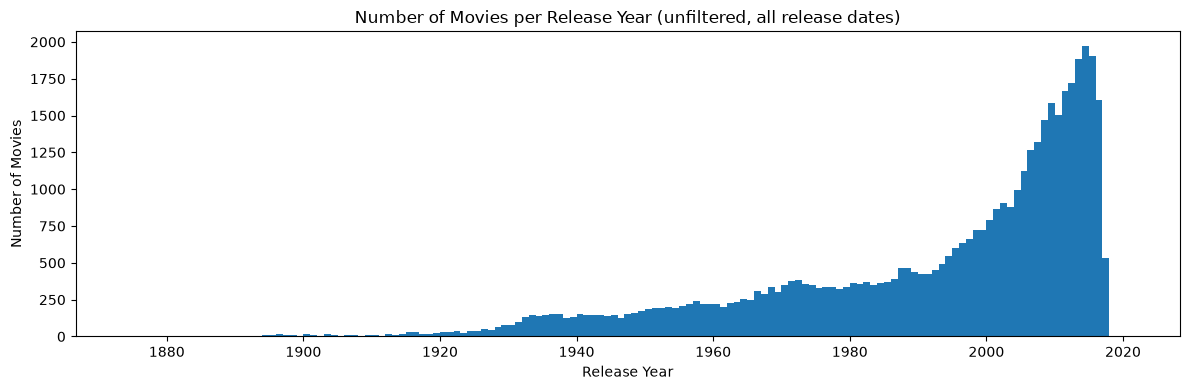

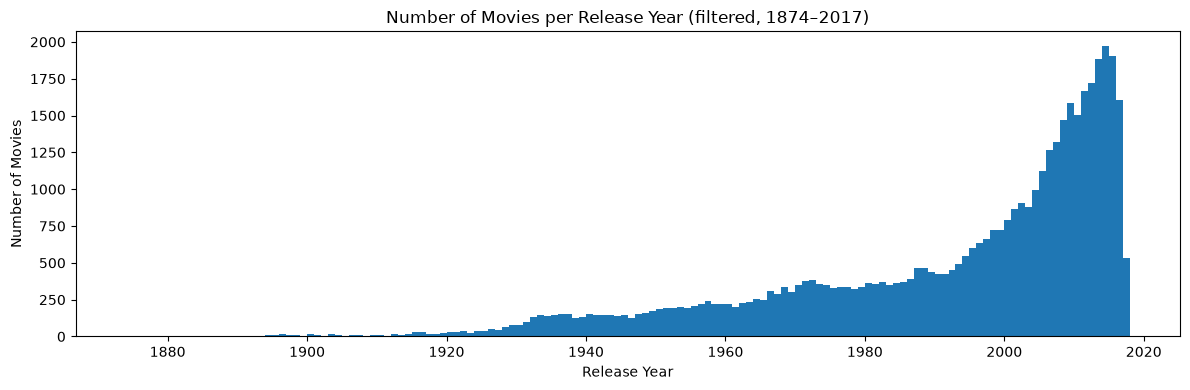

In [37]:
for release_years, version, description in [
    (movies["release_year"].dropna().astype(int), "unfiltered", "unfiltered, all release dates"),
    (timeline["release_year"], "filtered", f"filtered, {MIN_RELEASE_YEAR}–{MAX_RELEASE_YEAR}")
]:
    ax = release_years.plot(
        kind="hist",
        bins=range(release_years.min(), release_years.max() + 2),
        figsize=(12, 4),
        title=f"Number of Movies per Release Year ({description})",
        xlabel="Release Year"
    )

    ax.set_ylabel("Number of Movies")
    plt.tight_layout()
    plt.savefig(RESULT_FOLDER + f"release_dates/number_of_movies_per_year_{version}.png", bbox_inches="tight")
    plt.show()

In [38]:
movies_per_year = timeline["release_year"].value_counts().sort_index()

print(f"Release years: {int(movies['release_year'].min())}–{int(movies['release_year'].max())} (unfiltered), "
      f"{timeline['release_year'].min()}–{timeline['release_year'].max()} (filtered)")
print(f"Median release year: {timeline['release_year'].median():.0f}")
print(f"Movies released in 2000 or later: {100 * (timeline['release_year'] >= 2000).mean():.1f}%")
print(f"Most movies in one year: {movies_per_year.max():,} ({movies_per_year.idxmax()})")
display(movies_per_year.loc[2008:].rename("Movies").to_frame().T)

Release years: 1874–2020 (unfiltered), 1874–2017 (filtered)
Median release year: 2001
Movies released in 2000 or later: 52.9%
Most movies in one year: 1,973 (2014)


release_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
Movies,1470,1585,1501,1666,1721,1887,1973,1904,1604,532


### 4.2 Number of Movies per Decade

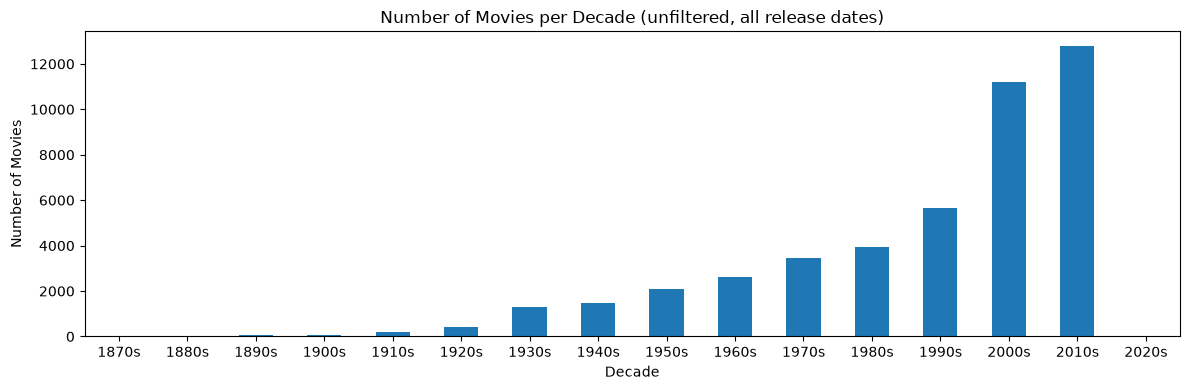

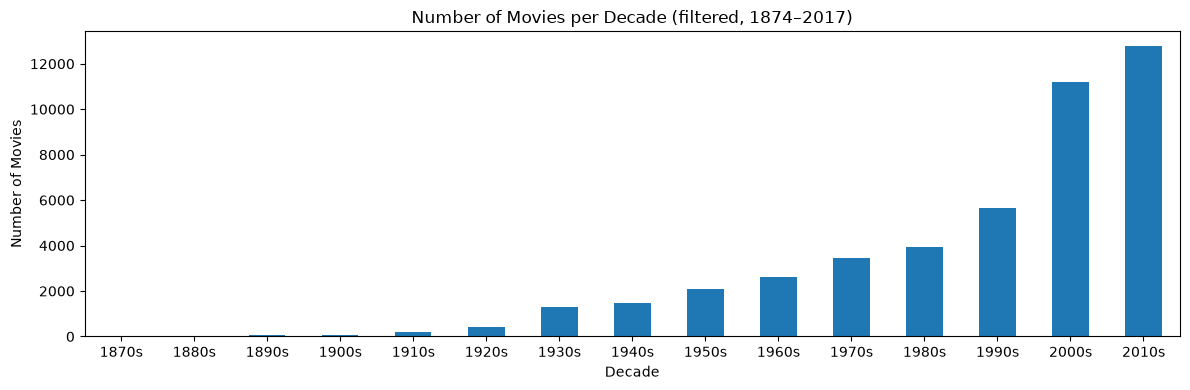

In [39]:
for release_decades, version, description in [
    (movies["decade"].dropna().astype(int), "unfiltered", "unfiltered, all release dates"),
    (timeline["decade"], "filtered", f"filtered, {MIN_RELEASE_YEAR}–{MAX_RELEASE_YEAR}")
]:
    ax = release_decades.value_counts().sort_index().rename(index=decade_label).plot(
        kind="bar",
        figsize=(12, 4),
        title=f"Number of Movies per Decade ({description})",
        xlabel="Decade",
        ylabel="Number of Movies",
        rot=0
    )

    plt.tight_layout()
    plt.savefig(RESULT_FOLDER + f"release_dates/number_of_movies_per_decade_{version}.png", bbox_inches="tight")
    plt.show()

In [40]:
decade_shares = pd.DataFrame({
    "Movies": movies_per_decade,
    "Share (%)": 100 * movies_per_decade / movies_per_decade.sum(),
    "Change from previous decade (%)": 100 * movies_per_decade.pct_change()
})

display(decade_shares.rename(index=decade_label).round(1).astype(object).T)

decade,1870s,1880s,1890s,1900s,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Movies,2,4,75,87,176,431,1315,1493,2079,2621,3471,3928,5675,11195,12788
Share (%),0.0,0.0,0.2,0.2,0.4,1.0,2.9,3.3,4.6,5.8,7.7,8.7,12.5,24.7,28.2
Change from previous decade (%),NaN,100.0,1775.0,16.0,102.3,144.9,205.1,13.5,39.2,26.1,32.4,13.2,44.5,97.3,14.2


**Key findings**

- 45,340 of the 45,433 movies have a release year within 1874–2017. 87 movies have no release date and 6 are planned releases dated after 2017.
- The number of movies grows steadily: the median release year is 2001, 52.9% of the movies were released in 2000 or later, and the 2010s are the largest decade with 12,788 movies (28.2%).
- The strongest growth came in the 1930s (+205%, the Hollywood studio era) and the 2000s (+97%).
- Most movies were released in 2014 (1,973). 2017 only has 532 movies, since the data was collected in mid-2017, and before 1910 every decade has fewer than 100 movies.

## 5. Distribution of Genres

### 5.1 Number of Movies per Genre

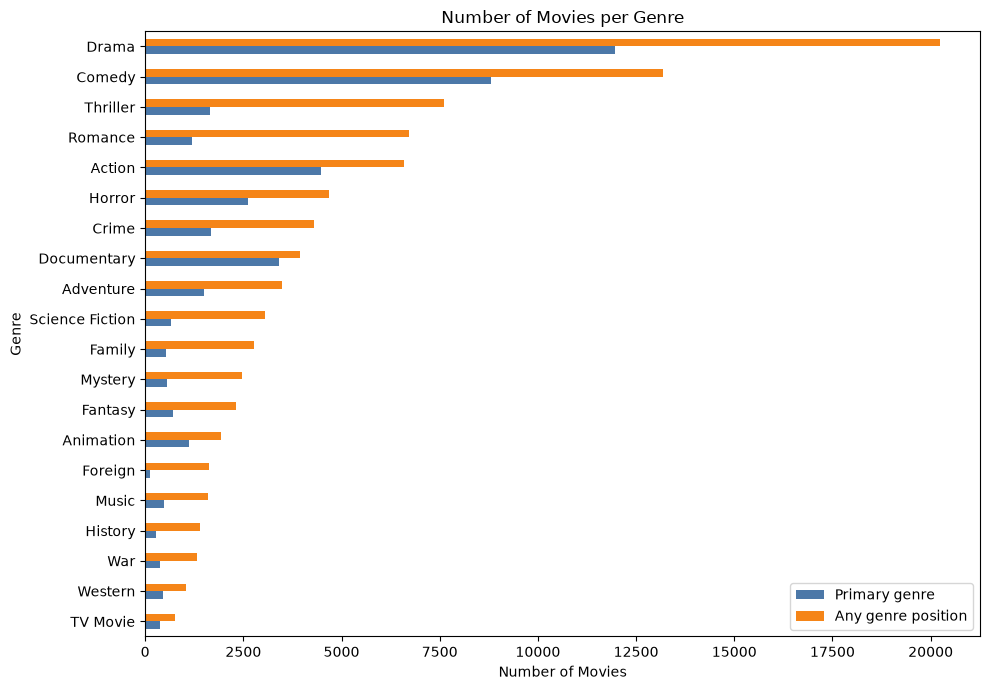

In [41]:
genre_counts = count_nested_values(movies["genre_names"])
primary_genre_counts = movies["primary_genre"].value_counts().reindex(genre_counts.index, fill_value=0)

genre_comparison = pd.DataFrame({
    "Primary genre": primary_genre_counts,
    "Any genre position": genre_counts,
})

ax = genre_comparison.sort_values("Any genre position").plot(
    kind="barh",
    figsize=(10, 7),
    color=["#4C78A8", "#F58518"],
    title="Number of Movies per Genre",
    ylabel="Genre"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "genres/genre_distribution.png", bbox_inches="tight")
plt.show()

In [42]:
genre_shares = pd.DataFrame({
    "Movies": genre_counts,
    "Share of movies (%)": 100 * genre_counts / len(movies),
    "As primary genre": primary_genre_counts,
    "Primary genre (%)": 100 * primary_genre_counts / genre_counts
})

print(f"{len(genre_counts)} distinct genres")
display(genre_shares.round(1))

20 distinct genres


,Movies,Share of movies (%),As primary genre,Primary genre (%)
Drama,20244,44.6,11953,59.0
Comedy,13176,29.0,8816,66.9
Thriller,7619,16.8,1663,21.8
Romance,6730,14.8,1191,17.7
Action,6592,14.5,4487,68.1
Horror,4671,10.3,2619,56.1
Crime,4304,9.5,1684,39.1
Documentary,3930,8.7,3413,86.8
Adventure,3490,7.7,1509,43.2
Science Fiction,3044,6.7,647,21.3


### 5.2 Number of Genres per Movie

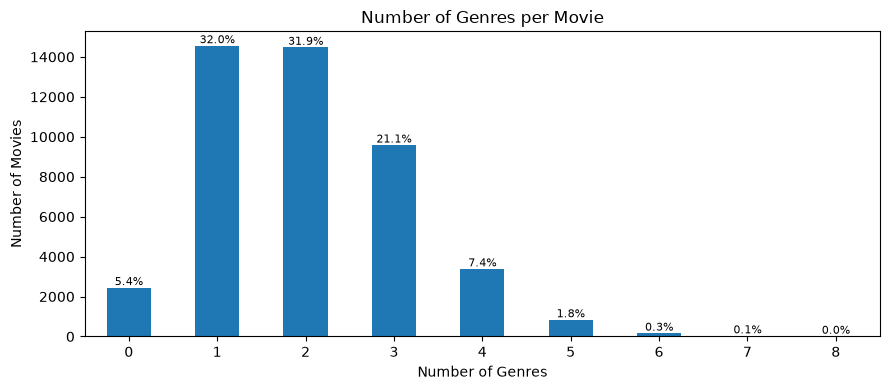

In [43]:
genres_per_movie = movies["n_genres"].value_counts().sort_index()

ax = genres_per_movie.plot(
    kind="bar",
    figsize=(9, 4),
    title="Number of Genres per Movie",
    xlabel="Number of Genres",
    ylabel="Number of Movies",
    rot=0
)

for patch, value in zip(ax.patches, genres_per_movie):
    ax.annotate(f"{100 * value / len(movies):.1f}%", (patch.get_x() + patch.get_width() / 2, value),
                ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "genres/genres_per_movie_distribution.png", bbox_inches="tight")
plt.show()

In [44]:
genre_pairs = Counter(
    (first, second)
    for names in movies["genre_names"]
    for position, first in enumerate(sorted(set(names)))
    for second in sorted(set(names))[position + 1:]
)

print(f"Mean genres per movie: {movies['n_genres'].mean():.2f} (median {movies['n_genres'].median():.0f}, max {movies['n_genres'].max()})")
print(f"Movies without a genre: {(movies['n_genres'] == 0).sum():,} ({100 * (movies['n_genres'] == 0).mean():.1f}%)")
print(f"Movies with 3 or more genres: {100 * (movies['n_genres'] >= 3).mean():.1f}%")
display(pd.Series({f"{first} + {second}": count for (first, second), count in genre_pairs.most_common(10)}, name="Movies").to_frame("Most common genre pairs"))

Mean genres per movie: 2.00 (median 2, max 8)
Movies without a genre: 2,442 (5.4%)
Movies with 3 or more genres: 30.7%


,Most common genre pairs
Drama + Romance,4483
Comedy + Drama,4186
Drama + Thriller,3425
Comedy + Romance,3116
Crime + Drama,2522
Action + Thriller,2370
Action + Drama,2321
Crime + Thriller,2014
Horror + Thriller,1926
Action + Adventure,1730


### 5.3 Average Number of Genres per Movie over Time

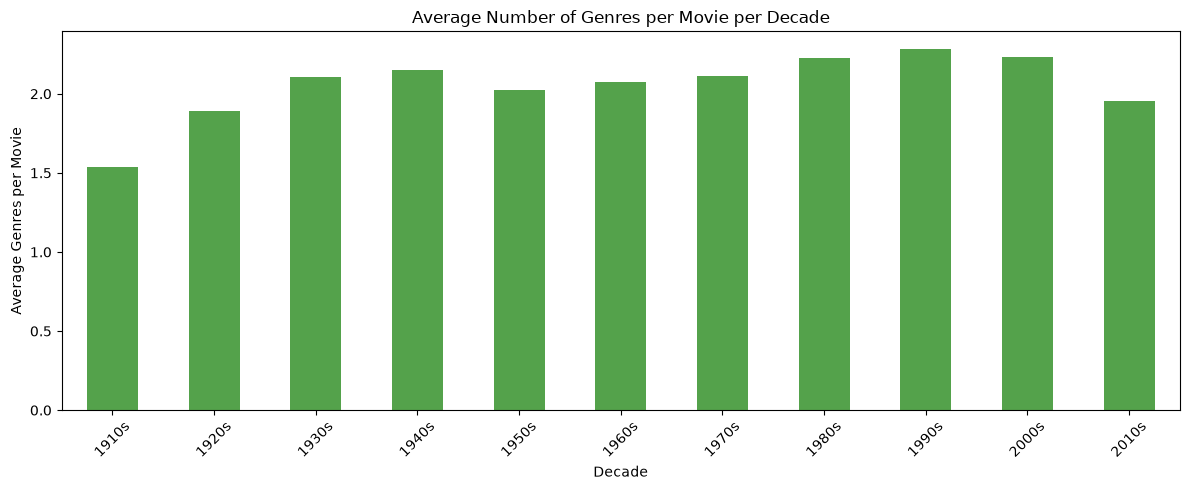

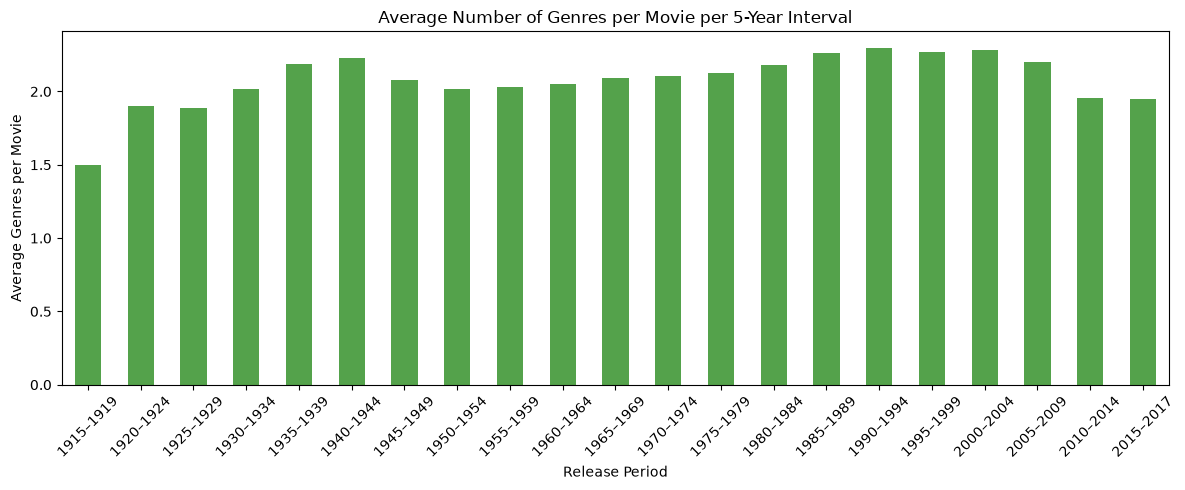

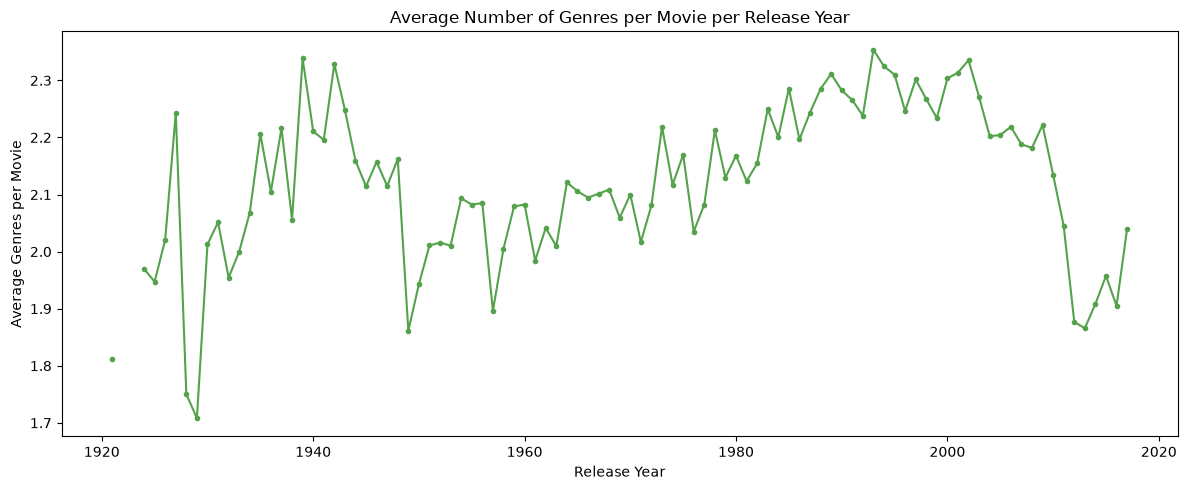

In [45]:
genres_movies = timeline[timeline["n_genres"].gt(0)]

genres_per_movie_per_decade = plot_average_over_time(
    genres_movies["n_genres"],
    genres_movies["release_year"],
    name="Number of Genres per Movie",
    ylabel="Average Genres per Movie",
    output_prefix=RESULT_FOLDER + "genres/average_genres_per_movie",
    color="#54A24B"
)

In [46]:
genre_breadth = genres_movies.groupby("decade")["n_genres"].agg(
    **{
        "Mean genres": "mean",
        "One genre (%)": lambda counts: 100 * counts.eq(1).mean(),
        "3 or more genres (%)": lambda counts: 100 * counts.ge(3).mean(),
        "Movies": "size"
    }
)

display(genre_breadth[genre_breadth["Movies"] >= MIN_MOVIES_PER_DECADE].rename(index=decade_label).round(2).astype(object).T)

decade,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean genres,1.54,1.89,2.11,2.15,2.02,2.08,2.11,2.23,2.28,2.23,1.96
One genre (%),58.71,39.7,29.51,29.29,36.15,34.8,32.54,30.34,27.12,30.92,40.29
3 or more genres (%),10.32,23.12,30.06,33.38,28.89,30.92,32.23,36.35,38.1,36.7,27.16
Movies,155,398,1264,1444,1997,2474,3270,3692,5273,10605,12256


**Key findings**

- There are 20 genres. Drama (44.6% of the movies) and Comedy (29.0%) dominate, followed by Thriller, Romance and Action (15–17% each).
- Documentary (86.8%), Action (68.1%) and Comedy (66.9%) are usually listed as the primary genre, while Foreign (7.3%), Romance (17.7%) and Thriller (21.8%) are mostly secondary genres.
- A movie has 2.00 genres on average (at most 8). 5.4% of the movies have no genre and 30.7% have three or more. The most common combinations are Drama + Romance (4,483 movies) and Comedy + Drama (4,186).
- The average number of genres grew from 1.54 in the 1910s to 2.28 in the 1990s and fell to 1.96 in the 2010s, when 40% of the movies only have one genre.

## 6. Distribution of Languages

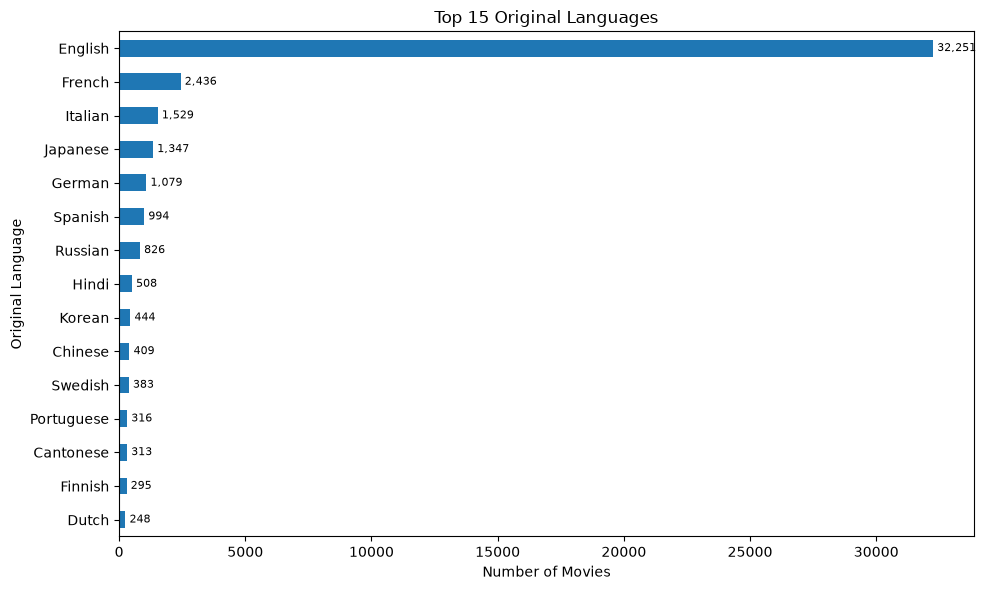

89 distinct original languages
English share: 71.0%


In [47]:
language_counts = movies["original_language"].value_counts()
top_languages = language_counts.head(TOP_N).rename(index=language_name)

ax = top_languages.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title=f"Top {TOP_N} Original Languages",
    ylabel="Original Language"
)

for patch, value in zip(ax.patches, top_languages.sort_values()):
    ax.annotate(f"{value:,}", (patch.get_width(), patch.get_y() + patch.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "languages/original_language_distribution.png", bbox_inches="tight")
plt.show()

print(f"{movies['original_language'].nunique()} distinct original languages")
print(f"English share: {100 * (movies['original_language'] == 'en').mean():.1f}%")

In [48]:
language_shares = pd.DataFrame({
    "Movies": language_counts,
    "Share (%)": 100 * language_counts / language_counts.sum()
}).head(10).rename(index=language_name)

print(f"Movies not originally in English: {movies['original_language'].ne('en').sum():,}")
display(language_shares.round(1))

Movies not originally in English: 13,182


,Movies,Share (%)
original_language,,
English,32251,71.0
French,2436,5.4
Italian,1529,3.4
Japanese,1347,3.0
German,1079,2.4
Spanish,994,2.2
Russian,826,1.8
Hindi,508,1.1
Korean,444,1.0


### 6.1 Number of Spoken Languages per Movie

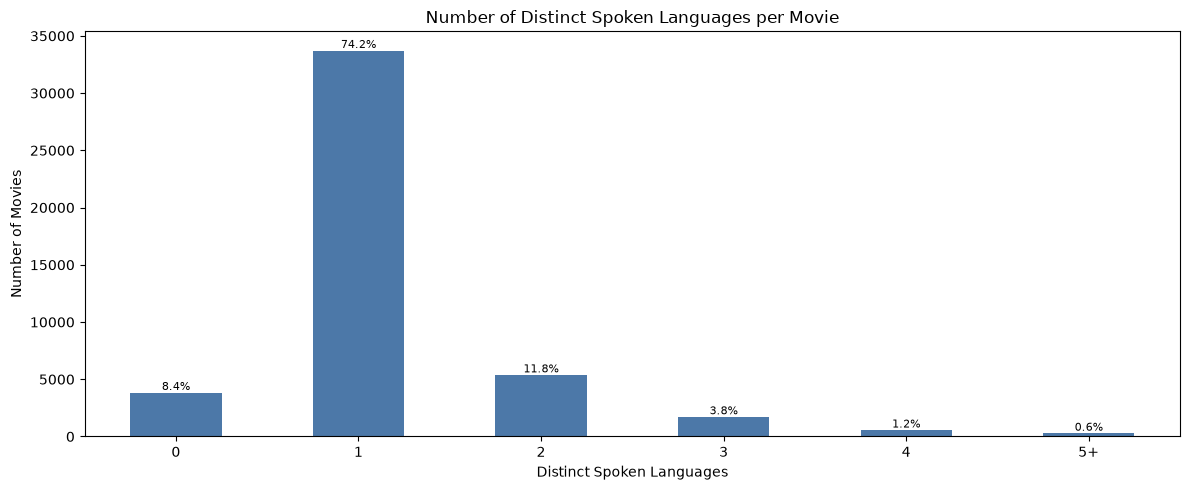

133 distinct spoken languages
Mean spoken languages per movie: 1.17 (max 19)


In [49]:
languages_per_movie = movies["language_codes"].map(lambda codes: len(set(codes)))

plot_share_bar_chart(
    languages_per_movie,
    bins=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, np.inf],
    labels=["0", "1", "2", "3", "4", "5+"],
    title="Number of Distinct Spoken Languages per Movie",
    xlabel="Distinct Spoken Languages",
    ylabel="Number of Movies",
    output_path=RESULT_FOLDER + "languages/spoken_languages_per_movie_distribution.png"
)

print(f"{movies['language_codes'].explode().nunique()} distinct spoken languages")
print(f"Mean spoken languages per movie: {languages_per_movie.mean():.2f} (max {languages_per_movie.max()})")

In [50]:
spoken_language_counts = count_nested_values(movies["language_codes"]).head(10)

print(f"Movies without a spoken language: {(languages_per_movie == 0).sum():,} ({100 * (languages_per_movie == 0).mean():.1f}%)")
print(f"Movies with 2 or more spoken languages: {(languages_per_movie >= 2).sum():,} ({100 * (languages_per_movie >= 2).mean():.1f}%)")
display(pd.DataFrame({
    "Movies": spoken_language_counts,
    "Share of movies (%)": 100 * spoken_language_counts / len(movies)
}).rename(index=language_name).round(1))

Movies without a spoken language: 3,830 (8.4%)
Movies with 2 or more spoken languages: 7,891 (17.4%)


,Movies,Share of movies (%)
English,28727,63.2
French,4193,9.2
German,2624,5.8
Spanish,2413,5.3
Italian,2366,5.2
Japanese,1756,3.9
Russian,1563,3.4
Chinese,790,1.7
Hindi,706,1.6
Portuguese,591,1.3


### 6.2 Language Diversity over Time

The number of distinct languages is counted both for the original language and for all spoken languages of the movies released in each decade, 5-year interval and year. "No Language" (`xx`) is excluded. A distinct count grows with the number of movies, so periods with fewer movies than the minimum in 1.3 are left out.

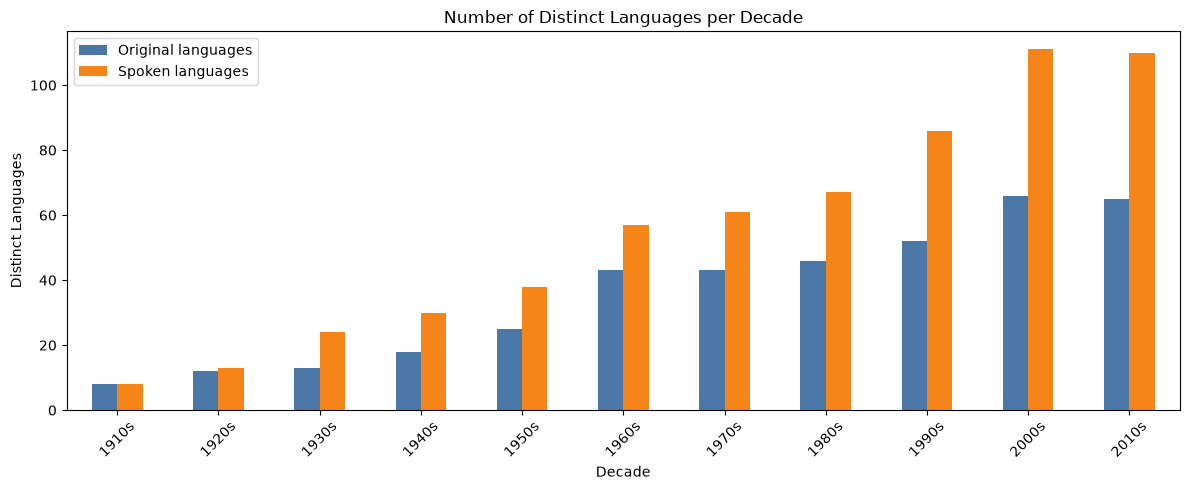

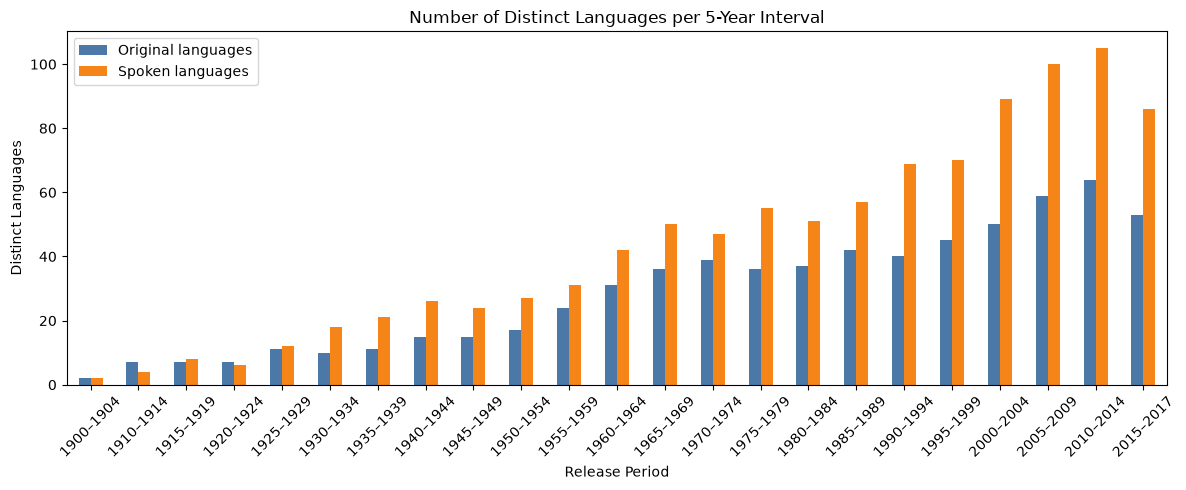

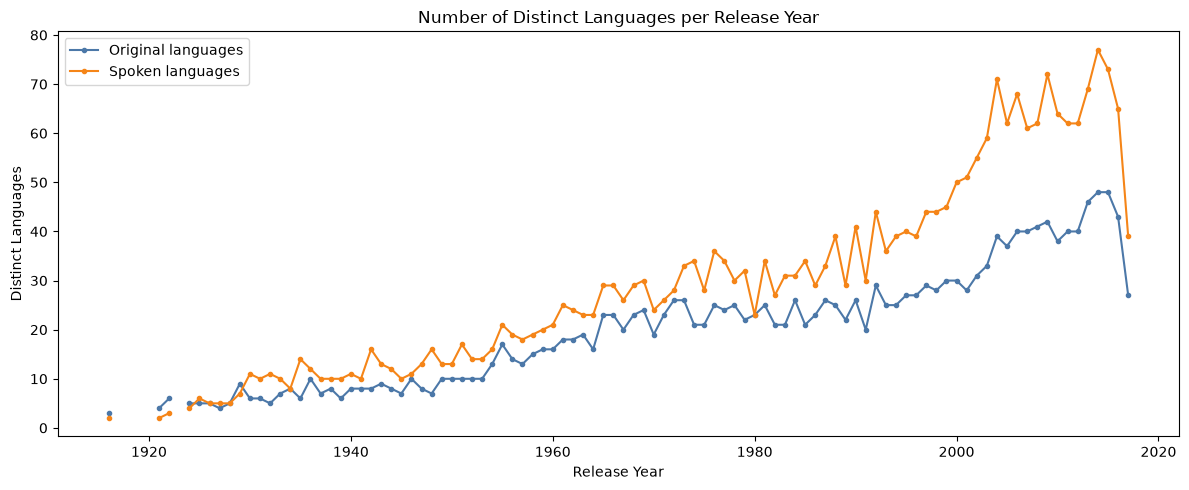

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Original languages,8.0,12.0,13.0,18.0,25.0,43.0,43.0,46.0,52.0,66.0,65.0
Spoken languages,8.0,13.0,24.0,30.0,38.0,57.0,61.0,67.0,86.0,111.0,110.0
Movies,176.0,431.0,1315.0,1493.0,2079.0,2621.0,3471.0,3928.0,5675.0,11195.0,12788.0
Non-English movies (%),22.7,23.2,12.6,10.0,22.0,39.8,38.1,27.9,24.1,30.1,31.1


In [51]:
original_languages = (
    timeline.loc[timeline["original_language"].notna() & timeline["original_language"].ne("xx"), ["id", "original_language", "release_year"]]
    .rename(columns={"id": "movie_id", "original_language": "value"})
)
spoken_languages = (
    timeline[["id", "language_codes", "release_year"]]
    .explode("language_codes")
    .dropna(subset=["language_codes"])
    .loc[lambda data: data["language_codes"].ne("xx")]
    .rename(columns={"id": "movie_id", "language_codes": "value"})
)

language_diversity = plot_distinct_over_time(
    {"Original languages": original_languages, "Spoken languages": spoken_languages},
    timeline["release_year"],
    name="Languages",
    ylabel="Distinct Languages",
    output_prefix=RESULT_FOLDER + "languages/distinct_languages",
    colors=["#4C78A8", "#F58518"]
)

non_english_share = 100 * timeline.groupby("decade")["original_language"].apply(lambda languages: languages.ne("en").mean())
display(language_diversity.assign(**{"Non-English movies (%)": non_english_share}).rename(index=decade_label).round(1).T)

**Key findings**

- The movies have 89 original languages, but 71.0% are originally in English, followed by French (5.4%), Italian (3.4%) and Japanese (3.0%).
- 133 languages are spoken. Most movies have one spoken language (1.17 on average, at most 19), 17.4% have two or more and 8.4% have none listed.
- Language diversity grows over time, from 8 original and 8 spoken languages in the 1910s to 65–66 original and 110–111 spoken languages in the 2000s–2010s. Part of this growth comes from the larger number of movies per decade.
- The non-English share is lowest in the 1930s–1940s (10–13%, the Hollywood studio era), highest in the 1960s–1970s (38–40%) and about 30% since 2000.

## 7. Distribution of Countries 

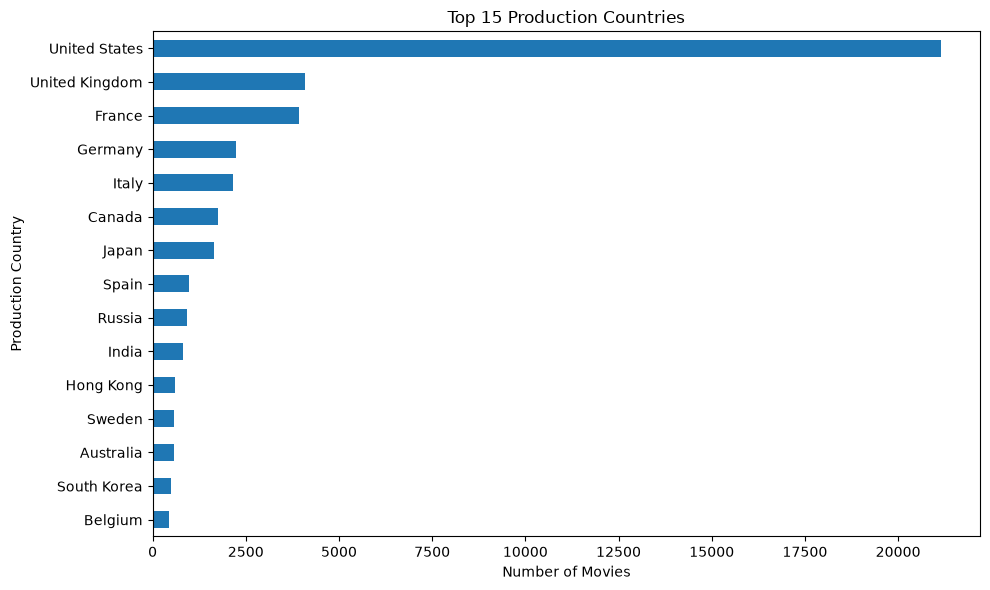

161 distinct production countries
Movies without production country: 6,282


In [52]:
country_counts = count_nested_values(movies["country_codes"])

ax = country_counts.rename(index=country_name).head(TOP_N).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title=f"Top {TOP_N} Production Countries",
    ylabel="Production Country"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "countries/production_country_distribution.png", bbox_inches="tight")
plt.show()

print(f"{len(country_counts)} distinct production countries")
print(f"Movies without production country: {(movies['country_codes'].map(len) == 0).sum():,}")

In [53]:
movies_with_country = movies["country_codes"].map(len).gt(0).sum()

display(pd.DataFrame({
    "Movies": country_counts.head(10),
    "Share of movies with a country (%)": 100 * country_counts.head(10) / movies_with_country
}).rename(index=country_name).round(1))

,Movies,Share of movies with a country (%)
United States,21140,54.0
United Kingdom,4091,10.4
France,3932,10.0
Germany,2249,5.7
Italy,2166,5.5
Canada,1765,4.5
Japan,1645,4.2
Spain,964,2.5
Russia,912,2.3
India,827,2.1


### 7.1 Number of Production Countries per Movie

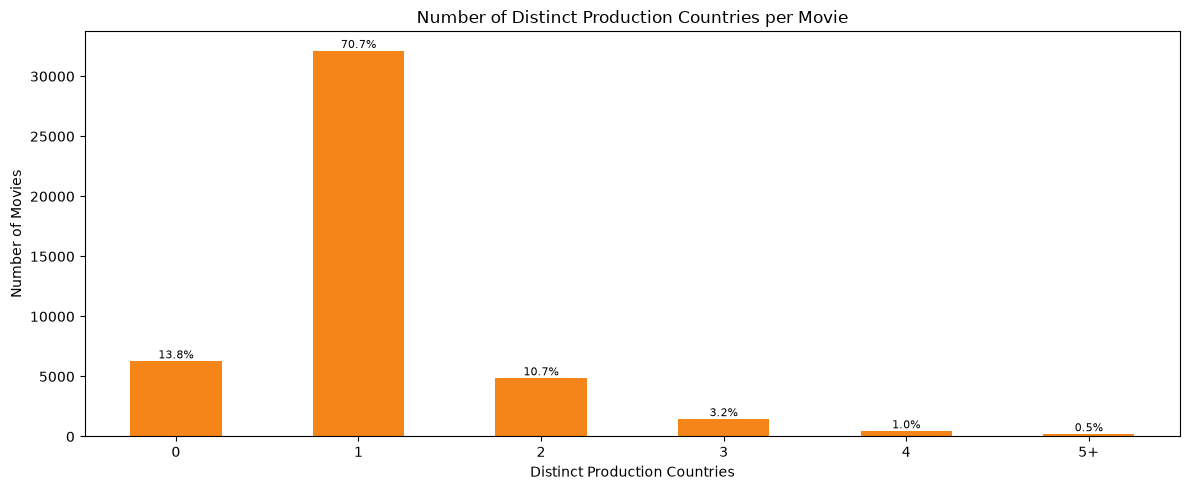

Mean production countries per movie: 1.09 (max 25)
Co-productions (2 or more countries): 7,017


In [54]:
countries_per_movie = movies["country_codes"].map(lambda codes: len(set(codes)))

plot_share_bar_chart(
    countries_per_movie,
    bins=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, np.inf],
    labels=["0", "1", "2", "3", "4", "5+"],
    title="Number of Distinct Production Countries per Movie",
    xlabel="Distinct Production Countries",
    ylabel="Number of Movies",
    output_path=RESULT_FOLDER + "countries/production_countries_per_movie_distribution.png",
    color="#F58518"
)

print(f"Mean production countries per movie: {countries_per_movie.mean():.2f} (max {countries_per_movie.max()})")
print(f"Co-productions (2 or more countries): {(countries_per_movie >= 2).sum():,}")

In [55]:
country_pairs = Counter(
    (first, second)
    for codes in movies["country_codes"]
    for position, first in enumerate(sorted(set(codes)))
    for second in sorted(set(codes))[position + 1:]
)

print(f"Co-productions among movies with a production country: {100 * (countries_per_movie >= 2).sum() / (countries_per_movie > 0).sum():.1f}%")
display(pd.Series(
    {f"{country_name(first)} + {country_name(second)}": count for (first, second), count in country_pairs.most_common(10)},
    name="Movies"
).to_frame("Most common co-production pairs"))

Co-productions among movies with a production country: 17.9%


,Most common co-production pairs
United Kingdom + United States,1087
France + Italy,659
Canada + United States,644
Germany + United States,555
Germany + France,499
France + United States,457
France + United Kingdom,408
Germany + United Kingdom,328
Belgium + France,271
Germany + Italy,235


### 7.2 Country Diversity over Time

The number of distinct production countries of the movies released in each decade, 5-year interval and year. Periods with fewer movies than the minimum in 1.3 are left out.

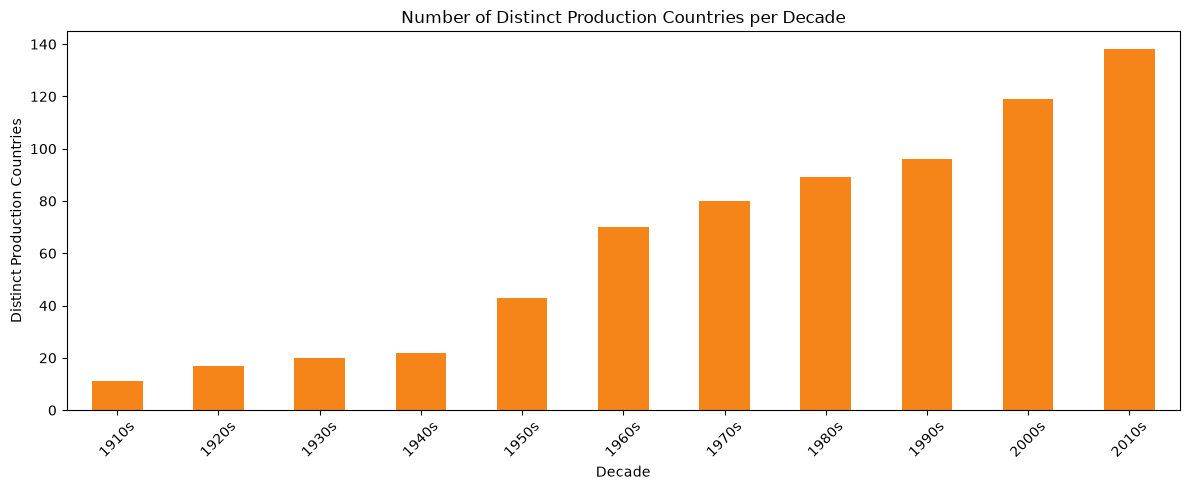

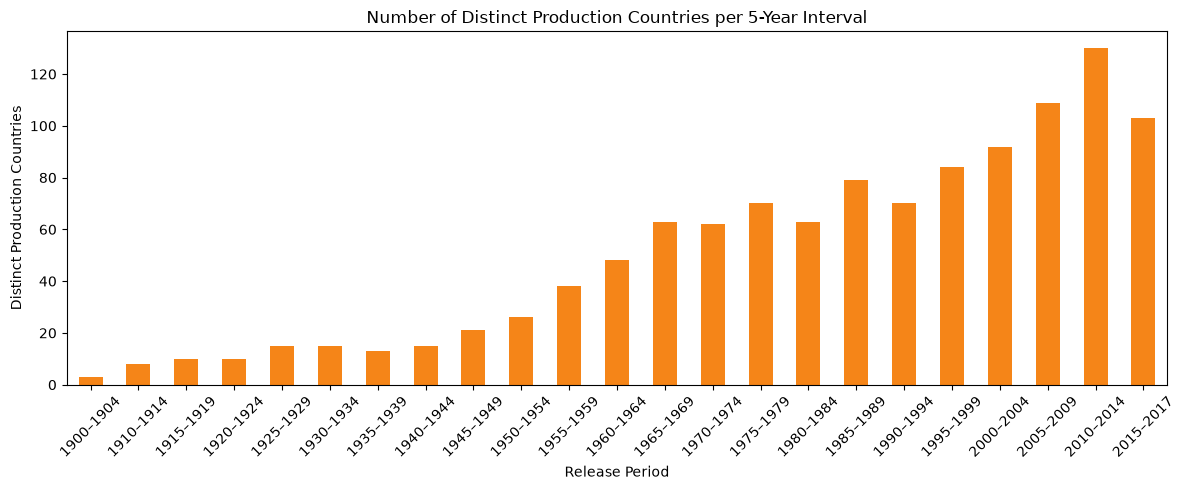

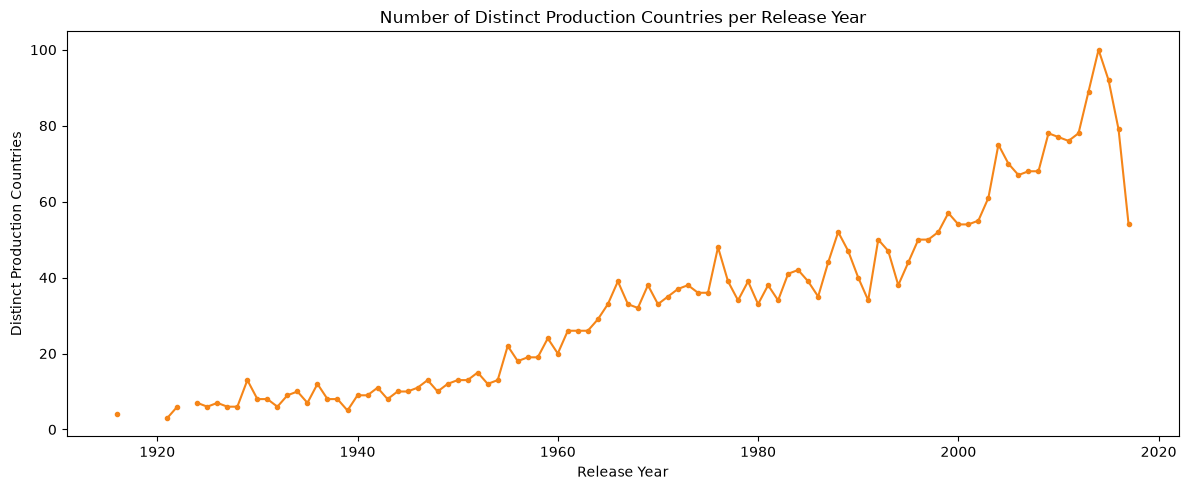

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Production countries,11,17,20,22,43,70,80,89,96,119,138
Movies,176,431,1315,1493,2079,2621,3471,3928,5675,11195,12788


In [56]:
production_countries = (
    timeline[["id", "country_codes", "release_year"]]
    .explode("country_codes")
    .dropna(subset=["country_codes"])
    .rename(columns={"id": "movie_id", "country_codes": "value"})
)

country_diversity = plot_distinct_over_time(
    {"Production countries": production_countries},
    timeline["release_year"],
    name="Production Countries",
    ylabel="Distinct Production Countries",
    output_prefix=RESULT_FOLDER + "countries/distinct_countries",
    colors=["#F58518"]
)

display(country_diversity.rename(index=decade_label).T)

In [57]:
coproduction_share = (
    timeline[timeline["country_codes"].map(len) > 0]
    .groupby("decade")["country_codes"]
    .apply(lambda codes: 100 * codes.map(lambda values: len(set(values)) >= 2).mean())
)

display(coproduction_share[coproduction_share.index.isin(ranked_decades)].rename(index=decade_label).rename("Co-productions (%)").round(1).to_frame().T)

decade,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Co-productions (%),2.2,0.8,0.8,0.9,7.1,18.8,18.1,16.5,20.9,24.0,18.8


**Key findings**

- The movies have 161 production countries. The United States is involved in 21,140 movies (54.0% of the movies with a country), far ahead of the United Kingdom (10.4%) and France (10.0%). 6,282 movies have no production country.
- 17.9% of the movies with a country are co-productions (1.09 countries on average, at most 25). The most common pairs are United Kingdom + United States (1,087 movies) and France + Italy (659).
- The number of distinct production countries per decade grew from 11 in the 1910s to 138 in the 2010s.
- Co-productions were rare before the 1950s (below 1% in the 1920s–1940s) and have made up 16–24% of the movies in every decade since the 1960s.

## 8. Distribution of Production Companies

Companies are identified by their TMDB `id`, because names are not unique.

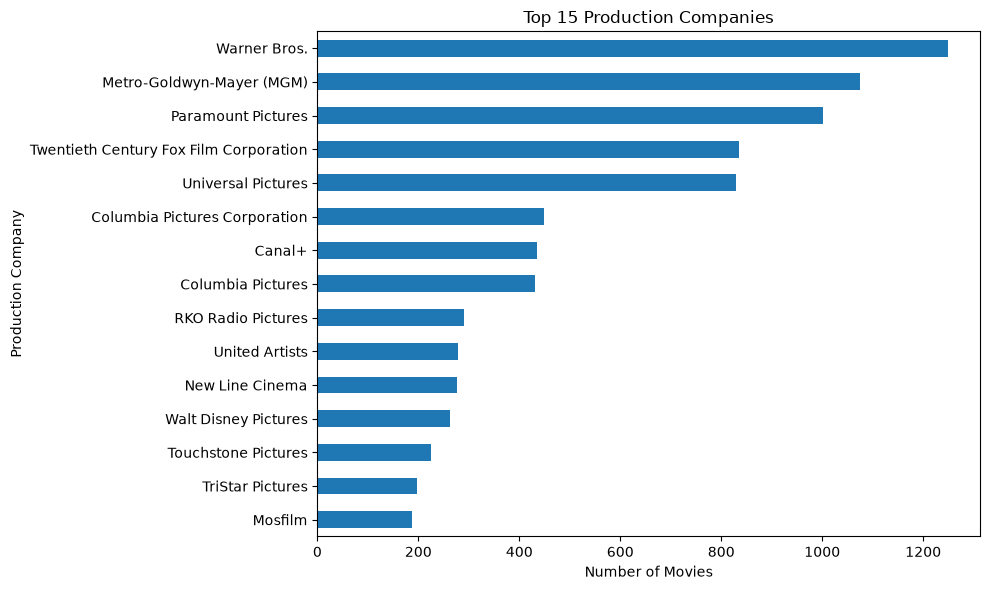

23,537 distinct production company names
Movies without production company: 11,871
Keys available in production_companies: ['id', 'name']


In [58]:
company_counts = count_nested_values(movies["company_names"])

ax = company_counts.head(TOP_N).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title=f"Top {TOP_N} Production Companies",
    ylabel="Production Company"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "companies/production_company_distribution.png", bbox_inches="tight")
plt.show()

print(f"{len(company_counts):,} distinct production company names")
print(f"Movies without production company: {(movies['company_names'].map(len) == 0).sum():,}")
print(f"Keys available in production_companies: {sorted({key for items in movies['production_companies'] for item in items for key in item})}")

In [59]:
top_companies = set(company_counts.head(TOP_N).index)

display(pd.DataFrame({
    "Movies": company_counts.head(10),
    "Share of movies (%)": 100 * company_counts.head(10) / len(movies)
}).round(1))
print(f"Movies made by at least one of the top {TOP_N} companies: "
      f"{100 * movies['company_names'].map(lambda names: bool(top_companies & set(names))).mean():.1f}%")

,Movies,Share of movies (%)
Warner Bros.,1250,2.8
Metro-Goldwyn-Mayer (MGM),1074,2.4
Paramount Pictures,1001,2.2
Twentieth Century Fox Film Corporation,836,1.8
Universal Pictures,830,1.8
Columbia Pictures Corporation,448,1.0
Canal+,436,1.0
Columbia Pictures,431,0.9
RKO Radio Pictures,290,0.6
United Artists,279,0.6


Movies made by at least one of the top 15 companies: 17.3%


### 8.1 Number of Movies per Production Company

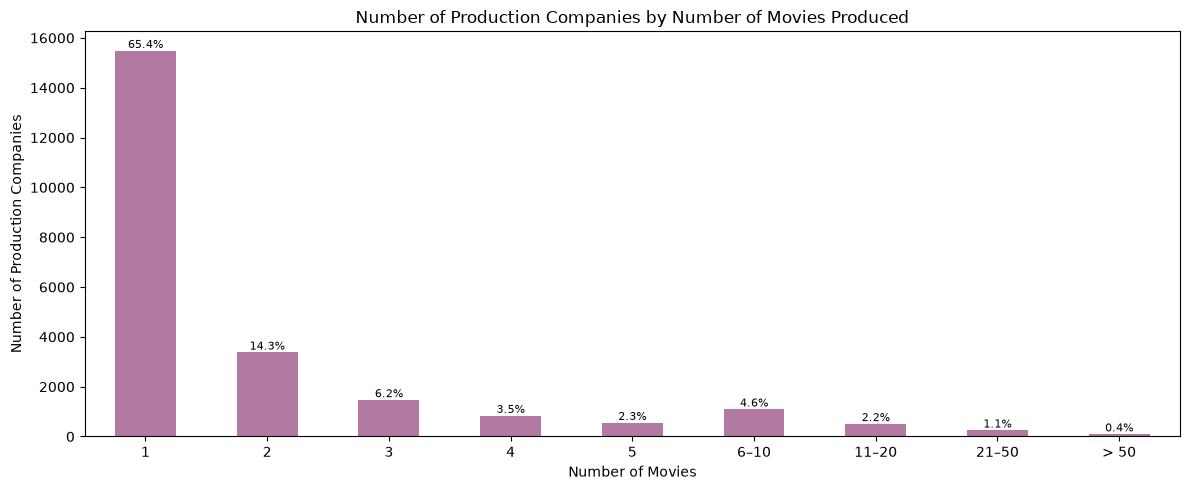

Distinct production companies: 23,692
Mean movies per production company: 2.97
Companies with more than 50 movies: 98


In [60]:
company_pairs = (
    movies[["id", "release_year", "production_companies"]]
    .assign(company=lambda data: data["production_companies"].map(lambda items: extract_field(items, "id")))
    .explode("company")
    .dropna(subset=["company"])
    .rename(columns={"id": "movie_id"})
    .drop_duplicates(["movie_id", "company"])[["movie_id", "company", "release_year"]]
)
movies_per_company = company_pairs.groupby("company")["movie_id"].nunique()

plot_share_bar_chart(
    movies_per_company,
    bins=MOVIE_COUNT_BINS,
    labels=MOVIE_COUNT_LABELS,
    title="Number of Production Companies by Number of Movies Produced",
    xlabel="Number of Movies",
    ylabel="Number of Production Companies",
    output_path=RESULT_FOLDER + "companies/movies_per_company_distribution.png",
    color="#B279A2"
)

print(f"Distinct production companies: {len(movies_per_company):,}")
print(f"Mean movies per production company: {movies_per_company.mean():.2f}")
print(f"Companies with more than 50 movies: {(movies_per_company > 50).sum():,}")

In [61]:
display(movies_per_company.describe(percentiles=[0.5, 0.75, 0.9, 0.99]).round(1).rename("Movies per company").to_frame().T)
print(f"Companies with only one movie: {100 * (movies_per_company == 1).mean():.1f}%")

,count,mean,std,min,50%,75%,90%,99%,max
Movies per company,23692.0,3.0,17.1,1.0,1.0,2.0,5.0,27.0,1250.0


Companies with only one movie: 65.4%


### 8.2 Movies per Active Production Company over Time

For each period, the number of distinct movies of every company that produced at least one movie in the period is counted, and the average is taken over these active companies (e.g. 10 and 20 movies give an average of 15). Periods with fewer movies than the minimum in 1.3 are left out. The number of active companies per 5-year interval is shown below for context.

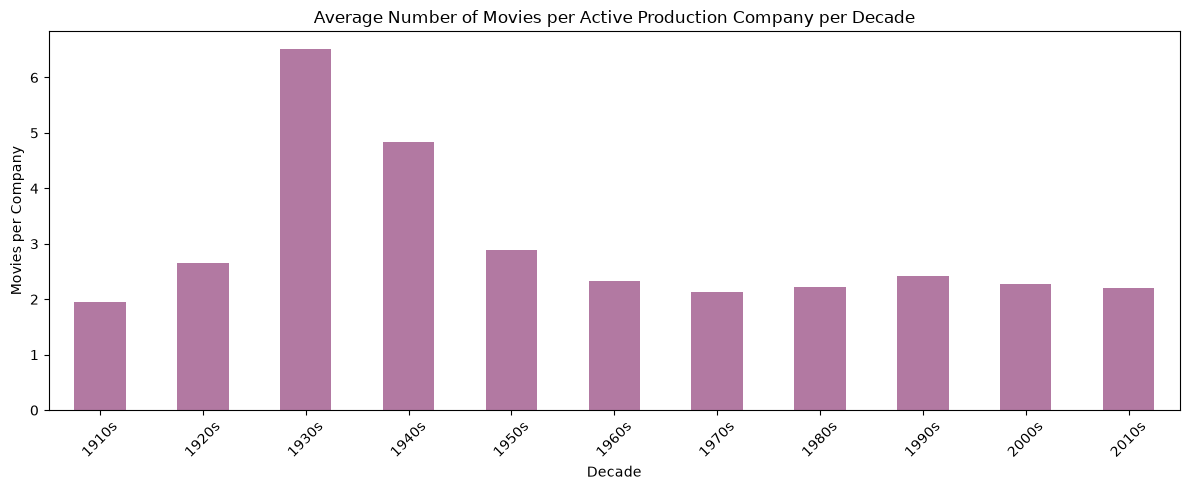

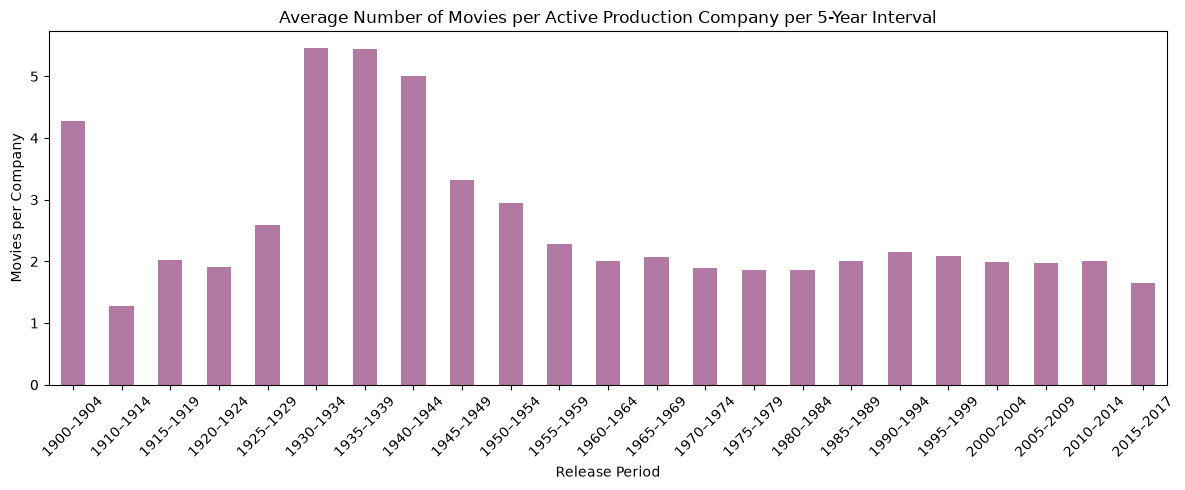

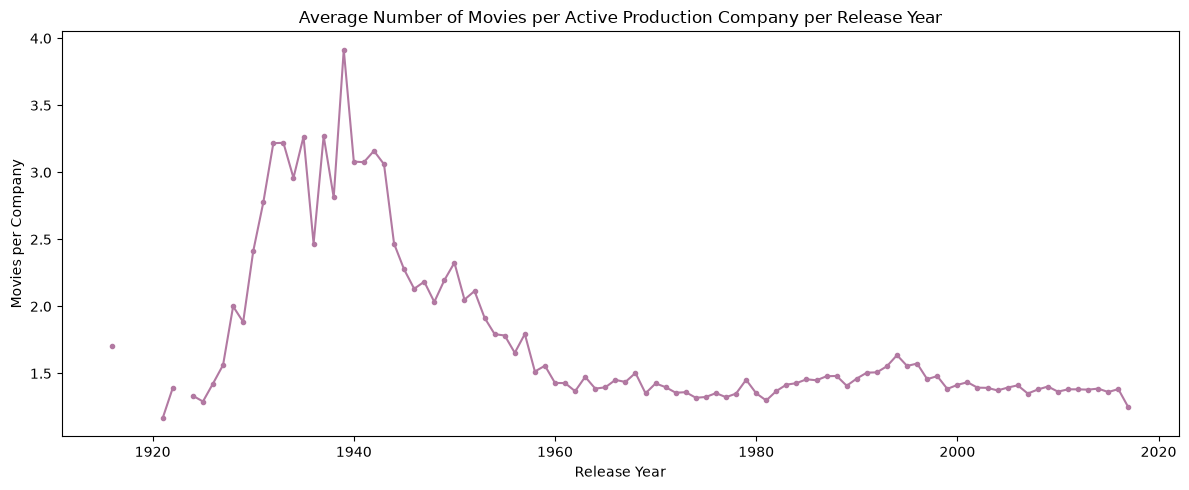

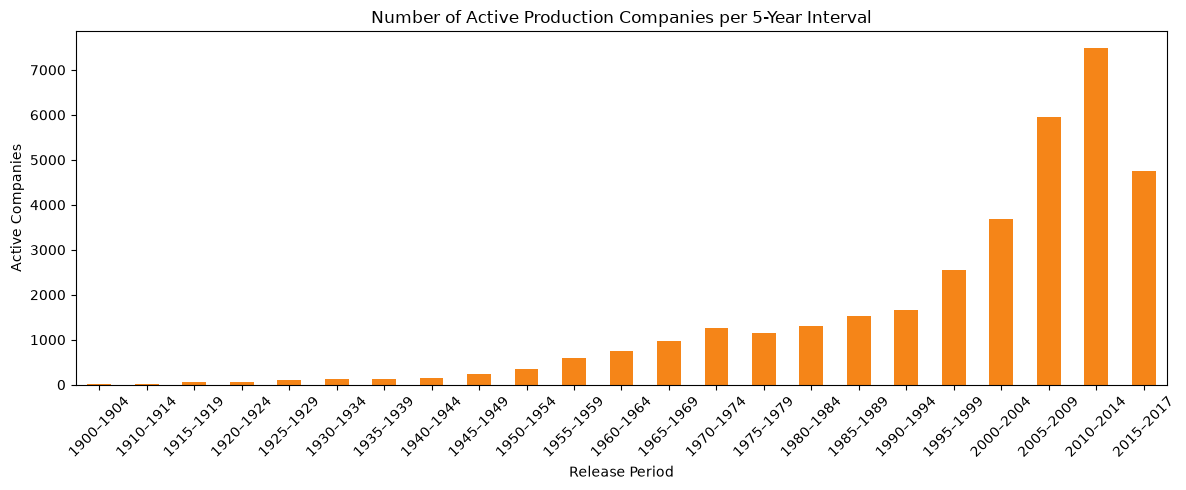

period,1900–1904,1910–1914,1915–1919,1920–1924,1925–1929,1930–1934,1935–1939,1940–1944,1945–1949,1950–1954,...,1970–1974,1975–1979,1980–1984,1985–1989,1990–1994,1995–1999,2000–2004,2005–2009,2010–2014,2015–2017
Mean,4.27,1.28,2.02,1.91,2.59,5.46,5.44,5.01,3.33,2.94,...,1.89,1.85,1.86,2.0,2.15,2.08,1.99,1.97,2.01,1.65
Active companies,11.00,25.00,52.00,68.00,109.00,118.00,134.00,156.00,246.00,356.00,...,1267.00,1151.00,1303.00,1534.0,1670.00,2550.00,3686.00,5943.00,7484.00,4763.00


In [62]:
dated_company_pairs = company_pairs[company_pairs["release_year"].between(MIN_RELEASE_YEAR, MAX_RELEASE_YEAR)]

company_activity = {}
for key, size, period_name, xlabel, label, kind, min_movies in TIME_GRANULARITIES:
    # Periods with few movies are left out, e.g. the 1890s where one company has most movies
    movies_per_period = (timeline["release_year"] // size * size).value_counts()
    periods = (dated_company_pairs["release_year"] // size * size).astype(int).rename("period")
    enough_movies = periods.map(movies_per_period).fillna(0) >= min_movies
    movies_per_active_company = dated_company_pairs[enough_movies].groupby([periods[enough_movies], "company"]).size()
    company_activity[key] = plot_average_per_period(
        movies_per_active_company,
        movies_per_active_company.index.get_level_values("period"),
        title=f"Average Number of Movies per Active Production Company per {period_name}",
        xlabel=xlabel,
        ylabel="Movies per Company",
        output_path=RESULT_FOLDER + f"companies/movies_per_company_{key}.png",
        label=label,
        kind=kind,
        color="#B279A2"
    ).rename(columns={"Movies": "Active companies"})

ax = company_activity["per_5_years"]["Active companies"].rename(index=period_5y_label).plot(
    kind="bar",
    figsize=(12, 5),
    color="#F58518",
    title="Number of Active Production Companies per 5-Year Interval",
    xlabel="Release Period",
    rot=45
)

ax.set_ylabel("Active Companies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "companies/active_companies_per_5_years.png", bbox_inches="tight")
plt.show()

display(company_activity["per_5_years"].rename(index=period_5y_label).round(2).T)

**Key findings**

- There are 23,692 production companies (23,537 distinct names). The largest are the classic Hollywood studios Warner Bros. (1,250 movies), Metro-Goldwyn-Mayer (1,074) and Paramount Pictures (1,001), and the 15 largest companies are involved in 17.3% of the movies.
- Production is fragmented: 65.4% of the companies have only one movie, the median is 1 movie and the 99th percentile 27 movies. 11,871 movies have no production company.
- In 1930–1944, an active company made 5.0–5.5 movies per 5-year interval, compared with about 2 before and after. This is the Hollywood studio system, in which a few large studios produced most movies, and since 1960 the average has stayed at about 2.
- The number of active companies grew from 118 in 1930–1934 to 7,484 in 2010–2014, so the additional movies are made by many small companies. The lower values for 2015–2017 come from the shorter last interval.

## 9. Distribution of Runtime

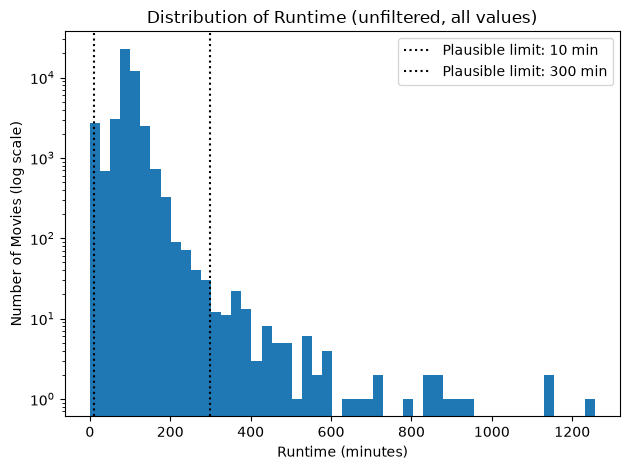

260 movies have no runtime
1558 movies have runtime = 0
606 movies are shorter than 10 minutes
108 movies are longer than 300 minutes


In [63]:
ax = movies["runtime"].plot(
    kind="hist",
    bins=50,
    title="Distribution of Runtime (unfiltered, all values)",
    xlabel="Runtime (minutes)"
)

limits = [ax.axvline(limit, color="black", linestyle=":", label=f"Plausible limit: {limit} min") for limit in (MIN_RUNTIME, MAX_RUNTIME)]
ax.set_yscale("log")
ax.set_ylabel("Number of Movies (log scale)")
ax.legend(handles=limits)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "runtime/runtime_distribution_unfiltered.png", bbox_inches="tight")
plt.show()

print(movies["runtime"].isna().sum(), "movies have no runtime")
print((movies["runtime"] == 0).sum(), "movies have runtime = 0")
print(movies["runtime"].between(1, MIN_RUNTIME - 1).sum(), f"movies are shorter than {MIN_RUNTIME} minutes")
print((movies["runtime"] > MAX_RUNTIME).sum(), f"movies are longer than {MAX_RUNTIME} minutes")

In [64]:
display(movies["runtime"][movies["runtime"] > 0].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1).rename("Runtime > 0 (minutes)").to_frame().T)
display(movies.nlargest(5, "runtime")[["title", "release_year", "runtime"]])

,count,mean,std,min,1%,25%,50%,75%,99%,max
Runtime > 0 (minutes),43615.0,97.5,34.7,1.0,7.0,86.0,95.0,107.0,187.0,1256.0


,title,release_year,runtime
24159,Centennial,1978,1256.0
19954,Jazz,2001,1140.0
40907,Baseball,1994,1140.0
13760,Berlin Alexanderplatz,1980,931.0
13946,Heimat: A Chronicle of Germany,1984,925.0


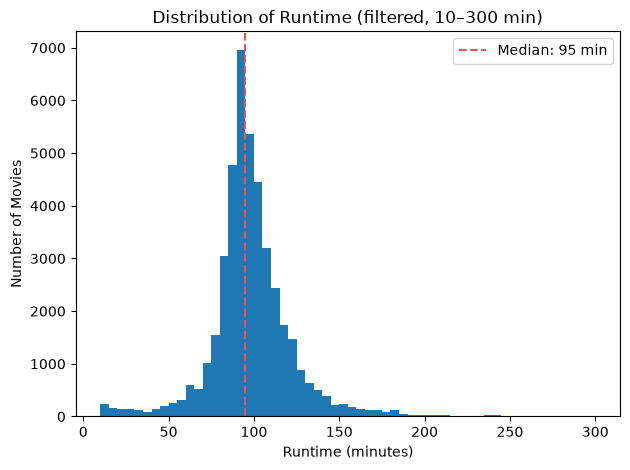

Movies with a plausible runtime: 42,901 of 45,433


In [65]:
plausible_runtime = movies["runtime"][movies["runtime"].between(MIN_RUNTIME, MAX_RUNTIME)]

ax = plausible_runtime.plot(
    kind="hist",
    bins=range(MIN_RUNTIME, MAX_RUNTIME + 5, 5),
    title=f"Distribution of Runtime (filtered, {MIN_RUNTIME}–{MAX_RUNTIME} min)",
    xlabel="Runtime (minutes)"
)

line = ax.axvline(plausible_runtime.median(), color="#E45756", linestyle="--", label=f"Median: {plausible_runtime.median():.0f} min")
ax.set_ylabel("Number of Movies")
ax.legend(handles=[line])
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "runtime/runtime_distribution_filtered.png", bbox_inches="tight")
plt.show()

print(f"Movies with a plausible runtime: {len(plausible_runtime):,} of {len(movies):,}")

In [66]:
display(plausible_runtime.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).rename(f"Runtime {MIN_RUNTIME}–{MAX_RUNTIME} min").to_frame().T)
print(f"Movies between 80 and 120 minutes: {100 * plausible_runtime.between(80, 120).mean():.1f}%")

,count,mean,std,min,10%,25%,50%,75%,90%,max
Runtime 10–300 min,42901.0,97.8,25.4,10.0,75.0,87.0,95.0,107.0,123.0,300.0


Movies between 80 and 120 minutes: 75.9%


### 9.1 Average Runtime over Time

Only runtimes within the plausible limits (10–300 minutes, see 1.3) are used. Periods with fewer runtimes than the minimum in 1.3 are left out.

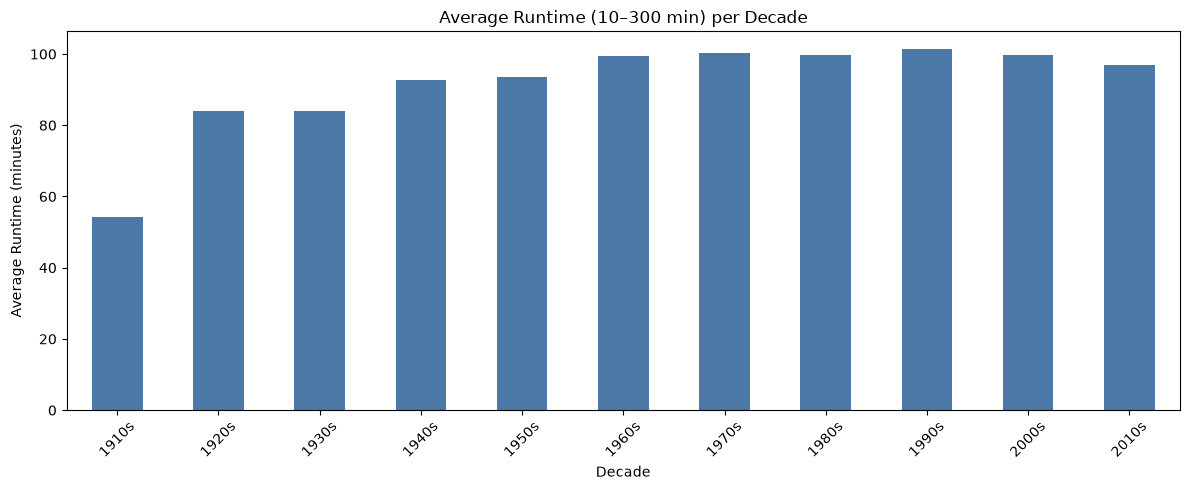

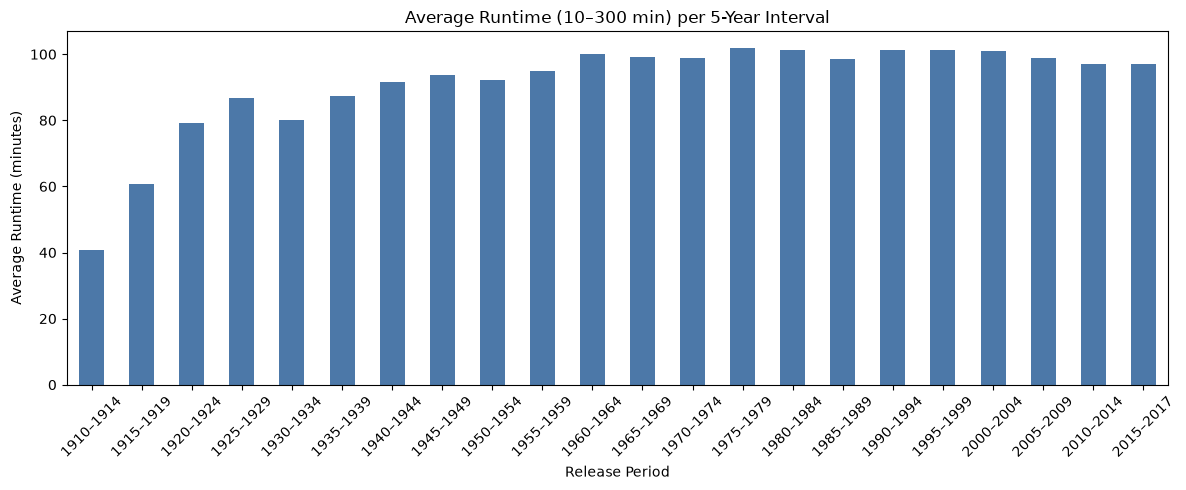

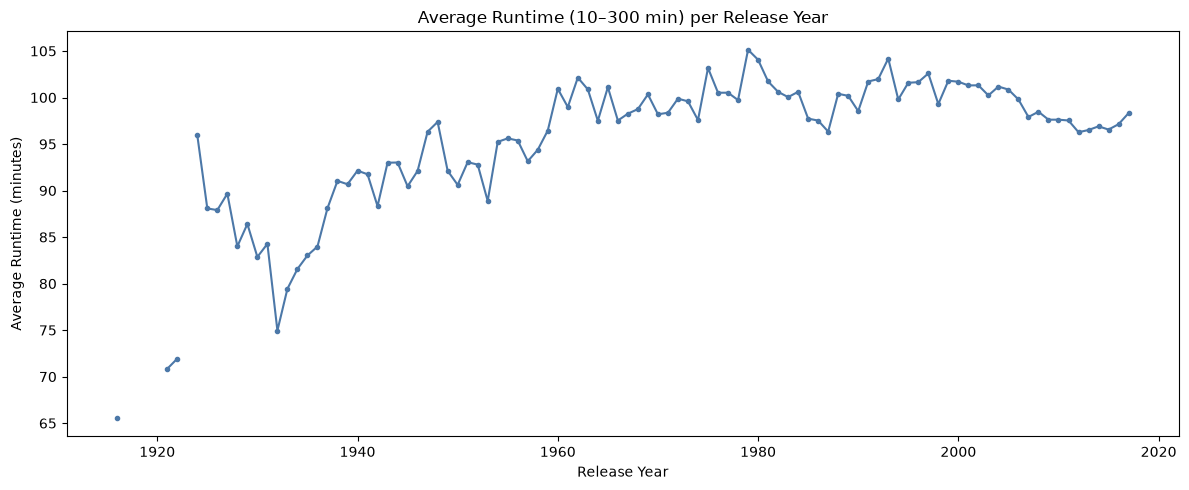

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean,54.3,84.0,84.0,92.7,93.6,99.5,100.2,99.8,101.3,99.7,97.0
Movies,167.0,406.0,1256.0,1443.0,1999.0,2519.0,3325.0,3748.0,5413.0,10568.0,11995.0


In [67]:
dated_runtime = timeline[timeline["runtime"].between(MIN_RUNTIME, MAX_RUNTIME)]

runtime_per_decade = plot_average_over_time(
    dated_runtime["runtime"],
    dated_runtime["release_year"],
    name=f"Runtime ({MIN_RUNTIME}–{MAX_RUNTIME} min)",
    ylabel="Average Runtime (minutes)",
    output_prefix=RESULT_FOLDER + "runtime/average_runtime"
)

display(runtime_per_decade.rename(index=decade_label).round(1).T)

**Key findings**

- 260 movies have no runtime and 1,558 have a runtime of 0, which both mean "unknown". 606 movies are shorter than 10 minutes (mostly early short films) and 108 are longer than 300 minutes (series such as *Centennial*, 1,256 minutes).
- Within the plausible limits (42,901 movies), the median runtime is 95 minutes (mean 97.8) and 75.9% of the movies last 80–120 minutes.
- The average runtime grew from 54 minutes in the 1910s to 84 minutes in the 1920s–1930s and about 100 minutes from the 1960s to the 1990s, and has slowly declined to 97 minutes in the 2010s.

## 10. Distribution of Budget

### 10.1 Availability of Budget

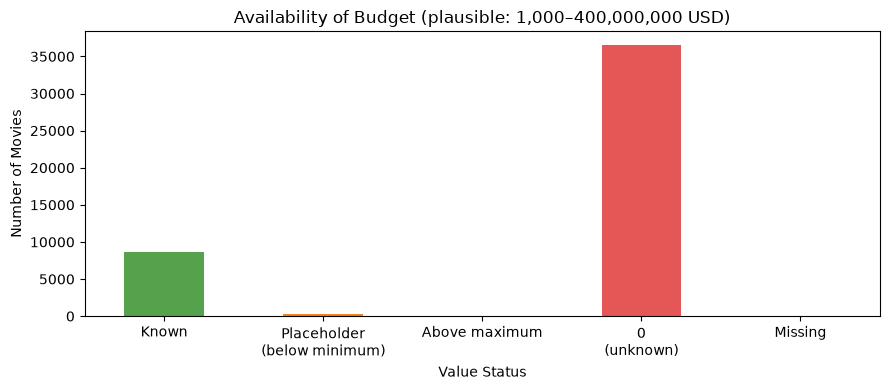

,Movies,Share (%)
Known,8636,19.01
Placeholder (below minimum),244,0.54
Above maximum,0,0.00
0 (unknown),36553,80.45
Missing,0,0.00


In [68]:
display(plot_money_availability(movies["budget"], "Budget", RESULT_FOLDER + "budget/budget_availability.png", MIN_BUDGET_USD, MAX_BUDGET_USD).round(2))

### 10.2 Distribution of Budget

The unfiltered distribution shows every positive budget (0 means "unknown" and cannot be shown on a log scale), with the plausible limits as dotted lines. The filtered distribution only shows budgets within the limits.

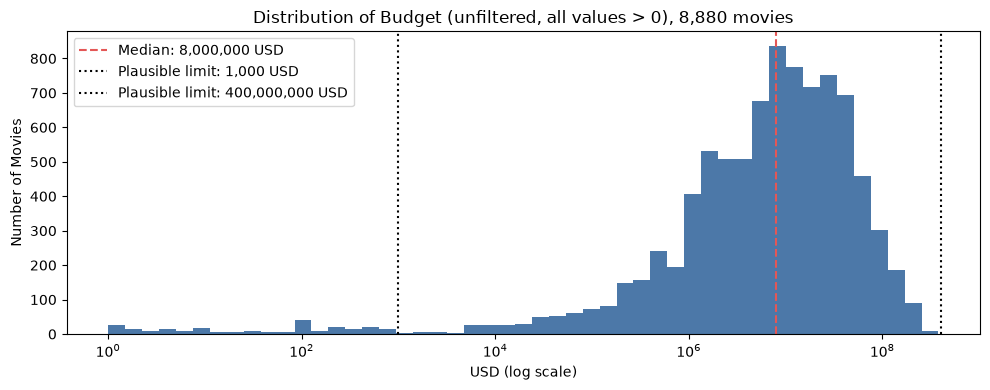

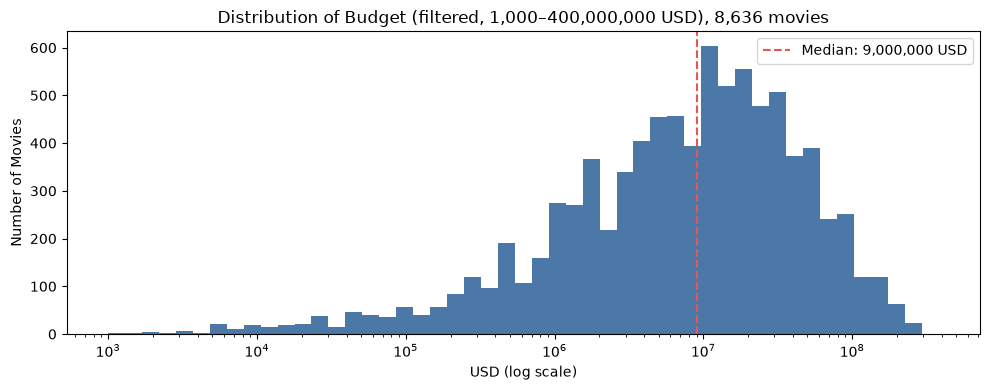

In [69]:
plot_money_distribution(
    movies["budget"][movies["budget"] > 0],
    title="Distribution of Budget (unfiltered, all values > 0)",
    output_path=RESULT_FOLDER + "budget/budget_distribution_unfiltered.png",
    color="#4C78A8",
    limits=(MIN_BUDGET_USD, MAX_BUDGET_USD)
)

plot_money_distribution(
    movies["budget_usd"].dropna(),
    title=f"Distribution of Budget (filtered, {MIN_BUDGET_USD:,}–{MAX_BUDGET_USD:,} USD)",
    output_path=RESULT_FOLDER + "budget/budget_distribution_filtered.png",
    color="#4C78A8"
)

In [70]:
display((movies["budget_usd"].dropna() / 1e6).describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(2).rename("Budget (million USD)").to_frame().T)
display(movies.nlargest(5, "budget_usd")[["title", "release_year", "budget_usd"]])

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
Budget (million USD),8636.0,22.22,34.61,0.0,0.5,2.2,9.0,26.0,60.0,175.0,380.0


,title,release_year,budget_usd
17114,Pirates of the Caribbean: On Stranger Tides,2011,380000000.0
11822,Pirates of the Caribbean: At World's End,2007,300000000.0
26538,Avengers: Age of Ultron,2015,280000000.0
11062,Superman Returns,2006,270000000.0
16121,Tangled,2010,260000000.0


### 10.3 Average Budget over Time

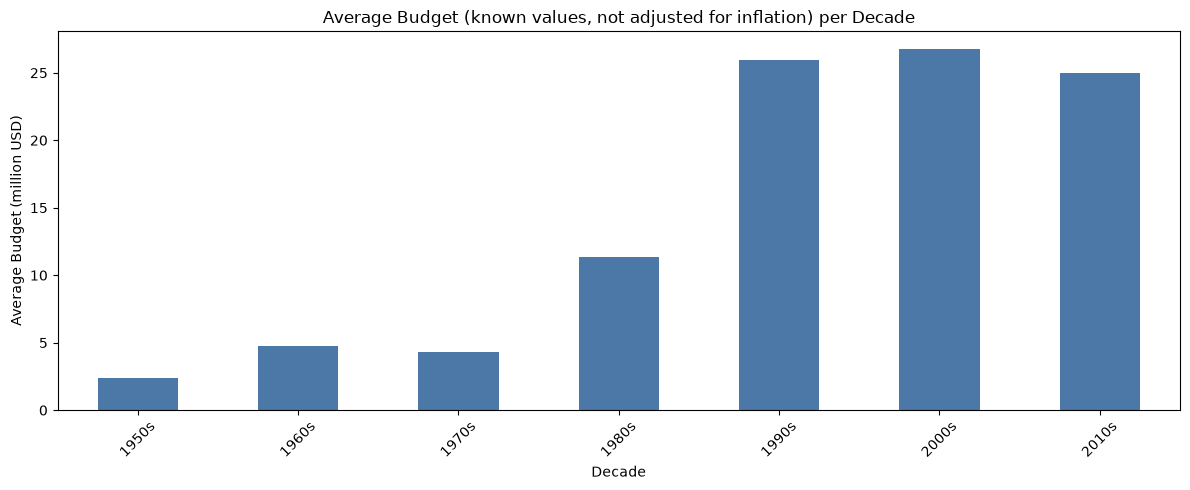

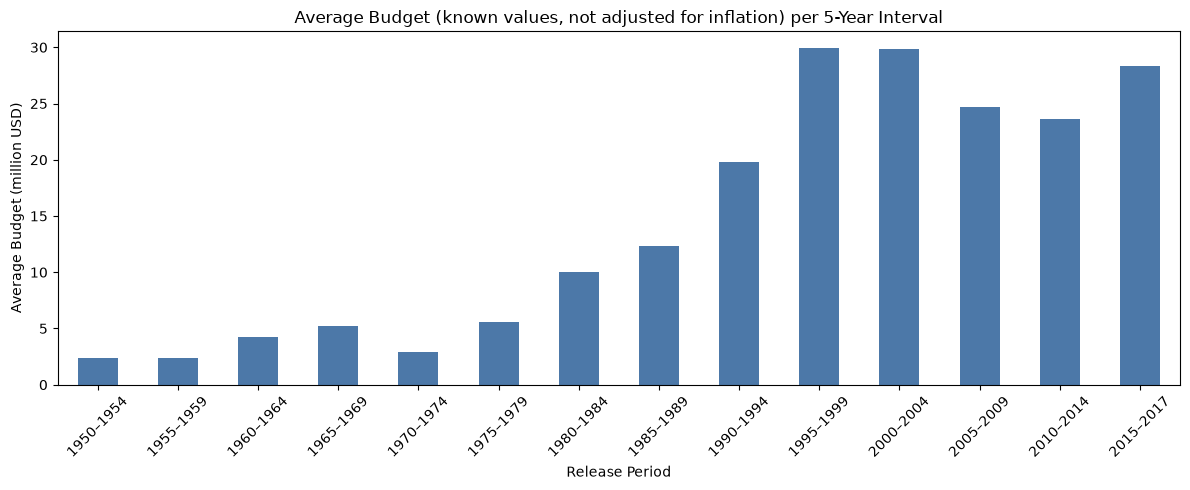

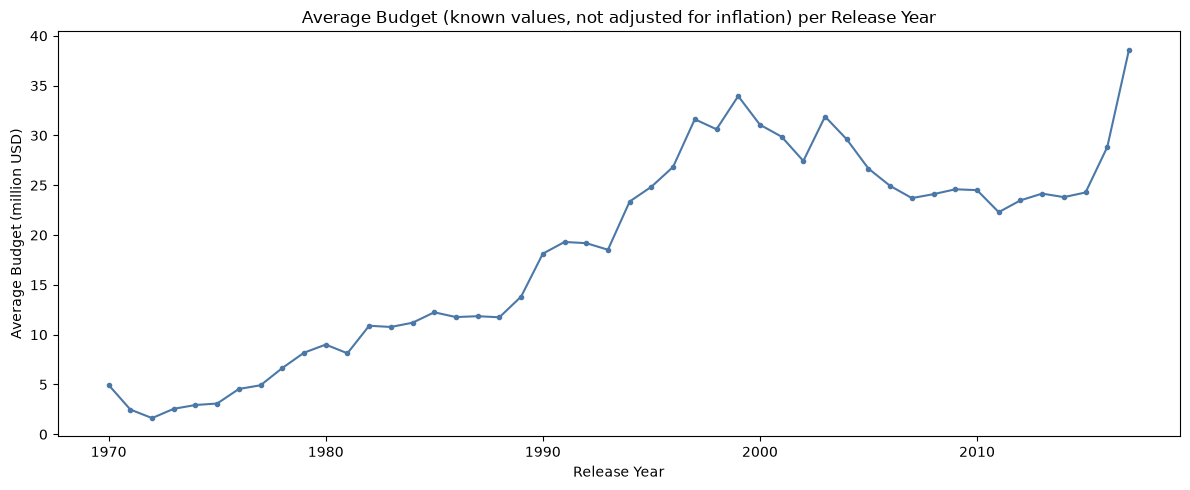

release_year,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean,2.4,4.8,4.3,11.3,26.0,26.7,25.0
Movies,142.0,226.0,361.0,735.0,1276.0,2825.0,2861.0


In [71]:
dated_budget = timeline[timeline["budget_usd"].notna()]

budget_per_decade = plot_average_over_time(
    dated_budget["budget_usd"] / 1e6,
    dated_budget["release_year"],
    name="Budget (known values, not adjusted for inflation)",
    ylabel="Average Budget (million USD)",
    output_prefix=RESULT_FOLDER + "budget/average_budget",
    color="#4C78A8"
)

display(budget_per_decade.rename(index=decade_label).round(1).T)

In [72]:
median_budget_per_decade = dated_budget.groupby("decade")["budget_usd"].median() / 1e6

display(median_budget_per_decade[median_budget_per_decade.index.isin(budget_per_decade.index)].rename(index=decade_label).rename("Median budget (million USD)").round(1).to_frame().T)

decade,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Median budget (million USD),1.5,2.1,2.0,8.0,18.0,13.0,8.0


**Key findings**

- Only 8,636 movies (19.0%) have a known budget. 36,553 movies (80.5%) have a budget of 0, and 244 have a placeholder below 1,000 USD.
- The known budgets are strongly right-skewed: the median is 9.0 million USD, the mean 22.2 million and the 99th percentile 175 million. The most expensive movie is *Pirates of the Caribbean: On Stranger Tides* (380 million USD).
- From the 1950s on, every decade has at least 100 known budgets. The average budget rose from 2.4 million USD in the 1950s to about 26 million in the 1990s–2000s, while the median peaked at 18 million in the 1990s and fell to 8 million in the 2010s, as more small productions report their budget.
- The values are not adjusted for inflation, and older budgets are mostly known for large productions.

## 11. Distribution of Revenue

### 11.1 Availability of Revenue

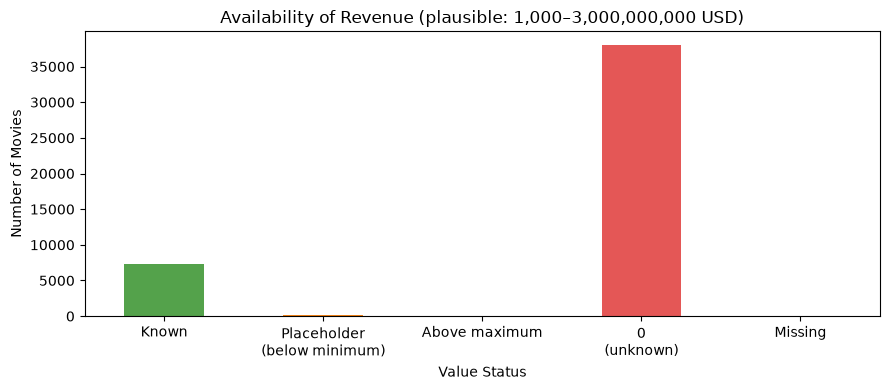

,Movies,Share (%)
Known,7244,15.94
Placeholder (below minimum),154,0.34
Above maximum,0,0.00
0 (unknown),38032,83.71
Missing,3,0.01


Movies with both budget and revenue known: 5,307


In [73]:
display(plot_money_availability(movies["revenue"], "Revenue", RESULT_FOLDER + "revenue/revenue_availability.png", MIN_REVENUE_USD, MAX_REVENUE_USD).round(2))
print(f"Movies with both budget and revenue known: {(movies['budget_usd'].notna() & movies['revenue_usd'].notna()).sum():,}")

### 11.2 Distribution of Revenue

The unfiltered distribution shows every positive revenue (0 means "unknown" and cannot be shown on a log scale), with the plausible limits as dotted lines. The filtered distribution only shows revenues within the limits.

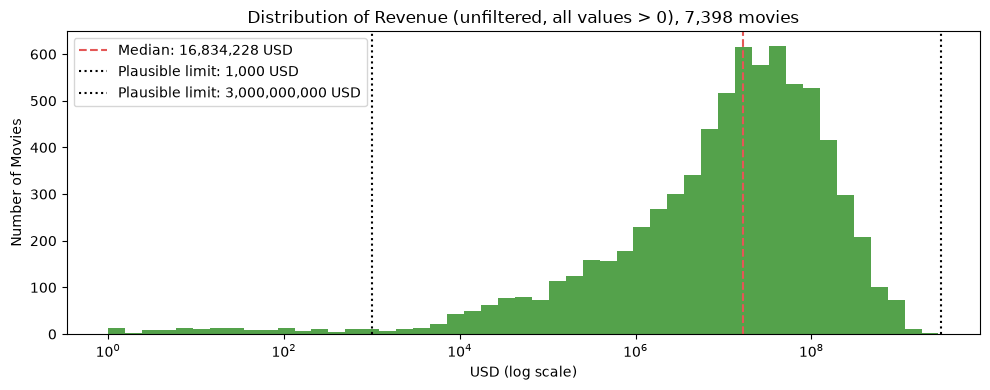

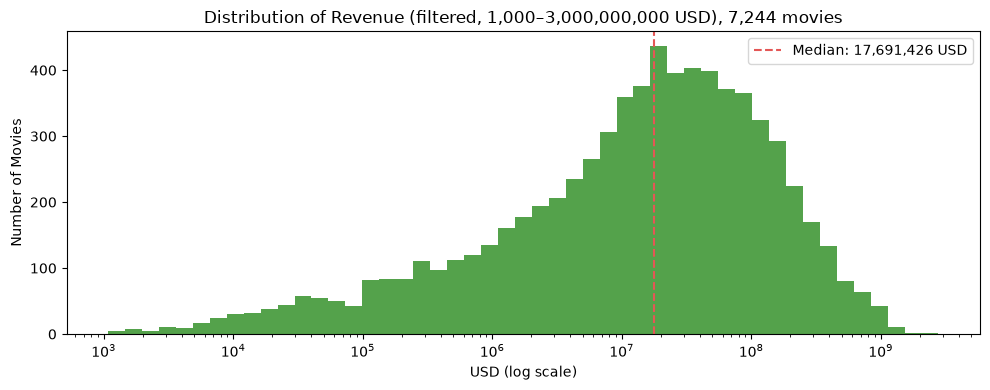

In [74]:
plot_money_distribution(
    movies["revenue"][movies["revenue"] > 0],
    title="Distribution of Revenue (unfiltered, all values > 0)",
    output_path=RESULT_FOLDER + "revenue/revenue_distribution_unfiltered.png",
    color="#54A24B",
    limits=(MIN_REVENUE_USD, MAX_REVENUE_USD)
)

plot_money_distribution(
    movies["revenue_usd"].dropna(),
    title=f"Distribution of Revenue (filtered, {MIN_REVENUE_USD:,}–{MAX_REVENUE_USD:,} USD)",
    output_path=RESULT_FOLDER + "revenue/revenue_distribution_filtered.png",
    color="#54A24B"
)

In [75]:
both_known = movies.dropna(subset=["budget_usd", "revenue_usd"])
revenue_to_budget = both_known["revenue_usd"] / both_known["budget_usd"]

display((movies["revenue_usd"].dropna() / 1e6).describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(2).rename("Revenue (million USD)").to_frame().T)
display(movies.nlargest(5, "revenue_usd")[["title", "release_year", "revenue_usd"]])
print(f"Median revenue / budget of the {len(both_known):,} movies with both values: {revenue_to_budget.median():.2f}")
print(f"Movies with a revenue below their budget: {100 * (revenue_to_budget < 1).mean():.1f}%")

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
Revenue (million USD),7244.0,70.32,147.71,0.0,0.28,2.95,17.69,69.33,185.67,774.51,2787.97


,title,release_year,revenue_usd
14544,Avatar,2009,2.787965e+09
26535,Star Wars: The Force Awakens,2015,2.068224e+09
1638,Titanic,1997,1.845034e+09
17808,The Avengers,2012,1.519558e+09
25064,Jurassic World,2015,1.513529e+09


Median revenue / budget of the 5,307 movies with both values: 2.07
Movies with a revenue below their budget: 29.6%


### 11.3 Average Revenue over Time

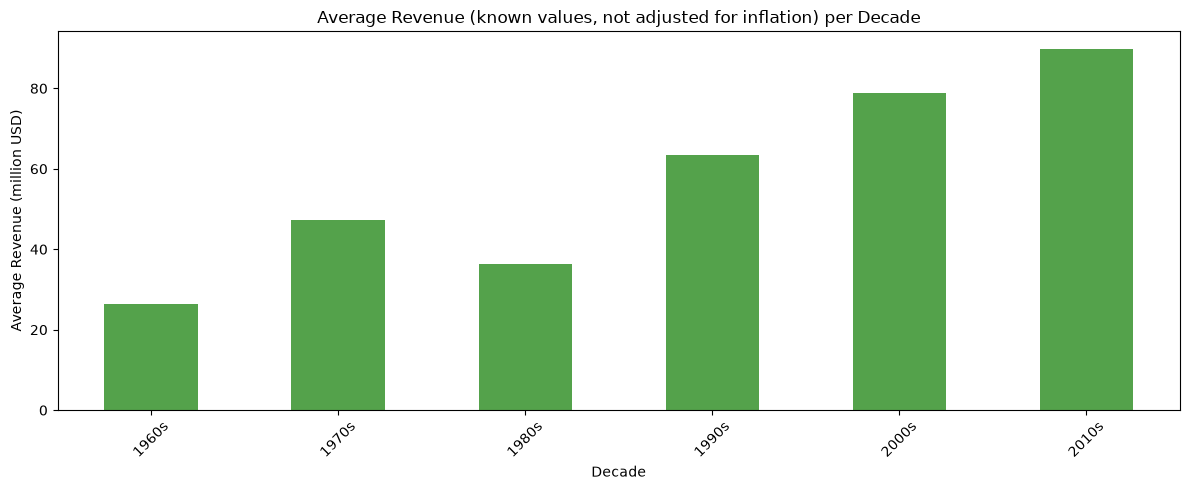

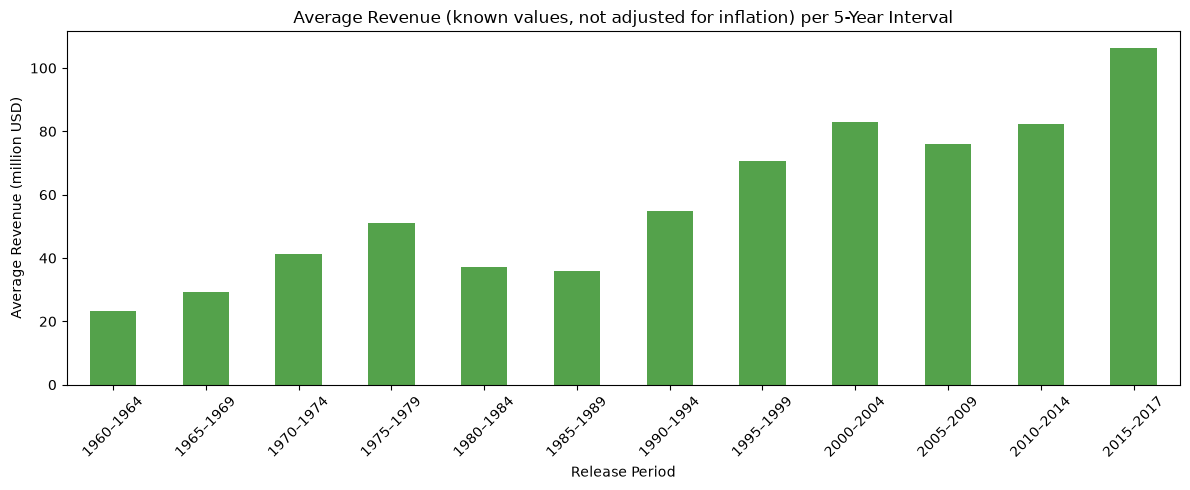

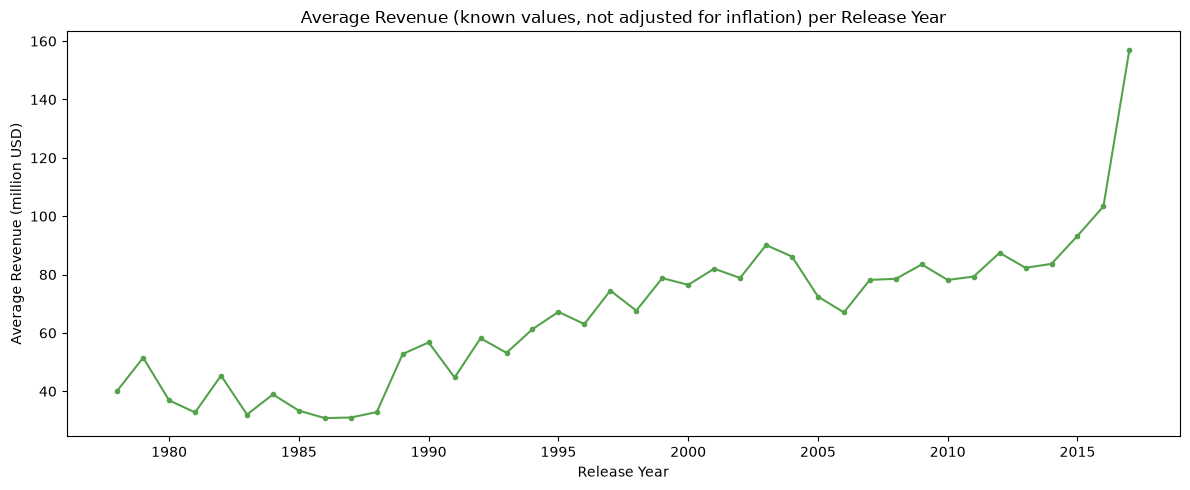

release_year,1960s,1970s,1980s,1990s,2000s,2010s
Mean,26.5,47.2,36.4,63.5,78.8,89.7
Movies,159.0,253.0,885.0,1300.0,2200.0,2244.0


In [76]:
dated_revenue = timeline[timeline["revenue_usd"].notna()]

revenue_per_decade = plot_average_over_time(
    dated_revenue["revenue_usd"] / 1e6,
    dated_revenue["release_year"],
    name="Revenue (known values, not adjusted for inflation)",
    ylabel="Average Revenue (million USD)",
    output_prefix=RESULT_FOLDER + "revenue/average_revenue",
    color="#54A24B"
)

display(revenue_per_decade.rename(index=decade_label).round(1).T)

In [77]:
median_revenue_per_decade = dated_revenue.groupby("decade")["revenue_usd"].median() / 1e6

display(median_revenue_per_decade[median_revenue_per_decade.index.isin(revenue_per_decade.index)].rename(index=decade_label).rename("Median revenue (million USD)").round(1).to_frame().T)

decade,1960s,1970s,1980s,1990s,2000s,2010s
Median revenue (million USD),11.7,24.9,14.4,17.6,26.8,15.2


**Key findings**

- Only 7,244 movies (15.9%) have a known revenue, and 5,307 movies have both a known budget and revenue.
- The known revenues are even more skewed than the budgets: the median is 17.7 million USD, the mean 70.3 million and the maximum 2.79 billion (*Avatar*).
- For the movies with both values, the median revenue is 2.07 times the budget, but 29.6% earn less than their budget.
- From the 1960s on, the average known revenue grew from 27 to 90 million USD in the 2010s, while the median stayed between 12 and 27 million. Revenue is mostly reported for commercially successful movies and is not adjusted for inflation, so these values describe the reported movies only.

## 12. Distribution of Votes

### 12.1 Vote Average

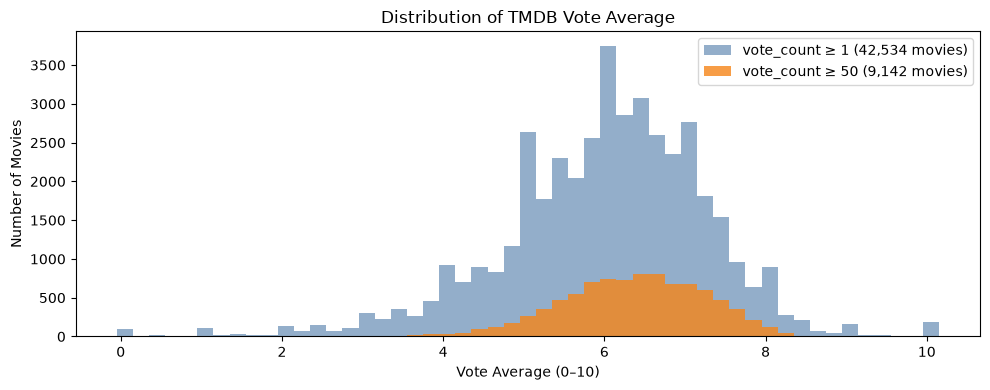

2896 movies have no votes; their vote_average is [0.]


In [78]:
voted = movies[movies["vote_count"] > 0]

ax = voted["vote_average"].plot(
    kind="hist",
    bins=np.arange(-0.05, 10.2, 0.2),
    figsize=(10, 4),
    alpha=0.6,
    color="#4C78A8",
    label=f"vote_count ≥ 1 ({len(voted):,} movies)",
    title="Distribution of TMDB Vote Average"
)

voted.loc[voted["vote_count"] >= MIN_VOTE_COUNT, "vote_average"].plot(
    kind="hist",
    bins=np.arange(-0.05, 10.2, 0.2),
    alpha=0.8,
    color="#F58518",
    label=f"vote_count ≥ {MIN_VOTE_COUNT} ({(voted['vote_count'] >= MIN_VOTE_COUNT).sum():,} movies)",
    ax=ax
)

ax.set_xlabel("Vote Average (0–10)")
ax.set_ylabel("Number of Movies")
ax.legend()
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "votes/vote_average_distribution.png", bbox_inches="tight")
plt.show()

print((movies["vote_count"] == 0).sum(), "movies have no votes; their vote_average is",
      movies.loc[movies["vote_count"] == 0, "vote_average"].unique())

In [79]:
reliable_votes = voted["vote_count"] >= MIN_VOTE_COUNT

display(pd.DataFrame({
    "vote_count ≥ 1": voted["vote_average"].describe(),
    f"vote_count ≥ {MIN_VOTE_COUNT}": voted.loc[reliable_votes, "vote_average"].describe()
}).round(2).T)
print(f"Vote average of 0 or 10: {100 * voted.loc[~reliable_votes, 'vote_average'].isin([0, 10]).mean():.1f}% of the movies with fewer than "
      f"{MIN_VOTE_COUNT} votes, {100 * voted.loc[reliable_votes, 'vote_average'].isin([0, 10]).mean():.1f}% of the others")

,count,mean,std,min,25%,50%,75%,max
vote_count ≥ 1,42534.0,6.00,1.29,0.0,5.3,6.1,6.8,10.0
vote_count ≥ 50,9142.0,6.36,0.89,0.0,5.8,6.4,7.0,9.5


Vote average of 0 or 10: 0.9% of the movies with fewer than 50 votes, 0.0% of the others


### 12.2 Vote Count

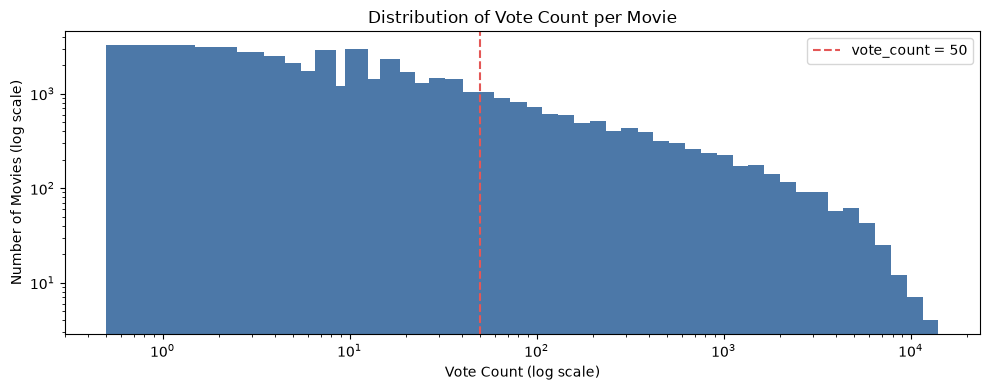

count    42534.0
mean       117.4
std        507.1
min          1.0
25%          4.0
50%         11.0
75%         38.0
90%        178.0
99%       2333.3
max      14075.0
Name: vote_count, dtype: float64

In [80]:
plot_log_histogram(
    voted["vote_count"],
    title="Distribution of Vote Count per Movie",
    xlabel="Vote Count (log scale)",
    ylabel="Number of Movies (log scale)",
    output_path=RESULT_FOLDER + "votes/vote_count_distribution.png",
    threshold=MIN_VOTE_COUNT,
    threshold_label=f"vote_count = {MIN_VOTE_COUNT}"
)

display(voted["vote_count"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1))

In [81]:
most_voted = voted["vote_count"].sort_values(ascending=False)

print(f"Movies with at least {MIN_VOTE_COUNT} votes: {(voted['vote_count'] >= MIN_VOTE_COUNT).sum():,} ({100 * (movies['vote_count'] >= MIN_VOTE_COUNT).mean():.1f}% of all movies)")
print(f"Share of all votes given to the 1% most voted movies: {100 * most_voted.head(len(most_voted) // 100).sum() / most_voted.sum():.1f}%")

Movies with at least 50 votes: 9,142 (20.1% of all movies)
Share of all votes given to the 1% most voted movies: 35.9%


### 12.3 Vote Count over Time

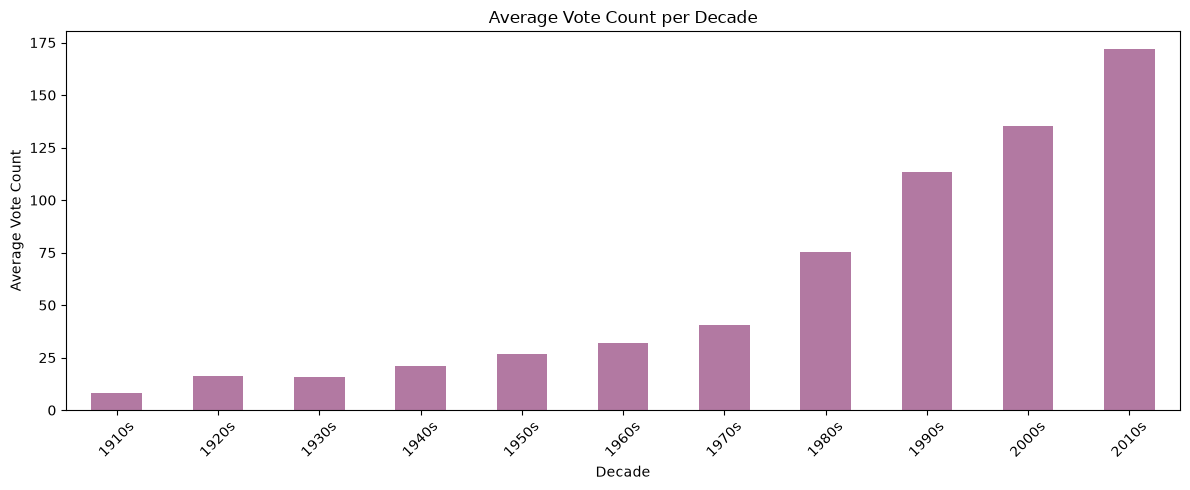

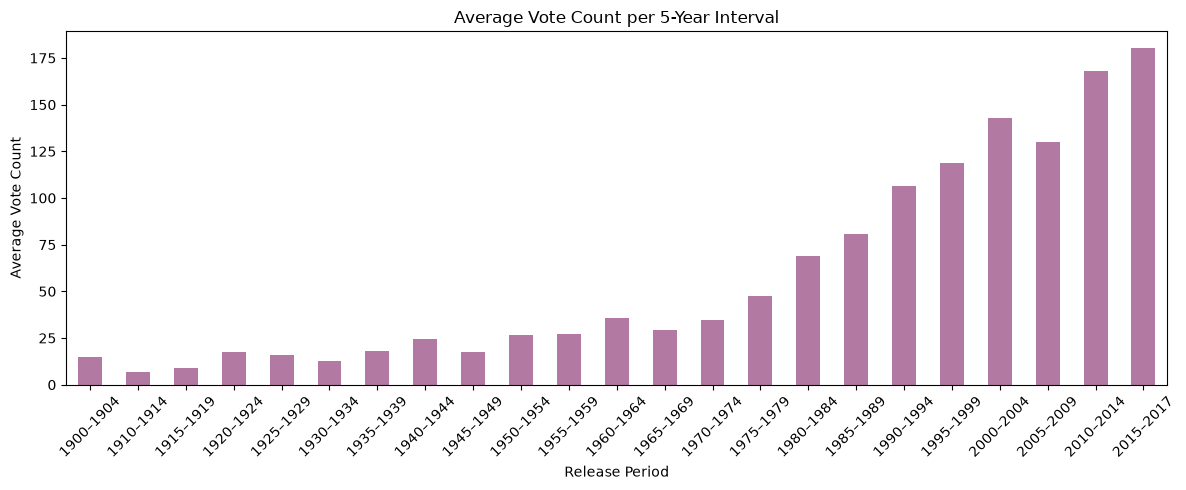

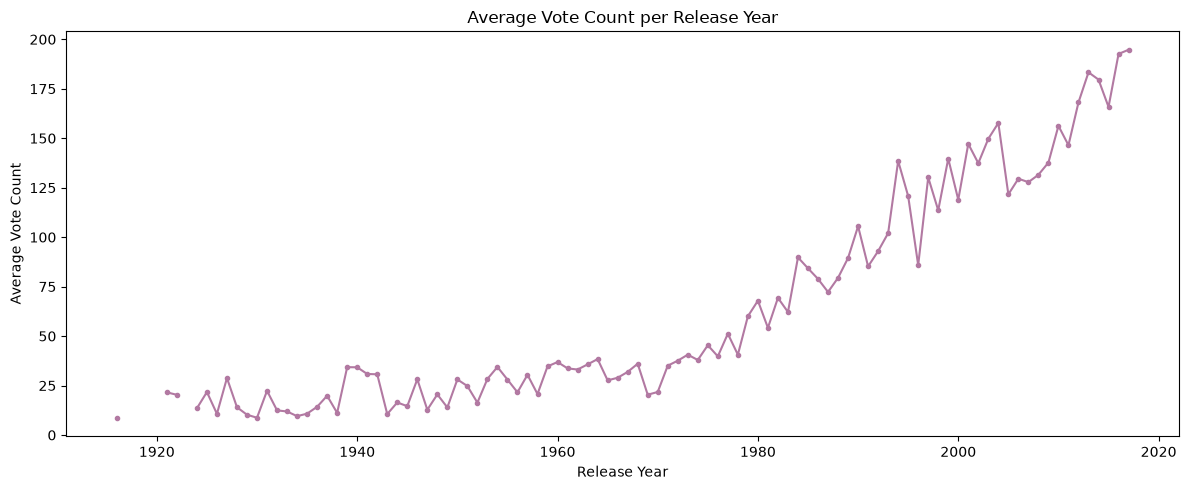

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean,8.1,16.4,15.6,21.1,26.8,32.0,40.8,75.2,113.5,135.3,171.8
Movies,176.0,431.0,1315.0,1493.0,2079.0,2621.0,3471.0,3928.0,5675.0,11195.0,12788.0


In [82]:
dated_votes = timeline[timeline["vote_count"].notna()]

vote_count_per_decade = plot_average_over_time(
    dated_votes["vote_count"],
    dated_votes["release_year"],
    name="Vote Count",
    ylabel="Average Vote Count",
    output_prefix=RESULT_FOLDER + "votes/average_vote_count",
    color="#B279A2"
)

display(vote_count_per_decade.rename(index=decade_label).round(1).T)

In [83]:
median_votes_per_decade = dated_votes.groupby("decade")["vote_count"].median()

display(median_votes_per_decade[median_votes_per_decade.index.isin(vote_count_per_decade.index)].rename(index=decade_label).rename("Median vote count").to_frame().T)

decade,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Median vote count,4.0,4.0,4.0,5.0,6.0,7.0,6.0,10.0,11.0,11.0,14.0


**Key findings**

- 2,896 movies have no votes, and their `vote_average` of 0 is not a real score.
- The vote count is extremely skewed: the median is 11 votes, the 99th percentile 2,333 and the maximum 14,075, and the 1% most voted movies have 35.9% of all votes. Only 9,142 movies (20.1%) have at least 50 votes.
- With at least one vote, the mean vote average is 6.00 (standard deviation 1.29). With at least 50 votes it is 6.36 with a much smaller spread (0.89), since averages of few votes are extreme, so vote averages should only be compared for movies with enough votes.
- The average vote count grows from 8 votes per movie in the 1910s to 172 in the 2010s (median 4 to 14). TMDB users mainly vote on recent movies, so older movies have less reliable vote averages.

## 13. Distribution of Release Status

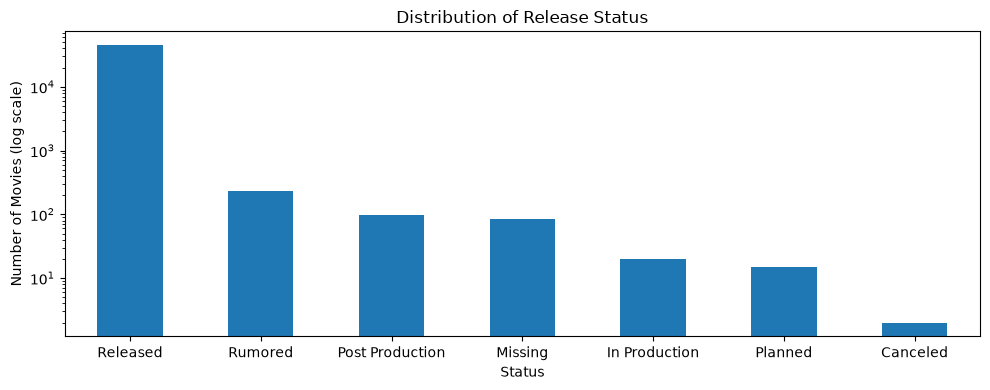

revenue_usd             vote_count       
                      count      median      count median
status                                                   
Canceled                  0         NaN          2    4.0
In Production             0         NaN         20   10.0
Missing                   1     97000.0         81    2.0
Planned                   0         NaN         15   10.0
Post Production           5   1066471.0         98    8.0
Released               7233  17752940.0      44985   10.0
Rumored                   5    273644.0        229    4.0

In [84]:
status_counts = movies["status"].fillna("Missing").value_counts()

ax = status_counts.plot(
    kind="bar",
    figsize=(10, 4),
    logy=True,
    title="Distribution of Release Status",
    xlabel="Status",
    rot=0
)

ax.set_ylabel("Number of Movies (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "release_status/release_status_distribution.png", bbox_inches="tight")
plt.show()

display(movies.groupby(movies["status"].fillna("Missing"))[["revenue_usd", "vote_count"]].agg(["count", "median"]).round(0))

In [85]:
display(pd.DataFrame({"Movies": status_counts, "Share (%)": 100 * status_counts / len(movies)}).round(2))
print(f"Movies that are not released but report a revenue: {(movies['status'].ne('Released') & movies['revenue_usd'].notna()).sum()}")

,Movies,Share (%)
status,,
Released,44985,99.01
Rumored,229,0.50
Post Production,98,0.22
Missing,84,0.18
In Production,20,0.04
Planned,15,0.03
Canceled,2,0.00


Movies that are not released but report a revenue: 11


**Key findings**

- 99.0% of the movies are *Released*. *Rumored* (229 movies), *Post Production* (98), *In Production* (20), *Planned* (15) and *Canceled* (2) are rare, and 84 movies have no status.
- 11 movies that are not released still report a revenue, which is inconsistent.

## 14. Distribution of Collections

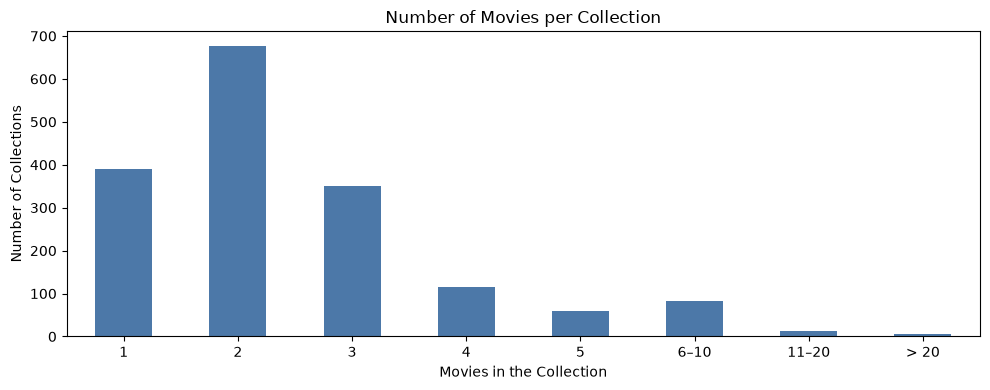

Movies in a collection: 4,488 (9.9%)
Distinct collections: 1,695


In [86]:
collection_sizes = movies["collection_name"].value_counts()

collection_size_bins = [0, 1, 2, 3, 4, 5, 10, 20, np.inf]
collection_size_labels = ["1", "2", "3", "4", "5", "6–10", "11–20", "> 20"]

collection_size_groups = (
    pd.cut(collection_sizes, bins=collection_size_bins, labels=collection_size_labels)
    .value_counts(sort=False)
)

ax = collection_size_groups.plot(
    kind="bar",
    figsize=(10, 4),
    color="#4C78A8",
    title="Number of Movies per Collection",
    xlabel="Movies in the Collection",
    ylabel="Number of Collections",
    rot=0
)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "collections/collection_size_distribution.png", bbox_inches="tight")
plt.show()

print(f"Movies in a collection: {movies['collection_name'].notna().sum():,} ({100 * movies['collection_name'].notna().mean():.1f}%)")
print(f"Distinct collections: {len(collection_sizes):,}")

In [87]:
display(collection_sizes.describe().round(2).rename("Movies per collection").to_frame().T)
print(f"Collections with exactly 2 movies: {100 * (collection_sizes == 2).mean():.1f}%")

,count,mean,std,min,25%,50%,75%,max
Movies per collection,1695.0,2.65,2.27,1.0,2.0,2.0,3.0,29.0


Collections with exactly 2 movies: 39.9%


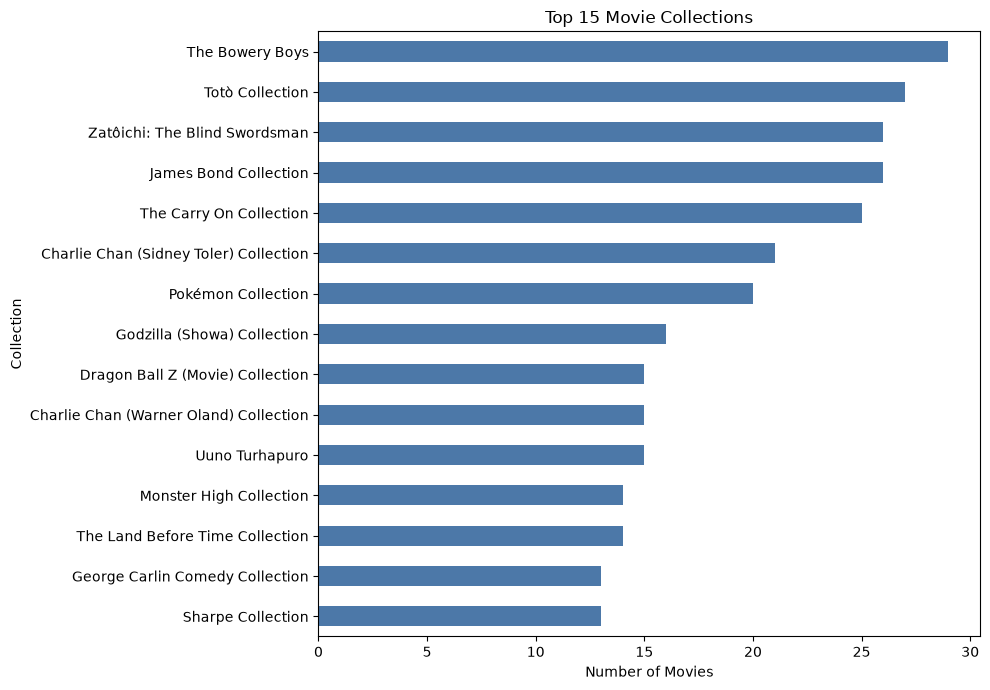

collection_name
The Bowery Boys                           29
Totò Collection                           27
James Bond Collection                     26
Zatôichi: The Blind Swordsman             26
The Carry On Collection                   25
Charlie Chan (Sidney Toler) Collection    21
Pokémon Collection                        20
Godzilla (Showa) Collection               16
Uuno Turhapuro                            15
Charlie Chan (Warner Oland) Collection    15
Dragon Ball Z (Movie) Collection          15
The Land Before Time Collection           14
Monster High Collection                   14
Sharpe Collection                         13
George Carlin Comedy Collection           13
Name: count, dtype: int64

In [88]:
collection_sizes = movies["collection_name"].value_counts()

ax = collection_sizes.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    color="#4C78A8",
    title="Top 15 Movie Collections",
    ylabel="Collection"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "collections/top_15_collections.png", bbox_inches="tight")
plt.show()

display(collection_sizes.head(15))

In [89]:
collection_comparison = (
    movies.assign(group=movies["collection_name"].notna().map({True: "In a collection", False: "Not in a collection"}))
    .groupby("group")
    .agg(**{
        "Movies": ("id", "size"),
        "Known revenue (%)": ("revenue_usd", lambda revenues: 100 * revenues.notna().mean()),
        "Median revenue (million USD)": ("revenue_usd", lambda revenues: revenues.median() / 1e6),
        "Median vote count": ("vote_count", "median"),
        "Mean vote average": ("vote_average", lambda averages: averages[movies.loc[averages.index, "vote_count"] >= MIN_VOTE_COUNT].mean())
    })
)

display(collection_comparison.round(2))

,Movies,Known revenue (%),Median revenue (million USD),Median vote count,Mean vote average
group,,,,,
In a collection,4488,32.75,67.99,36.0,6.17
Not in a collection,40945,14.10,12.80,9.0,6.42


**Key findings**

- 4,488 movies (9.9%) belong to one of 1,695 collections.
- Most collections are small: the median is 2 movies and 39.9% of the collections have exactly two. The largest are long-running older series such as *The Bowery Boys* (29 movies), *Totò* (27) and *James Bond* (26).
- Movies in a collection more often have a known revenue (32.8% compared with 14.1%), and they have a much higher median revenue (68.0 compared with 12.8 million USD) and vote count (36 compared with 9). Their mean vote average is slightly lower (6.17 compared with 6.42 for movies with at least 50 votes).

## 15. Availability of Text Fields

`overview` and `tagline` are the only free-text fields. How complete they are determines what text-based exploration and search can find.

In [90]:
placeholder_overviews = movies["overview"].str.strip().str.lower().isin(
    ["no overview found.", "no overview", "no movie overview available.", ""]
)

text_availability = pd.DataFrame({
    "Missing": [movies["overview"].isna().sum(), movies["tagline"].isna().sum()],
    "Placeholder text": [placeholder_overviews.sum(), 0],
    "Available": [
        (movies["overview"].notna() & ~placeholder_overviews).sum(),
        movies["tagline"].notna().sum()
    ]
}, index=["overview", "tagline"])

display(text_availability.assign(**{"Available (%)": 100 * text_availability["Available"] / len(movies)}).round(1))

overview_words = movies["overview"].dropna().str.split().map(len)
print(f"Median overview length: {overview_words.median():.0f} words")

,Missing,Placeholder text,Available,Available (%)
overview,954,149,44330,97.6
tagline,25032,0,20401,44.9


Median overview length: 48 words


**Key findings**

- An overview exists for 97.6% of the movies. 954 overviews are missing and 149 are placeholders such as "No overview found.".
- A tagline only exists for 44.9% of the movies.
- Overviews are short summaries (median 48 words), so a text search over them only finds movies whose theme is explicitly mentioned. For the same reason, keywords are often a more reliable thematic label than the free text.

## 16. Distribution of Cast

### 16.1 Cast Size

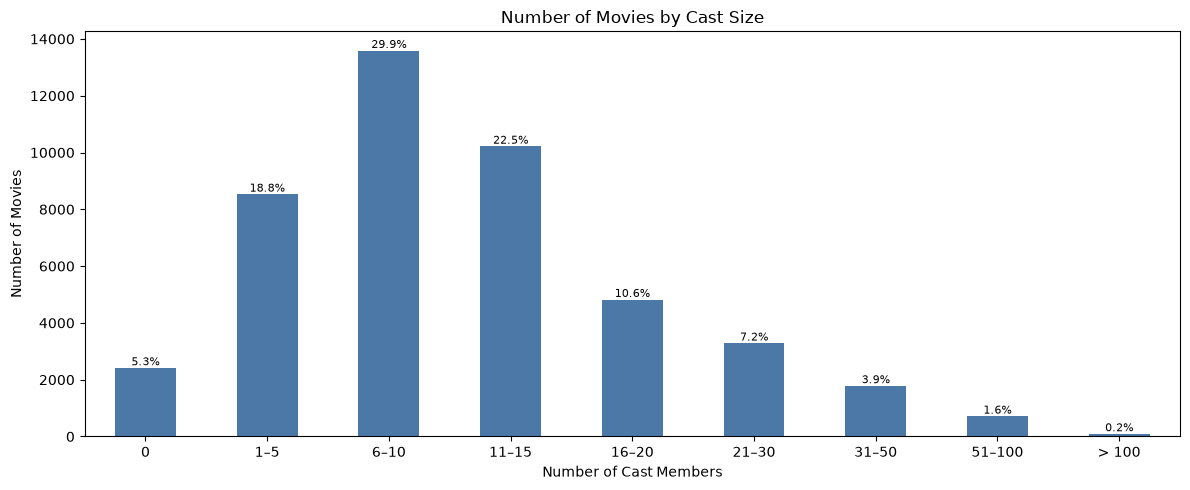

,n_cast,n_actors
count,45432.0,45432.0
mean,12.4,12.3
std,12.1,12.1
min,0.0,0.0
25%,6.0,6.0
50%,10.0,10.0
75%,15.0,15.0
max,313.0,312.0


2414 movies have no cast


In [91]:
size_bins = [-1, 0, 5, 10, 15, 20, 30, 50, 100, np.inf]
size_labels = ["0", "1–5", "6–10", "11–15", "16–20", "21–30", "31–50", "51–100", "> 100"]

plot_share_bar_chart(
    credits["n_cast"],
    bins=size_bins,
    labels=size_labels,
    title="Number of Movies by Cast Size",
    xlabel="Number of Cast Members",
    ylabel="Number of Movies",
    output_path=RESULT_FOLDER + "cast/cast_size_distribution.png",
    color="#4C78A8"
)

display(credits[["n_cast", "n_actors"]].describe().round(1))
print((credits["n_cast"] == 0).sum(), "movies have no cast")

In [92]:
print(f"Movies with more than 50 cast members: {(credits['n_cast'] > 50).sum():,} ({100 * (credits['n_cast'] > 50).mean():.1f}%)")
display(movies.nlargest(5, "n_cast")[["title", "release_year", "n_cast"]])

Movies with more than 50 cast members: 801 (1.8%)


,title,release_year,n_cast
925,Around the World in Eighty Days,1956,313.0
19089,Rock of Ages,2012,224.0
927,Mr. Smith Goes to Washington,1939,213.0
20051,Les Misérables,2012,208.0
39258,Jason Bourne,2016,208.0


### 16.2 Average Cast Size over Time

The average only includes movies with a cast, otherwise missing data would look like smaller casts. Every cast credit counts, so an actor with several roles counts once per role (see 20.2 for distinct actors).

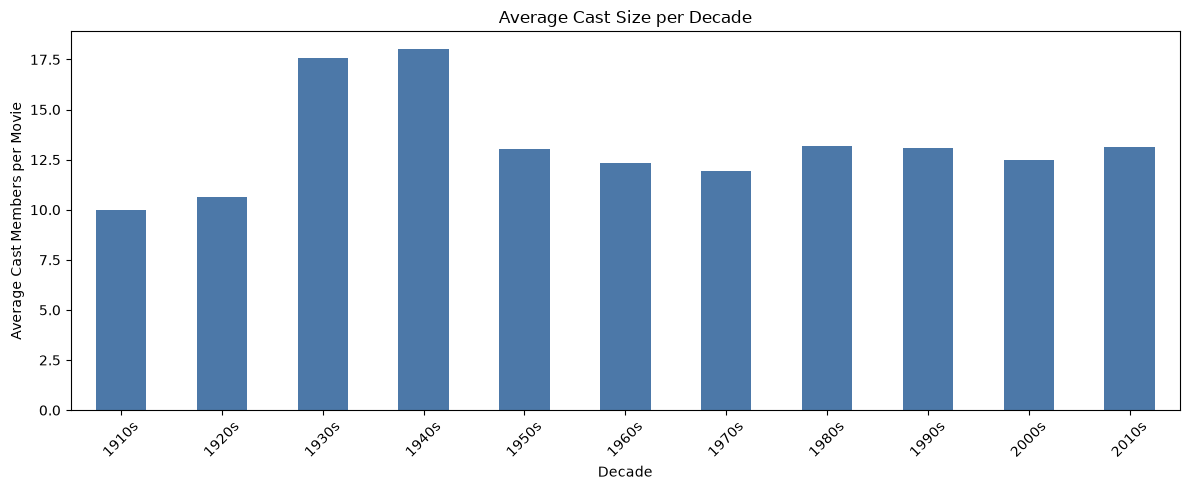

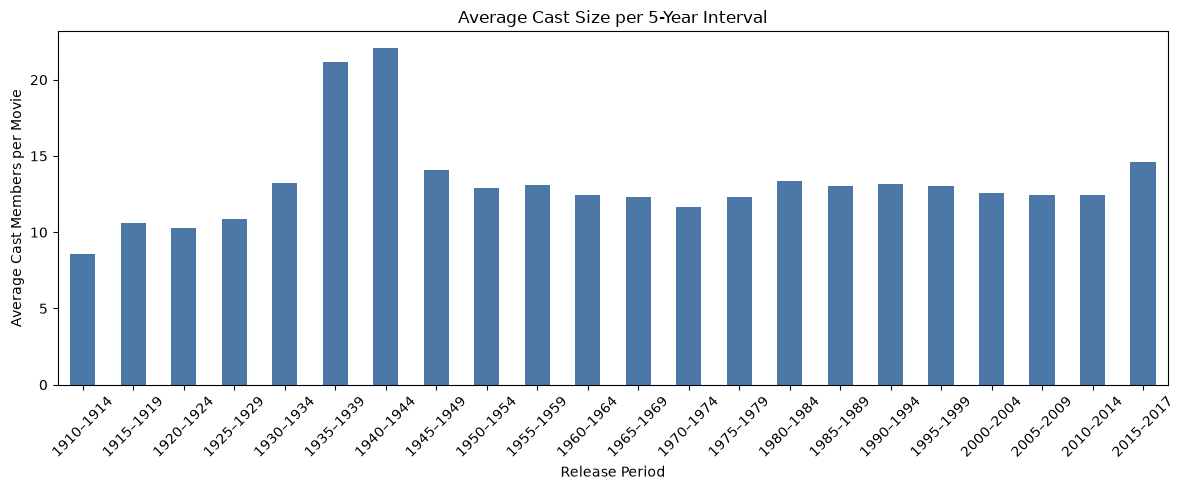

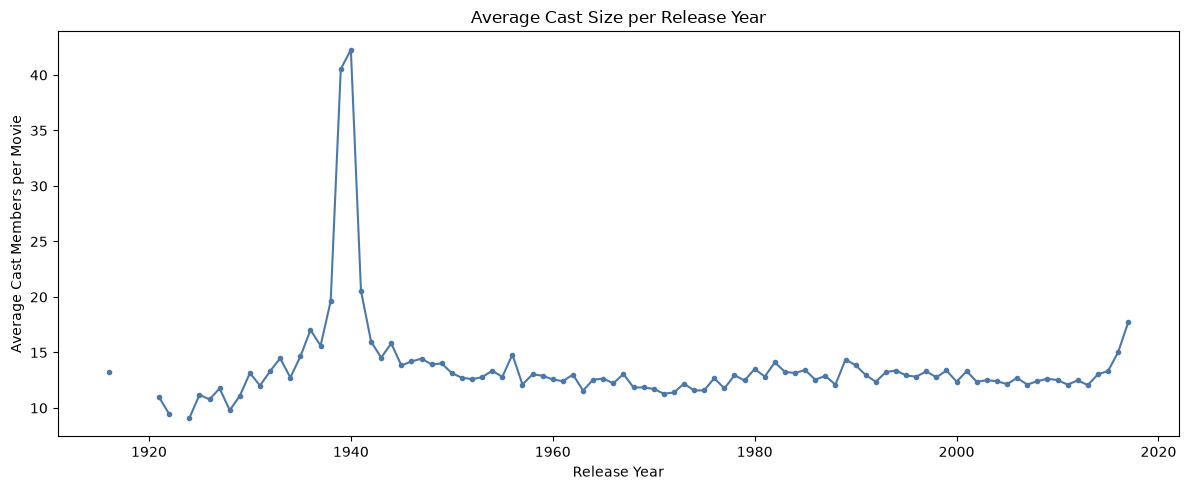

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean,9.96,10.64,17.58,18.0,13.02,12.35,11.94,13.2,13.09,12.48,13.13
Movies,166.00,407.00,1287.00,1463.0,2045.00,2540.00,3359.00,3782.0,5441.00,10471.00,11938.00


In [93]:
cast_movies = timeline[timeline["n_cast"].gt(0)]

cast_size_per_decade = plot_average_over_time(
    cast_movies["n_cast"],
    cast_movies["release_year"],
    name="Cast Size",
    ylabel="Average Cast Members per Movie",
    output_prefix=RESULT_FOLDER + "cast/average_cast_size",
    color="#4C78A8"
)

display(cast_size_per_decade.rename(index=decade_label).round(2).T)

**Key findings**

- 2,414 movies have no cast. The median cast has 10 members (mean 12.4), and 801 movies (1.8%) have more than 50. *Around the World in Eighty Days* (1956) has the largest cast with 313 members.
- The average cast grows from about 10 members per movie in the 1910s–1920s to 18 in the 1930s–1940s, the height of the studio era, when TMDB lists many uncredited extras and bit players. Since the 1950s it has stayed at 12–13.
- Cast size is therefore mostly a property of how completely TMDB lists the cast, not of how many people actually appear.

## 17. Distribution of Crew

### 17.1 Crew Size

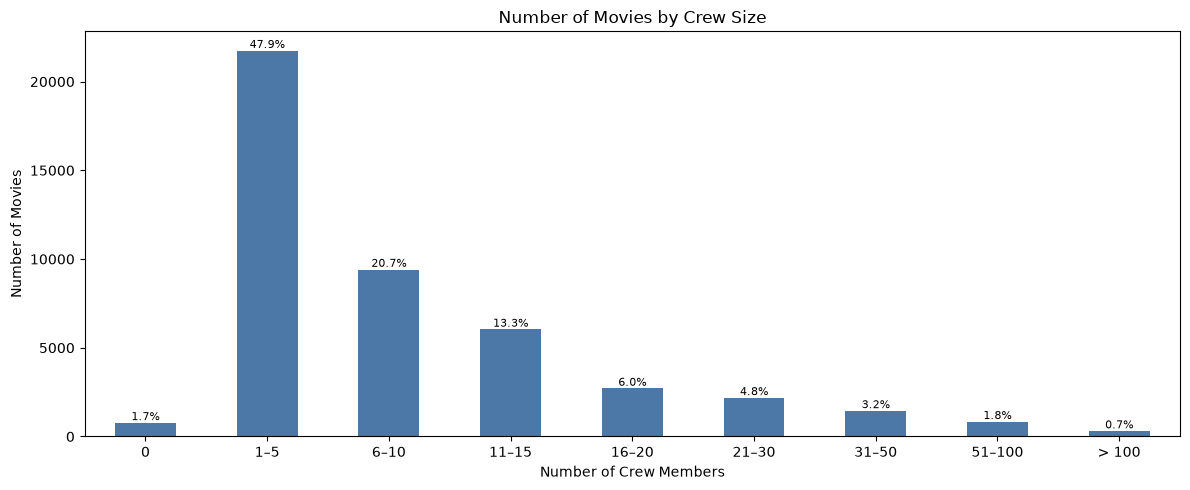

,n_crew,n_directors
count,45432.0,45432.0
mean,10.2,1.1
std,15.8,0.6
min,0.0,0.0
25%,2.0,1.0
50%,6.0,1.0
75%,12.0,1.0
max,435.0,42.0


771 movies have no crew


In [94]:
size_bins = [-1, 0, 5, 10, 15, 20, 30, 50, 100, np.inf]
size_labels = ["0", "1–5", "6–10", "11–15", "16–20", "21–30", "31–50", "51–100", "> 100"]

plot_share_bar_chart(
    credits["n_crew"],
    bins=size_bins,
    labels=size_labels,
    title="Number of Movies by Crew Size",
    xlabel="Number of Crew Members",
    ylabel="Number of Movies",
    output_path=RESULT_FOLDER + "crew/crew_size_distribution.png",
    color="#4C78A8"
)

display(credits[["n_crew", "n_directors"]].describe().round(1))
print((credits["n_crew"] == 0).sum(), "movies have no crew")

In [95]:
crew_lists = credits[credits["n_crew"] > 0]

print(f"Movies with more than 50 crew members: {(credits['n_crew'] > 50).sum():,} ({100 * (credits['n_crew'] > 50).mean():.1f}%)")
print(f"Movies with a crew but no director: {(crew_lists['n_directors'] == 0).sum():,} ({100 * (crew_lists['n_directors'] == 0).mean():.1f}% of the movies with a crew)")
display(movies.nlargest(5, "n_crew")[["title", "release_year", "n_crew"]])

Movies with more than 50 crew members: 1,140 (2.5%)
Movies with a crew but no director: 116 (0.3% of the movies with a crew)


,title,release_year,n_crew
25064,Jurassic World,2015,435.0
4040,15 Minutes,2001,338.0
44306,Valerian and the City of a Thousand Planets,2017,316.0
42139,Logan,2017,250.0
22115,The Wolf of Wall Street,2013,244.0


### 17.2 Average Crew Size over Time

The average only includes movies with a crew, otherwise missing data would look like smaller crews. Every crew credit counts, so a person with several jobs counts once per job.

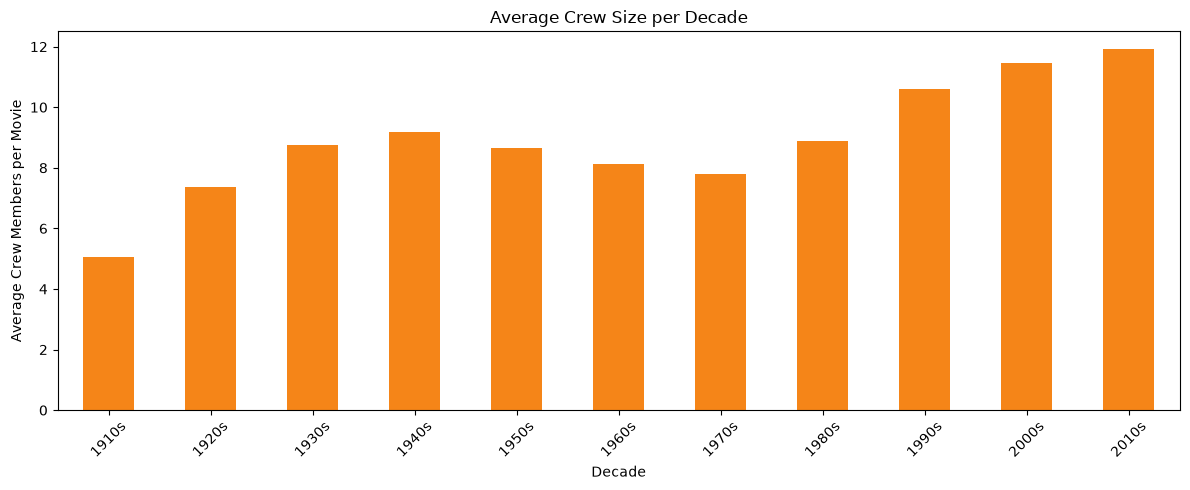

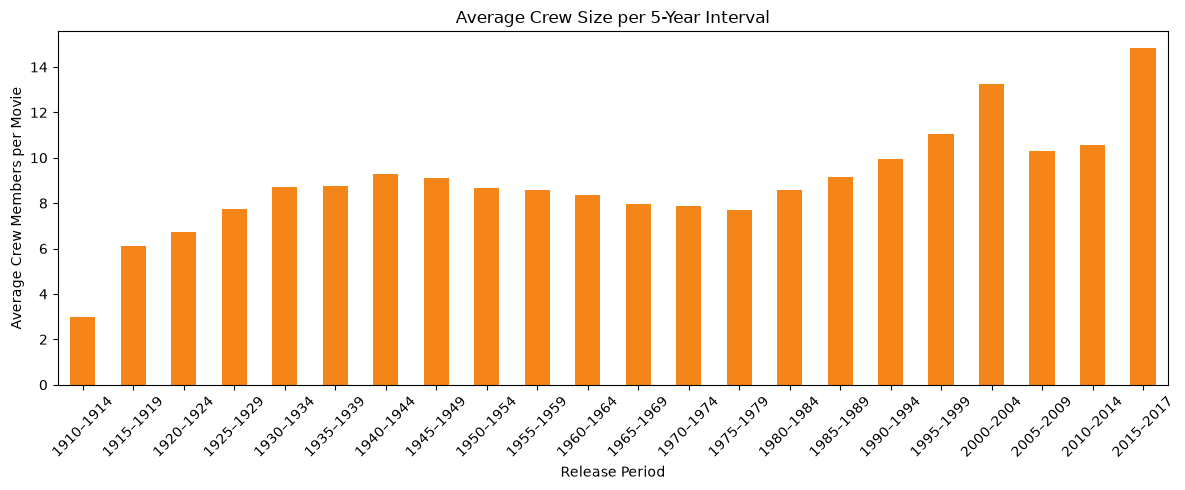

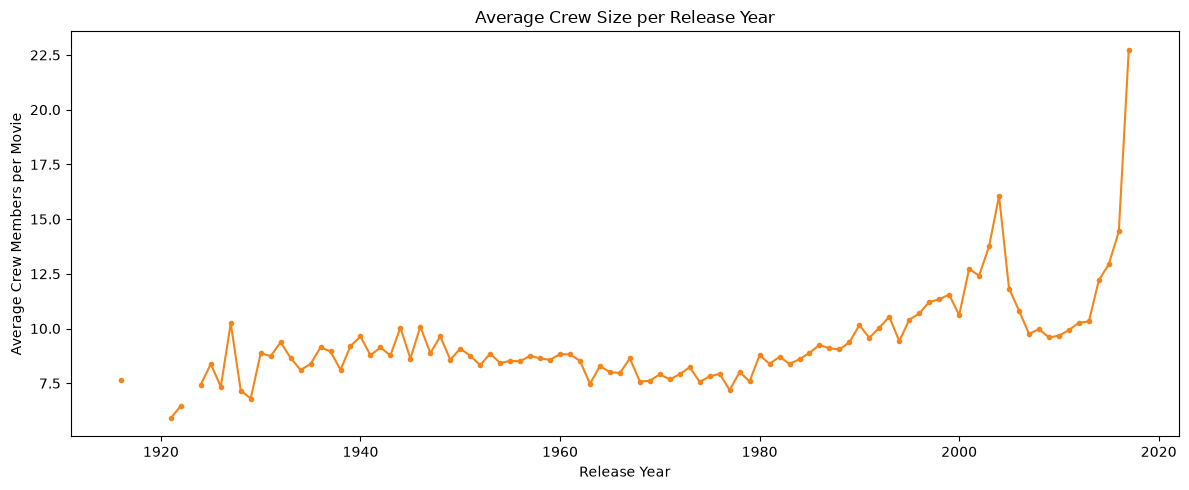

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean,5.06,7.37,8.75,9.2,8.64,8.13,7.79,8.88,10.6,11.47,11.91
Movies,176.00,430.00,1312.00,1491.0,2073.00,2613.00,3442.00,3895.00,5578.0,10868.00,12579.00


In [96]:
crew_movies = timeline[timeline["n_crew"].gt(0)]

crew_size_per_decade = plot_average_over_time(
    crew_movies["n_crew"],
    crew_movies["release_year"],
    name="Crew Size",
    ylabel="Average Crew Members per Movie",
    output_prefix=RESULT_FOLDER + "crew/average_crew_size",
    color="#F58518"
)

display(crew_size_per_decade.rename(index=decade_label).round(2).T)

**Key findings**

- 771 movies have no crew. The median crew has 6 members (mean 10.2), and 1,140 movies (2.5%) have more than 50. *Jurassic World* has the largest crew with 435 members.
- Almost every movie with a crew lists a director (only 116 do not).
- The average crew grows from 5 members per movie in the 1910s to 9 in the 1940s, dips to 8 in the 1960s–1970s and rises to 12 in the 2010s. Unlike the cast, the crew keeps growing, which reflects both larger productions and more complete crew lists for recent movies.

## 18. Distribution of Gender

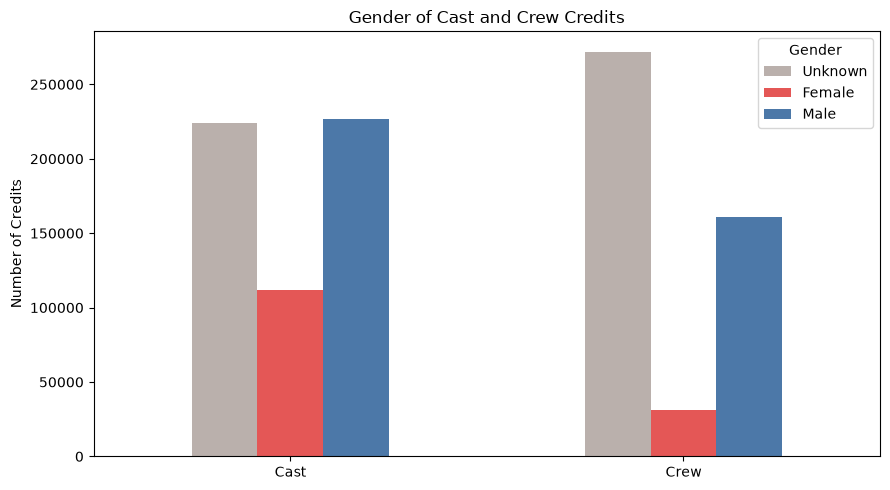

,Cast (%),Crew (%)
gender,,
Unknown,39.8,58.6
Female,19.9,6.7
Male,40.3,34.6


In [97]:
gender_counts = pd.DataFrame({
    "Cast": cast_members["gender"].map(GENDER_NAMES).value_counts(),
    "Crew": crew_members["gender"].map(GENDER_NAMES).value_counts()
}).reindex(list(GENDER_NAMES.values()))

ax = gender_counts.T.plot(
    kind="bar",
    figsize=(9, 5),
    color=GENDER_COLORS,
    title="Gender of Cast and Crew Credits",
    ylabel="Number of Credits",
    rot=0
)

ax.legend(title="Gender")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "gender/gender_distribution.png", bbox_inches="tight")
plt.show()

display((100 * gender_counts / gender_counts.sum()).round(1).rename(columns=lambda name: f"{name} (%)"))

In [98]:
known_gender_counts = gender_counts.loc[["Female", "Male"]]

display((100 * known_gender_counts.loc["Female"] / known_gender_counts.sum()).round(1).rename("Female among known genders (%)").to_frame().T)

,Cast,Crew
Female among known genders (%),33.0,16.2


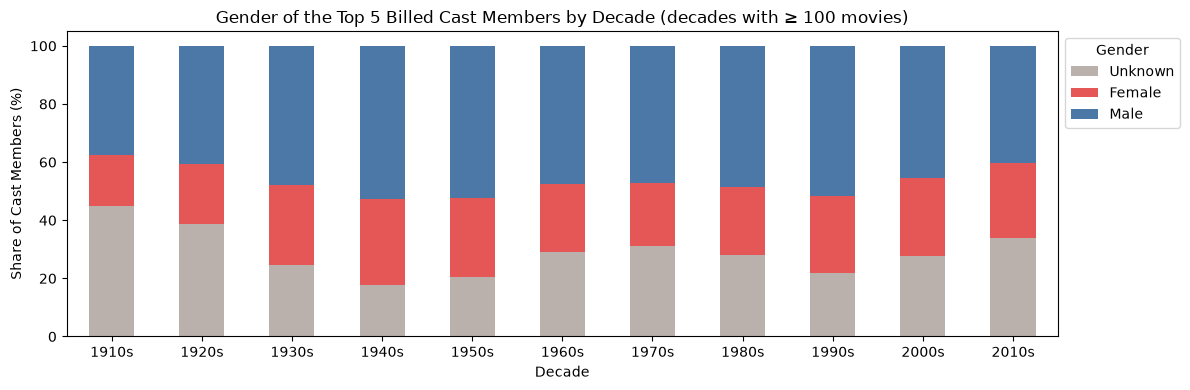

Movies where the cast order does not start at 0: 6,314


In [99]:
top_billed = (
    pd.DataFrame(
        [
            {"id": movie_id, "gender": member.get("gender", 0)}
            for movie_id, cast in zip(credits["id"], credits["cast"])
            for member in top_billed_cast(cast, TOP_BILLED_CAST)
        ]
    )
    .merge(movies[["id", "decade"]], on="id", how="inner")
    .dropna(subset=["decade"])
)

movies_per_decade_with_cast = top_billed.groupby("decade")["id"].nunique()
top_billed = top_billed[top_billed["decade"].map(movies_per_decade_with_cast) >= MIN_MOVIES_PER_DECADE]

top_billed_gender_by_decade = (
    pd.crosstab(top_billed["decade"].astype(int), top_billed["gender"].map(GENDER_NAMES), normalize="index")
    .reindex(columns=list(GENDER_NAMES.values()), fill_value=0)
    * 100
)
top_billed_gender_by_decade.index = top_billed_gender_by_decade.index.map(lambda decade: f"{decade}s")

ax = top_billed_gender_by_decade.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 4),
    color=GENDER_COLORS,
    title=f"Gender of the Top {TOP_BILLED_CAST} Billed Cast Members by Decade (decades with ≥ {MIN_MOVIES_PER_DECADE} movies)",
    xlabel="Decade",
    ylabel="Share of Cast Members (%)",
    rot=0
)

ax.legend(title="Gender", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "gender/top_billed_gender_by_decade.png", bbox_inches="tight")
plt.show()

movies_not_starting_at_zero = sum(1 for cast in credits["cast"] if cast and min(member["order"] for member in cast) != 0)
print(f"Movies where the cast order does not start at 0: {movies_not_starting_at_zero:,}")

In [100]:
display(top_billed_gender_by_decade.assign(**{
    "Female among known (%)": 100 * top_billed_gender_by_decade["Female"] / (top_billed_gender_by_decade["Female"] + top_billed_gender_by_decade["Male"])
}).round(1).T)

decade,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
gender,,,,,,,,,,,
Unknown,45.0,38.6,24.5,17.6,20.6,29.0,31.2,28.1,21.7,27.7,34.0
Female,17.4,20.6,27.6,29.8,27.1,23.4,21.5,23.4,26.8,26.7,25.5
Male,37.5,40.8,47.9,52.6,52.3,47.5,47.3,48.6,51.5,45.6,40.5
Female among known (%),31.7,33.6,36.6,36.1,34.1,33.0,31.2,32.5,34.2,37.0,38.7


### 18.1 Female and Male Cast Members over Time

Every actor counts once per movie, even with several roles. Credits with an unknown gender are left out, and so are periods with fewer movies than the minimum in 1.3. The table shows the female share among the known genders per decade.

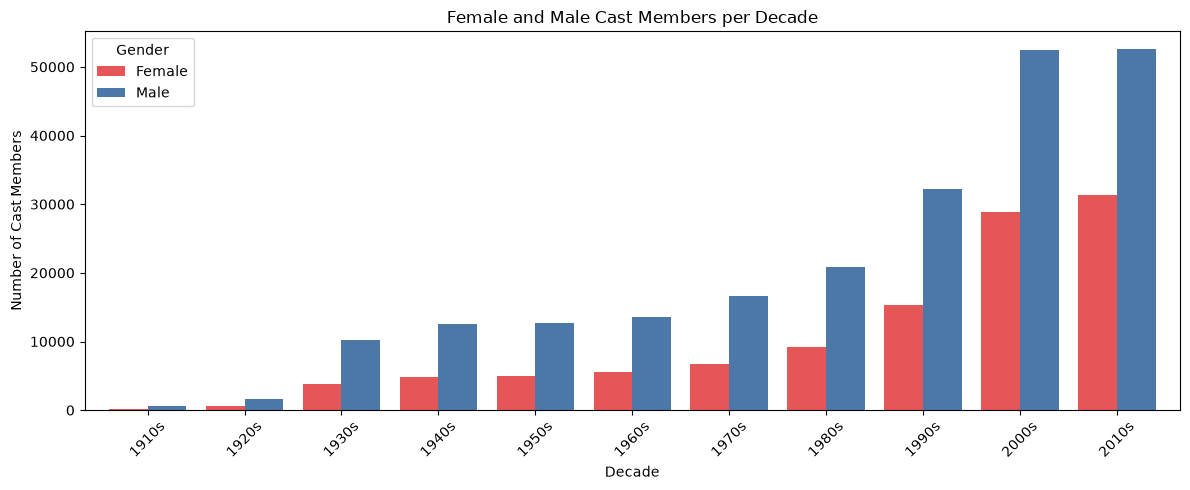

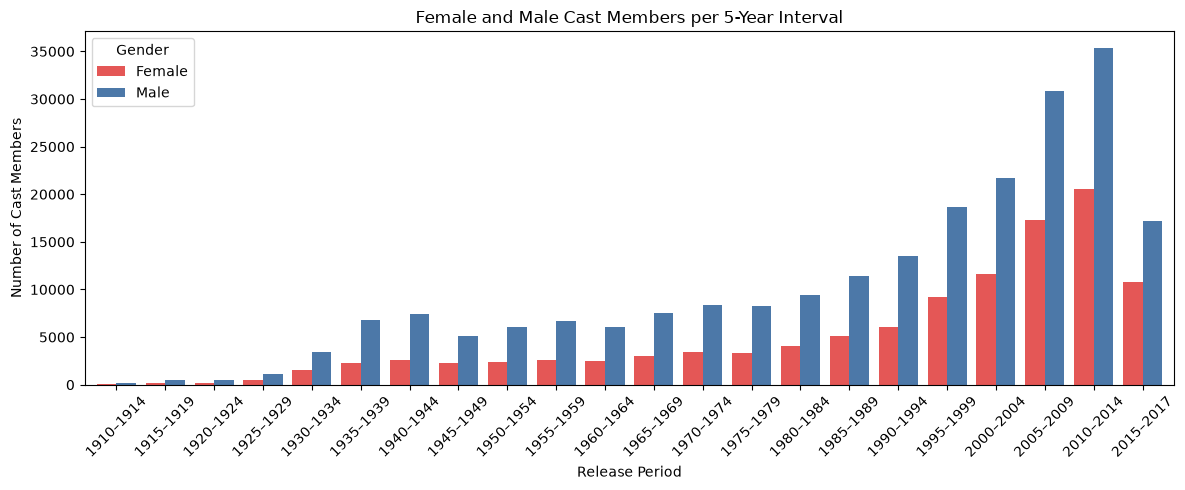

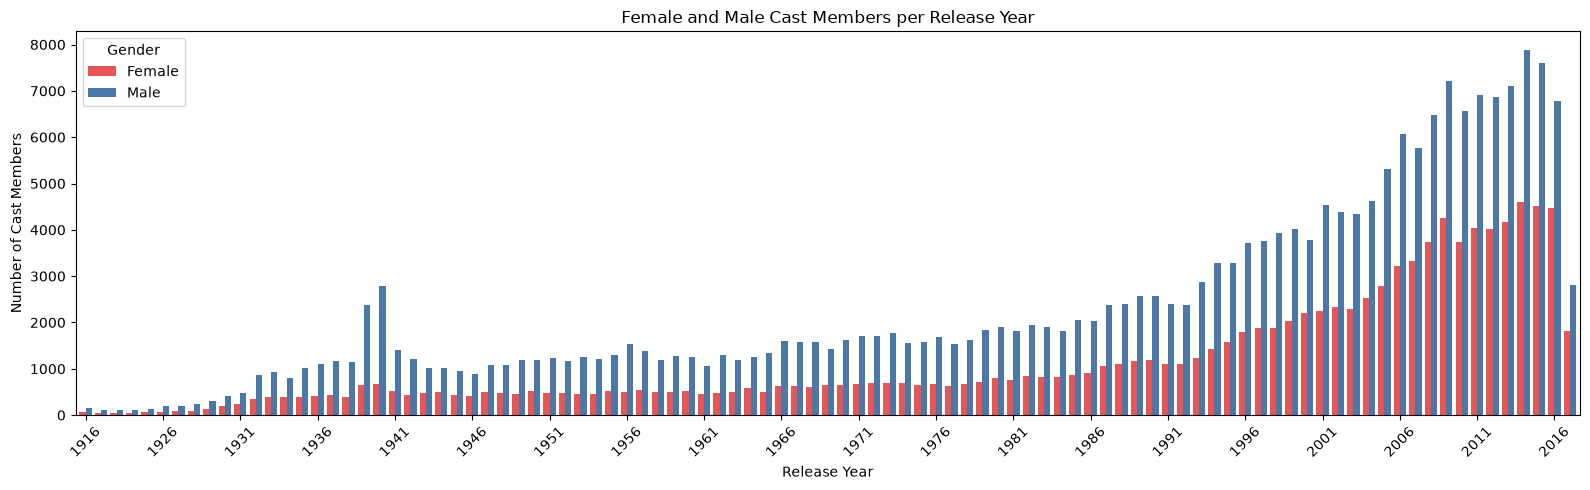

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
gender,,,,,,,,,,,
Female,224.0,673.0,3834.0,4887.0,4953.0,5530.0,6729.0,9152.0,15252.0,28897.0,31389.0
Male,595.0,1585.0,10260.0,12587.0,12691.0,13572.0,16653.0,20810.0,32218.0,52510.0,52548.0
Female (%),27.4,29.8,27.2,28.0,28.1,28.9,28.8,30.5,32.1,35.5,37.4


In [101]:
release_year_by_movie = timeline.set_index("id")["release_year"]

cast_gender = (
    cast_members.drop_duplicates(["movie_id", "id"])[["movie_id", "id", "gender"]]
    .assign(release_year=lambda data: data["movie_id"].map(release_year_by_movie))
    .dropna(subset=["release_year"])
    .astype({"release_year": int})
)

cast_gender_per_decade = plot_gender_over_time(
    cast_gender,
    name="Cast Members",
    output_prefix=RESULT_FOLDER + "gender/cast_gender"
)

display(cast_gender_per_decade.rename(index=decade_label).round(1).T)

### 18.2 Female and Male Crew Members over Time

Every crew member counts once per movie, even with several jobs.

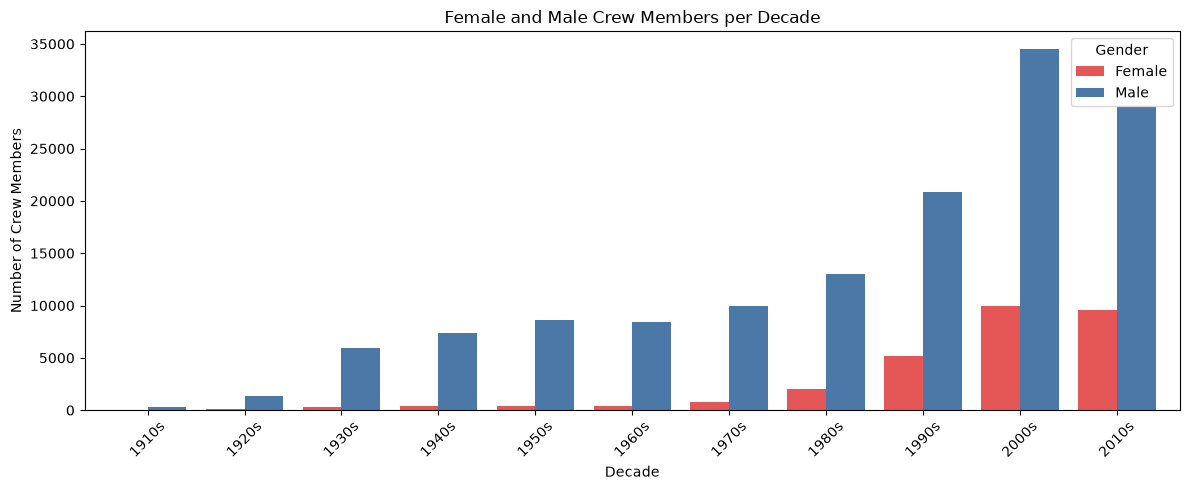

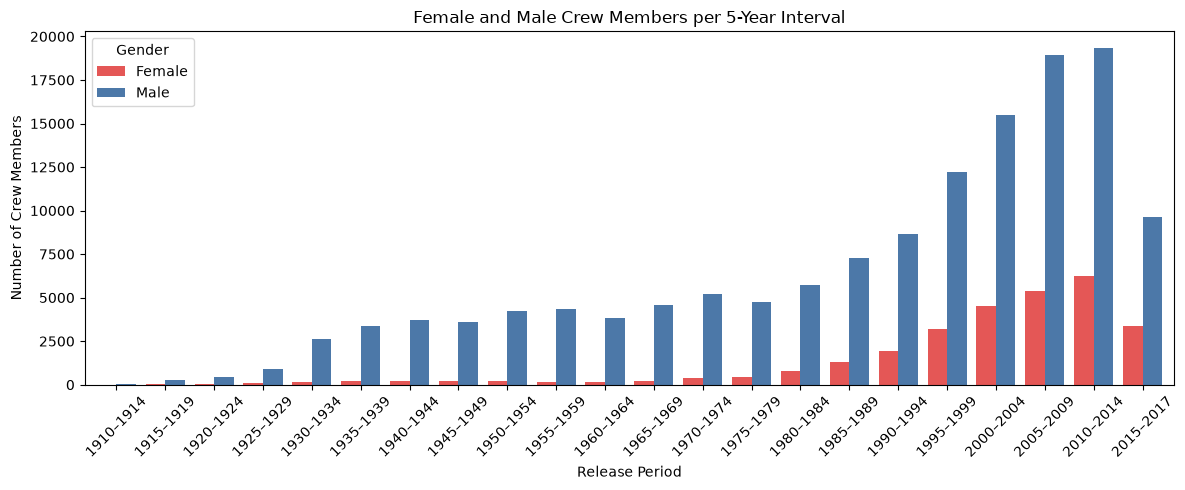

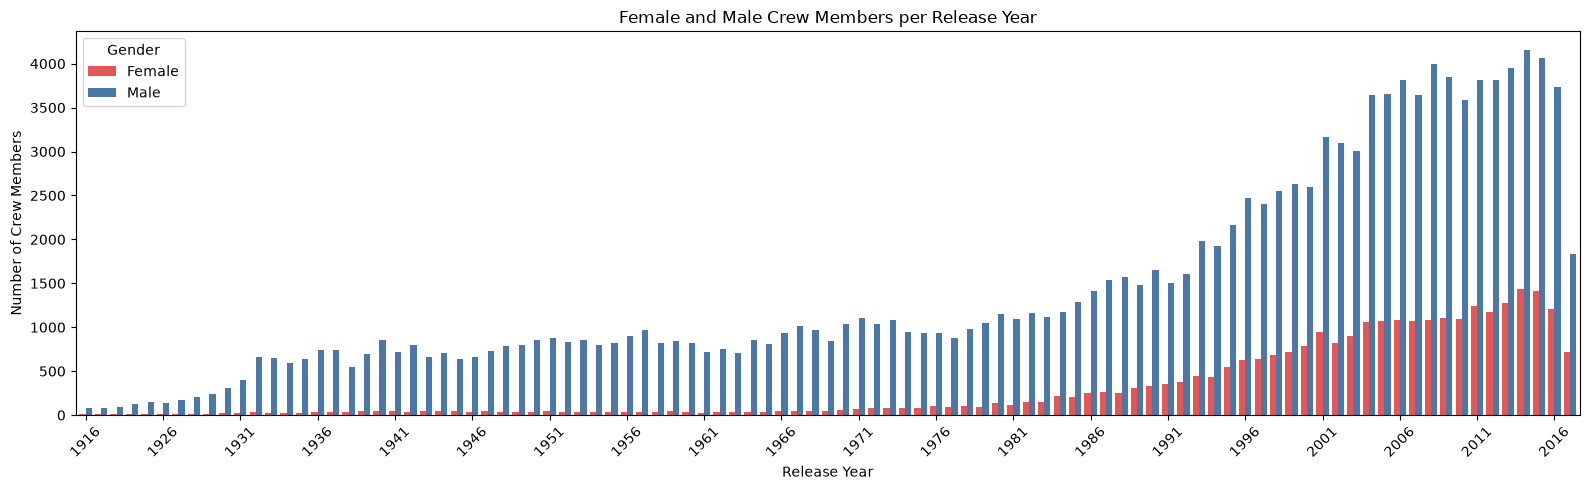

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
gender,,,,,,,,,,,
Female,33.0,101.0,321.0,433.0,381.0,397.0,827.0,2063.0,5155.0,9926.0,9573.0
Male,299.0,1340.0,5985.0,7341.0,8573.0,8410.0,9969.0,13008.0,20880.0,34478.0,28951.0
Female (%),9.9,7.0,5.1,5.6,4.3,4.5,7.7,13.7,19.8,22.4,24.8


In [102]:
crew_gender = (
    crew_members.drop_duplicates(["movie_id", "id"])[["movie_id", "id", "gender"]]
    .assign(release_year=lambda data: data["movie_id"].map(release_year_by_movie))
    .dropna(subset=["release_year"])
    .astype({"release_year": int})
)

crew_gender_per_decade = plot_gender_over_time(
    crew_gender,
    name="Crew Members",
    output_prefix=RESULT_FOLDER + "gender/crew_gender"
)

display(crew_gender_per_decade.rename(index=decade_label).round(1).T)

### 18.3 Crew Departments and Jobs

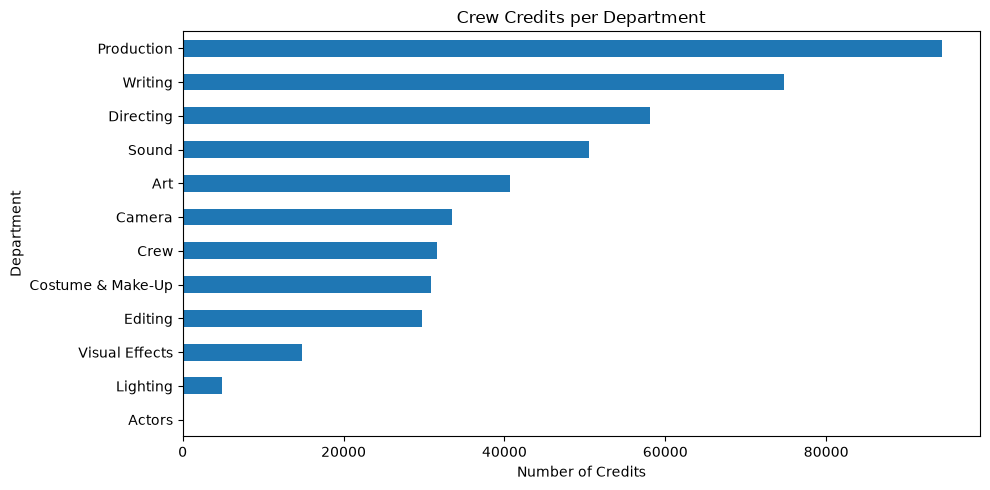

job
Director                   48999
Producer                   43507
Writer                     30398
Screenplay                 25143
Editor                     23770
Director of Photography    20640
Executive Producer         18853
Original Music Composer    15773
Casting                    12620
Art Direction              11679
Name: count, dtype: int64

In [103]:
ax = crew_members["department"].value_counts().sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    title="Crew Credits per Department",
    ylabel="Department"
)

ax.set_xlabel("Number of Credits")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "crew/crew_department_distribution.png", bbox_inches="tight")
plt.show()

display(crew_members["job"].value_counts().head(10))

In [104]:
department_counts = crew_members["department"].value_counts()
known_crew = crew_members[crew_members["gender"].map(GENDER_NAMES).isin(["Female", "Male"])]

display(pd.DataFrame({
    "Credits": department_counts,
    "Share (%)": 100 * department_counts / len(crew_members),
    "Female among known genders (%)": 100 * known_crew.groupby("department")["gender"].apply(lambda genders: genders.map(GENDER_NAMES).eq("Female").mean())
}).round(1))

,Credits,Share (%),Female among known genders (%)
department,,,
Actors,19,0.0,25.0
Art,40652,8.8,19.9
Camera,33506,7.2,2.8
Costume & Make-Up,30823,6.6,63.4
Crew,31572,6.8,11.6
Directing,58073,12.5,10.0
Editing,29795,6.4,15.9
Lighting,4846,1.0,3.0
Production,94401,20.4,26.7


**Key findings**

- The gender is unknown for 39.8% of the cast credits and 58.6% of the crew credits, so gender shares must be computed over the known genders only.
- Among the known genders, 33.0% of the cast credits and 16.2% of the crew credits are female.
- The female share of the cast stays at 27–30% until the 1970s and rises to 37% in the 2010s. Among the top-billed cast it is slightly higher (31–39%), but 18–45% of the top-billed cast has an unknown gender in every decade.
- The crew is far more male-dominated: the female share falls from 10% in the 1910s to 4–6% in the 1930s–1960s and only rises from the 1970s, to 25% in the 2010s. It ranges from 3% in Camera and Lighting to 63% in Costume & Make-Up.
- Production, Writing and Directing have most crew credits, and `Director` is the most common job (48,999 credits). In 6,314 movies the billing `order` does not start at 0, so the top-billed cast must be found by sorting on `order`.

## 19. Distribution of Directors

### 19.1 Number of Movies per Director

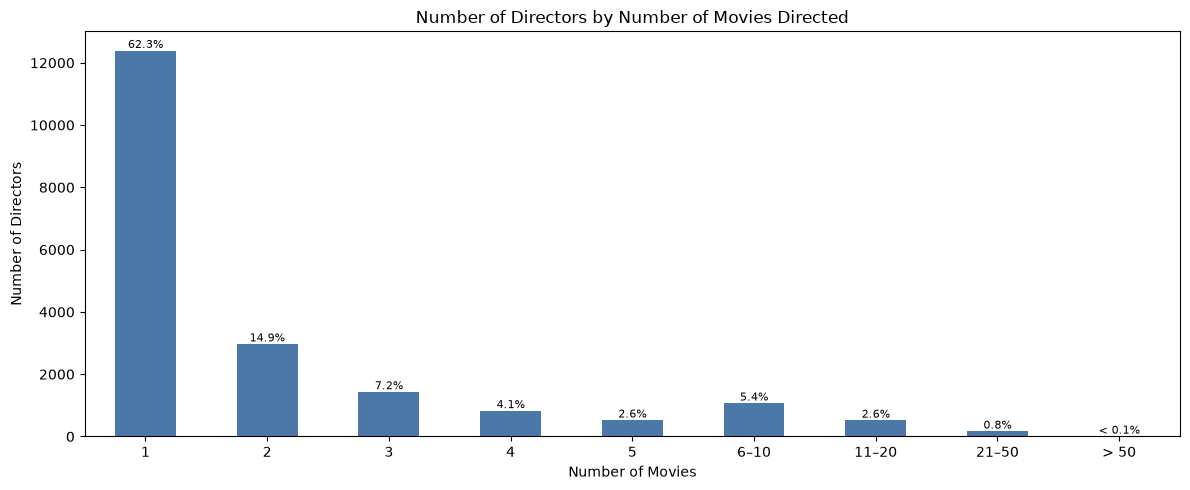

Distinct directors: 19,895
Mean movies per director: 2.46
Movies with more than one director: 3,195
Movies without a director: 887
Director names shared by more than one person id: 148


In [105]:
movies_per_director = directors.groupby("id")["movie_id"].nunique()

plot_share_bar_chart(
    movies_per_director,
    bins=MOVIE_COUNT_BINS,
    labels=MOVIE_COUNT_LABELS,
    title="Number of Directors by Number of Movies Directed",
    xlabel="Number of Movies",
    ylabel="Number of Directors",
    output_path=RESULT_FOLDER + "directors/movies_per_director_distribution.png"
)

print(f"Distinct directors: {len(movies_per_director):,}")
print(f"Mean movies per director: {movies_per_director.mean():.2f}")
print(f"Movies with more than one director: {(credits['n_directors'] > 1).sum():,}")
print(f"Movies without a director: {(credits['n_directors'] == 0).sum():,}")

director_names_per_id = directors.groupby("name")["id"].nunique()
print(f"Director names shared by more than one person id: {(director_names_per_id > 1).sum():,}")

In [106]:
display(movies_per_director.describe(percentiles=[0.5, 0.75, 0.9, 0.99]).round(1).rename("Movies per director").to_frame().T)
display(movies_per_director.nlargest(10).rename(index=person_names).rename_axis("Director").to_frame("Movies"))

,count,mean,std,min,50%,75%,90%,99%,max
Movies per director,19895.0,2.5,3.7,1.0,1.0,2.0,5.0,19.0,68.0


,Movies
Director,
John Ford,68
Michael Curtiz,65
Werner Herzog,55
Alfred Hitchcock,53
Georges Méliès,51
Jean-Luc Godard,50
Woody Allen,49
Sidney Lumet,46
Charlie Chaplin,44


### 19.2 Average Number of Directors per Movie over Time

The average only includes movies with a crew, otherwise missing data would look like fewer directors.

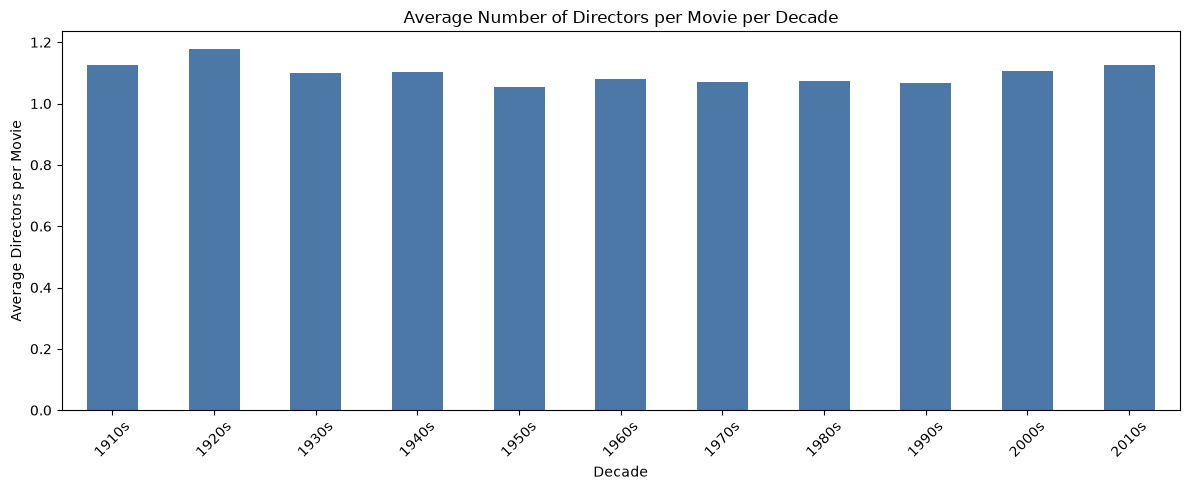

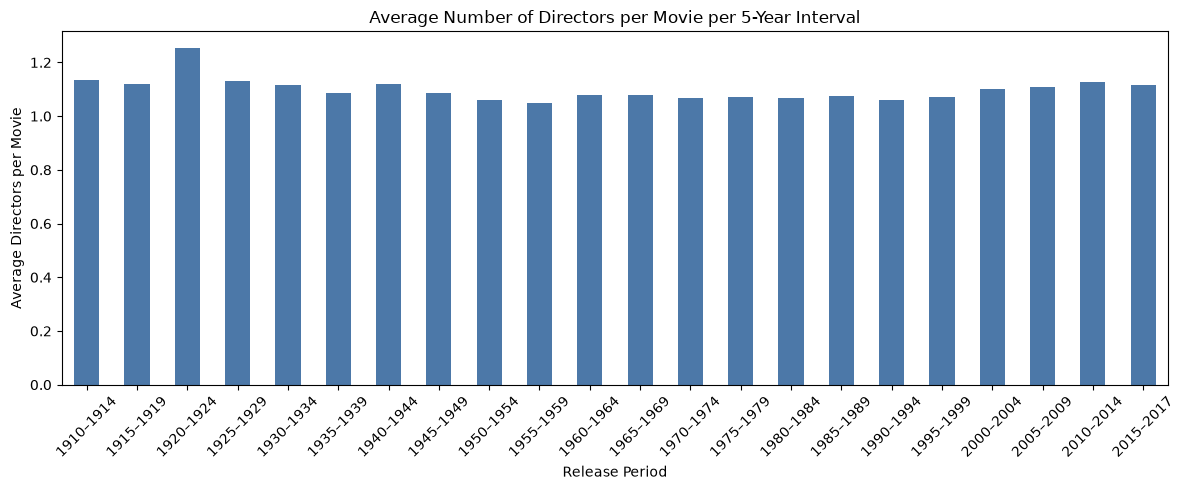

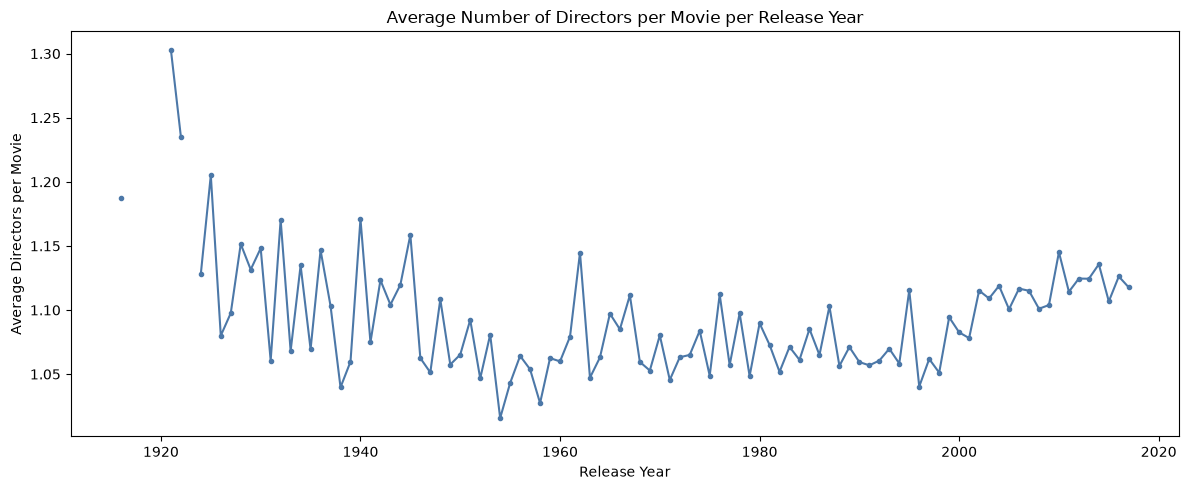

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean,1.12,1.18,1.1,1.1,1.05,1.08,1.07,1.07,1.07,1.11,1.12
Movies,176.00,430.00,1312.0,1491.0,2073.00,2613.00,3442.00,3895.00,5578.00,10868.00,12579.00


In [107]:
directors_movies = timeline[timeline["n_crew"].gt(0)]

directors_per_movie_per_decade = plot_average_over_time(
    directors_movies["n_directors"],
    directors_movies["release_year"],
    name="Number of Directors per Movie",
    ylabel="Average Directors per Movie",
    output_prefix=RESULT_FOLDER + "directors/average_directors_per_movie",
    color="#4C78A8"
)

display(directors_per_movie_per_decade.rename(index=decade_label).round(2).T)

**Key findings**

- There are 19,895 directors. 62.3% of them have only one movie (2.46 on average, 19 at the 99th percentile), and only 0.9% have more than 20.
- The directors with most movies are John Ford (68), Michael Curtiz (65) and Werner Herzog (55).
- 3,195 movies have several directors and 887 have none. The average stays between 1.05 and 1.18 directors per movie in every decade.
- 148 director names belong to more than one person, so directors must be grouped by `id` and not by `name`.

## 20. Distribution of Actors

### 20.1 Number of Movies per Actor

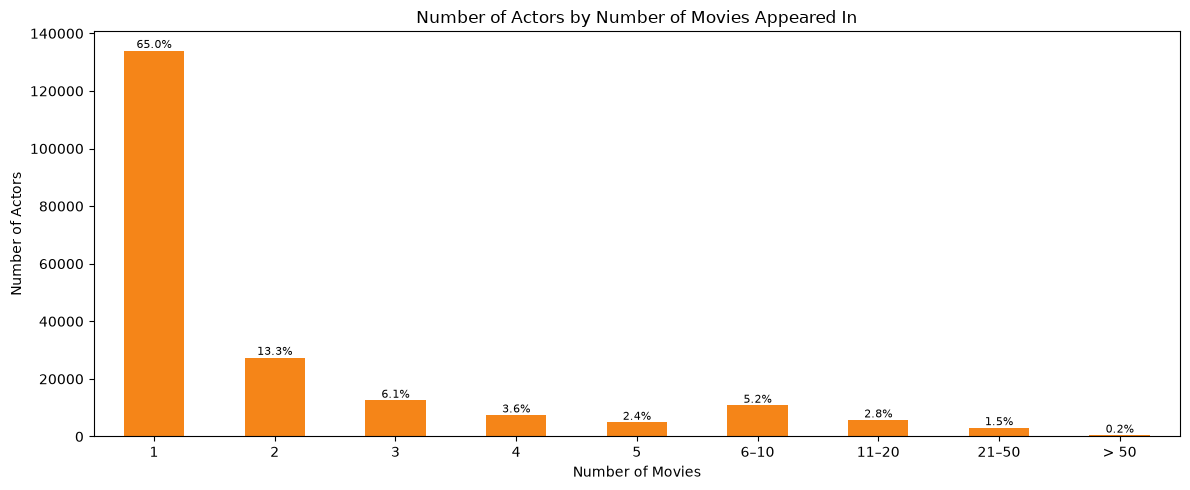

Distinct actors: 206,158
Mean movies per actor: 2.72


Actor names shared by more than one person id: 3,053
Repeated (movie, actor) credits, e.g. one actor playing several characters: 1,207


In [108]:
movies_per_actor = cast_members.groupby("id")["movie_id"].nunique()

plot_share_bar_chart(
    movies_per_actor,
    bins=MOVIE_COUNT_BINS,
    labels=MOVIE_COUNT_LABELS,
    title="Number of Actors by Number of Movies Appeared In",
    xlabel="Number of Movies",
    ylabel="Number of Actors",
    output_path=RESULT_FOLDER + "actors/movies_per_actor_distribution.png",
    color="#F58518"
)

print(f"Distinct actors: {len(movies_per_actor):,}")
print(f"Mean movies per actor: {movies_per_actor.mean():.2f}")
print(f"Actor names shared by more than one person id: {(cast_members.groupby('name')['id'].nunique() > 1).sum():,}")
print(f"Repeated (movie, actor) credits, e.g. one actor playing several characters: "
      f"{cast_members.duplicated(['movie_id', 'id']).sum():,}")

In [109]:
display(movies_per_actor.describe(percentiles=[0.5, 0.75, 0.9, 0.99]).round(1).rename("Movies per actor").to_frame().T)
print(f"Actors with only one movie: {100 * (movies_per_actor == 1).mean():.1f}%")

,count,mean,std,min,50%,75%,90%,99%,max
Movies per actor,206158.0,2.7,5.2,1.0,1.0,2.0,5.0,27.0,240.0


Actors with only one movie: 65.0%


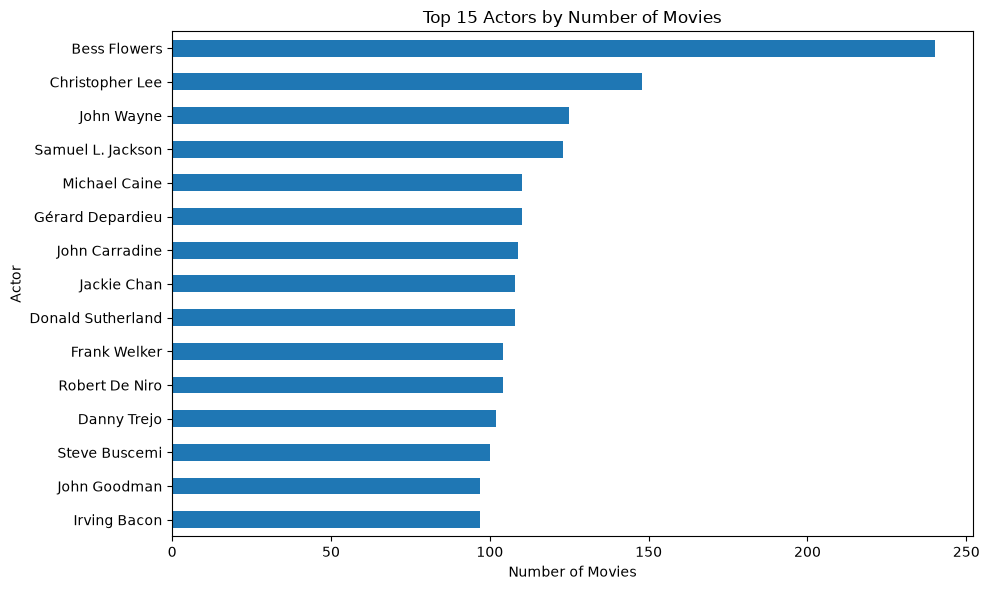

In [110]:
top_actors = movies_per_actor.sort_values(ascending=False).head(TOP_N)
top_actors.index = top_actors.index.map(person_names)

ax = top_actors.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title=f"Top {TOP_N} Actors by Number of Movies",
    ylabel="Actor"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "actors/most_frequent_actors.png", bbox_inches="tight")
plt.show()

In [111]:
release_year_by_id = movies.set_index("id")["release_year"]
top_actor_careers = (
    cast_members[cast_members["id"].isin(movies_per_actor.nlargest(TOP_N).index)]
    .drop_duplicates(["movie_id", "id"])
    .assign(release_year=lambda data: data["movie_id"].map(release_year_by_id))
    .groupby("id")
    .agg(Movies=("movie_id", "size"), First=("release_year", "min"), Last=("release_year", "max"))
    .sort_values("Movies", ascending=False)
)

display(top_actor_careers.rename(index=person_names).rename_axis("Actor"))

,Movies,First,Last
Actor,,,
Bess Flowers,240,1923,1964
Christopher Lee,148,1948,2015
John Wayne,125,1926,1993
Samuel L. Jackson,123,1980,2017
Michael Caine,110,1956,2017
Gérard Depardieu,110,1972,2016
John Carradine,109,1930,1995
Jackie Chan,108,1962,2017
Donald Sutherland,108,1964,2016


### 20.2 Average Number of Actors per Movie over Time

The average only includes movies with a cast, otherwise missing data would look like fewer actors.

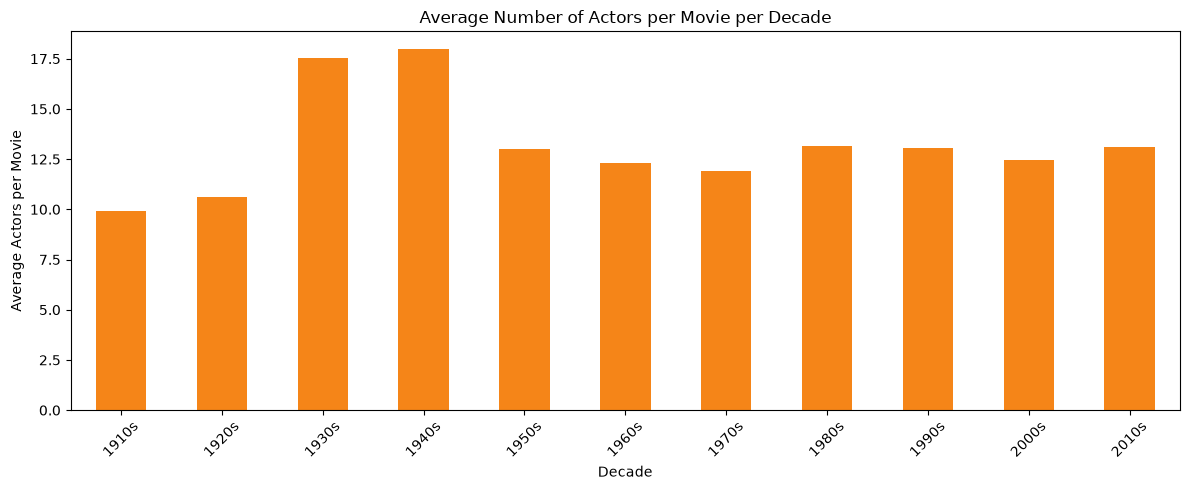

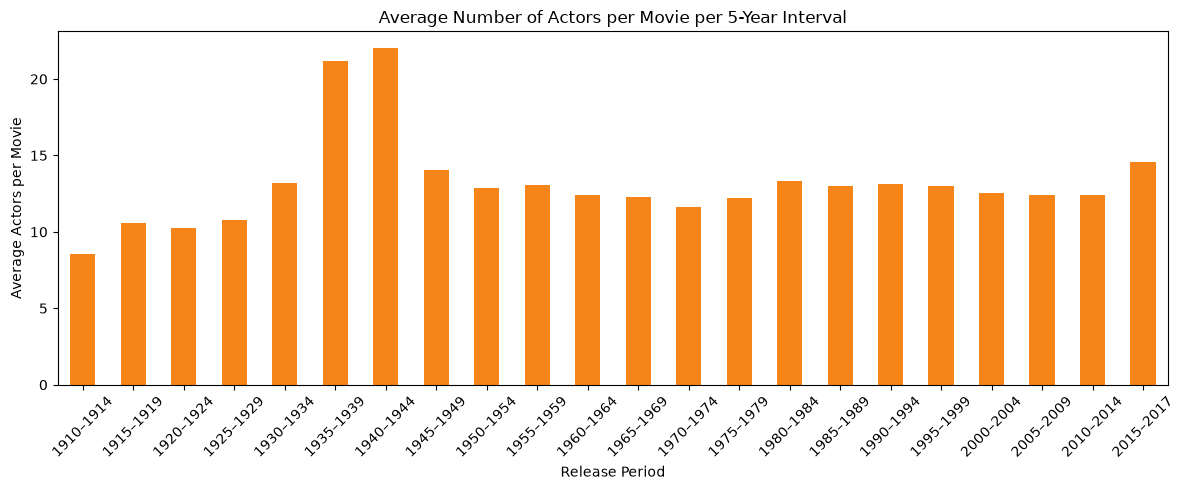

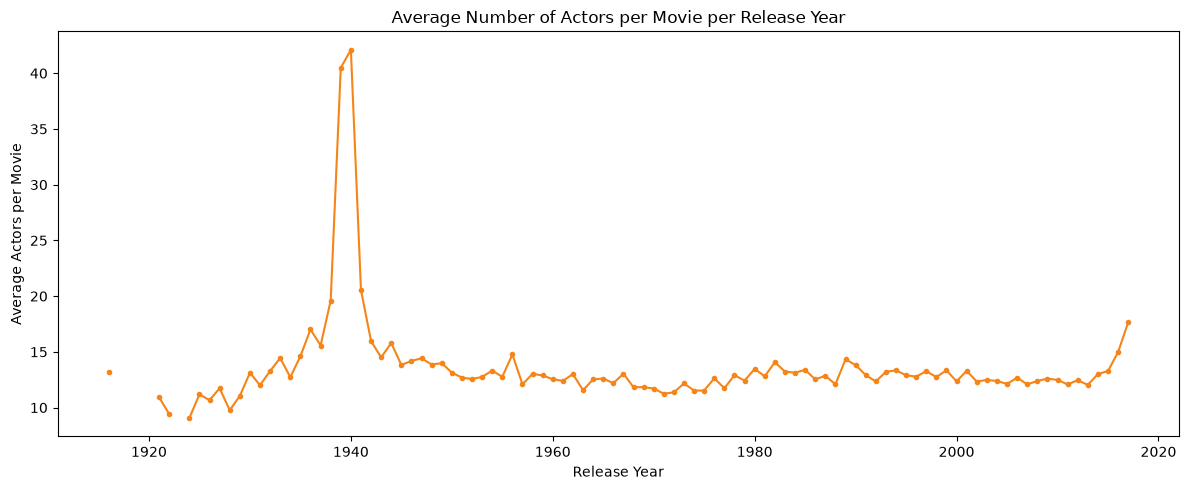

release_year,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean,9.92,10.59,17.55,17.97,12.99,12.33,11.91,13.17,13.06,12.46,13.1
Movies,166.00,407.00,1287.00,1463.00,2045.00,2540.00,3359.00,3782.00,5441.00,10471.00,11938.0


In [112]:
actors_movies = timeline[timeline["n_actors"].gt(0)]

actors_per_movie_per_decade = plot_average_over_time(
    actors_movies["n_actors"],
    actors_movies["release_year"],
    name="Number of Actors per Movie",
    ylabel="Average Actors per Movie",
    output_prefix=RESULT_FOLDER + "actors/average_actors_per_movie",
    color="#F58518"
)

display(actors_per_movie_per_decade.rename(index=decade_label).round(2).T)

**Key findings**

- There are 206,158 actors. 65.0% of them appear in only one movie (2.72 on average, 27 at the 99th percentile).
- The most frequent actor is Bess Flowers (240 movies, 1923–1964), an uncredited extra of the studio era, followed by Christopher Lee (148) and John Wayne (125). Most of the other top 15 actors were still active in 2016–2017.
- 3,053 actor names are shared by several people, and an actor is credited more than once in the same movie 1,207 times (several roles), so actors must be counted as distinct person ids per movie.
- The average number of distinct actors grows from about 10 per movie in the 1910s–1920s to 18 in the 1930s–1940s and has stayed at 12–13 since the 1950s.

## 21. Distribution of Keywords

### 21.1 Number of Keywords per Movie

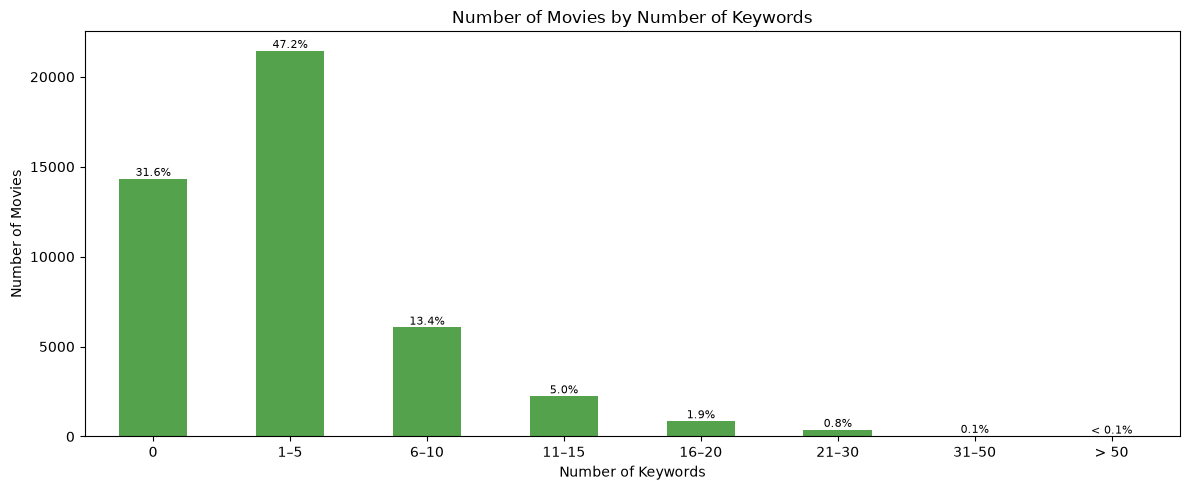

Movies without keywords: 14,340 (31.6%)


In [113]:
plot_share_bar_chart(
    keywords["n_keywords"],
    bins=[-1, 0, 5, 10, 15, 20, 30, 50, np.inf],
    labels=["0", "1–5", "6–10", "11–15", "16–20", "21–30", "31–50", "> 50"],
    title="Number of Movies by Number of Keywords",
    xlabel="Number of Keywords",
    ylabel="Number of Movies",
    output_path=RESULT_FOLDER + "keywords/keywords_per_movie_distribution.png",
    color="#54A24B"
)

print(f"Movies without keywords: {(keywords['n_keywords'] == 0).sum():,} ({100 * (keywords['n_keywords'] == 0).mean():.1f}%)")

In [114]:
display(keywords.loc[keywords["n_keywords"] > 0, "n_keywords"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1).rename("Keywords per movie (movies with keywords)").to_frame().T)

,count,mean,std,min,25%,50%,75%,90%,99%,max
Keywords per movie (movies with keywords),31092.0,5.0,4.9,1.0,2.0,4.0,6.0,11.0,22.0,149.0


### 21.2 Most Common Keywords

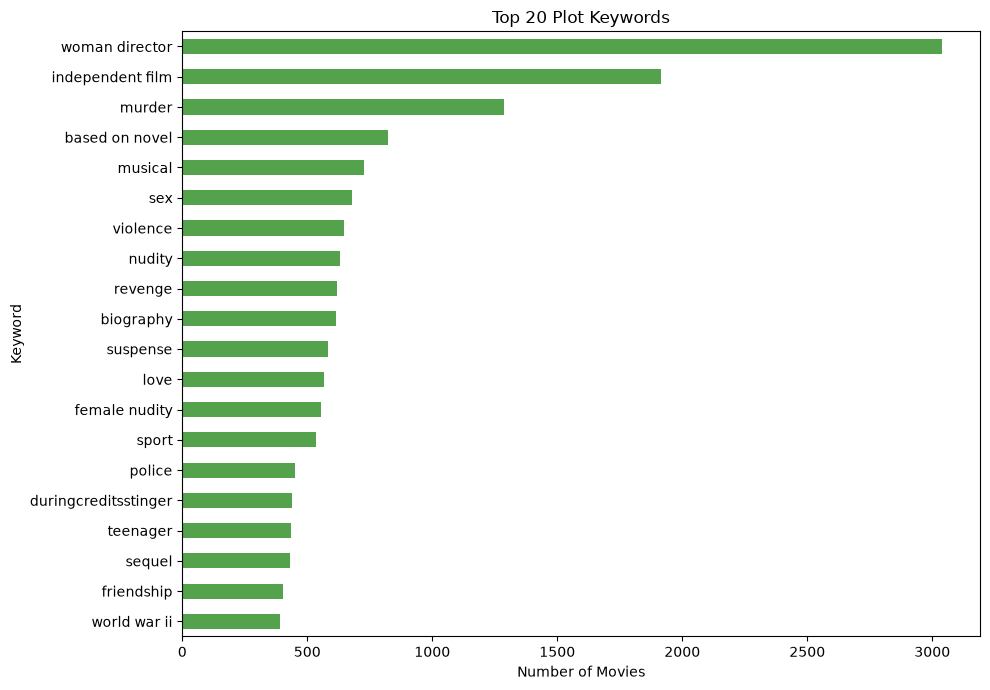

Distinct keywords: 19,956


In [115]:
keyword_counts = count_nested_values(keywords["keywords"].map(lambda items: extract_field(items, "name")))

ax = keyword_counts.head(20).sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    color="#54A24B",
    title="Top 20 Plot Keywords",
    ylabel="Keyword"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "keywords/most_common_keywords.png", bbox_inches="tight")
plt.show()

print(f"Distinct keywords: {len(keyword_counts):,}")

In [116]:
movies_with_keywords = (keywords["n_keywords"] > 0).sum()

display(pd.DataFrame({
    "Movies": keyword_counts.head(20),
    "Share of movies with keywords (%)": 100 * keyword_counts.head(20) / movies_with_keywords
}).round(1))
print(f"Keywords used by only one movie: {(keyword_counts == 1).sum():,} ({100 * (keyword_counts == 1).mean():.1f}%)")

,Movies,Share of movies with keywords (%)
woman director,3039,9.8
independent film,1914,6.2
murder,1285,4.1
based on novel,822,2.6
musical,726,2.3
sex,679,2.2
violence,647,2.1
nudity,629,2.0
revenge,618,2.0
biography,613,2.0


Keywords used by only one movie: 8,691 (43.6%)


### 21.3 Average Number of Keywords per Movie over Time

The average only includes movies with at least one keyword, otherwise missing keywords would look like fewer keywords.

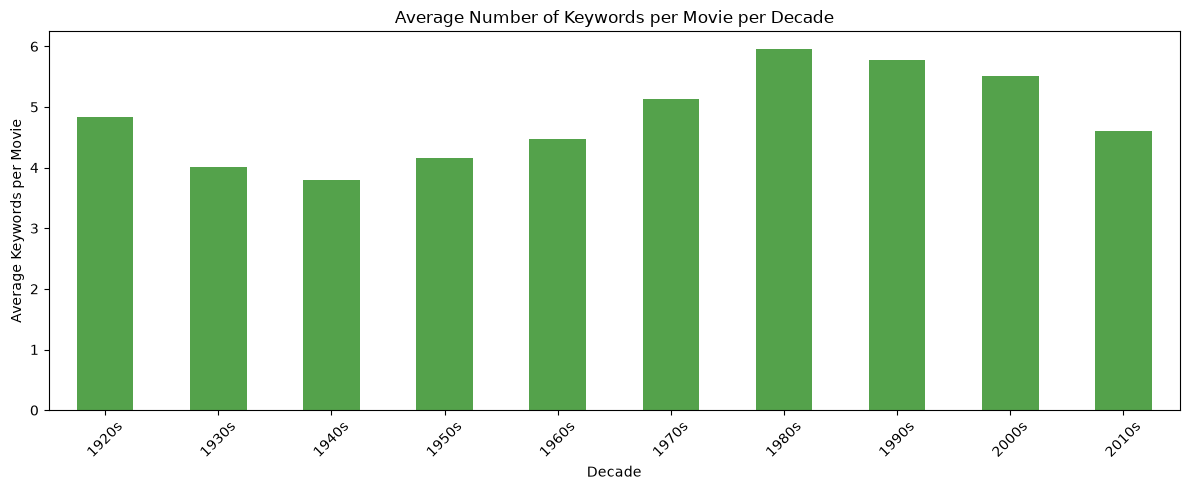

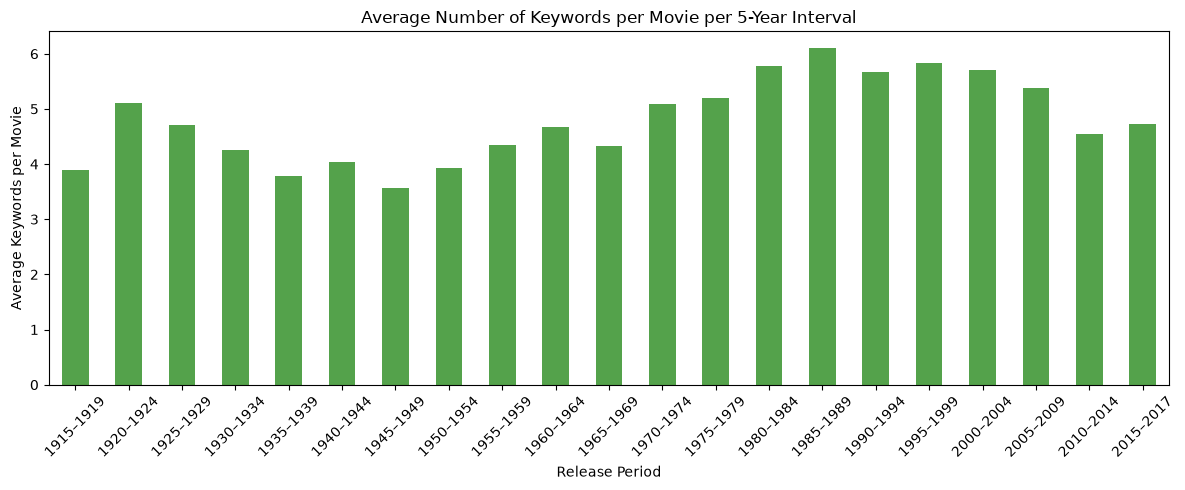

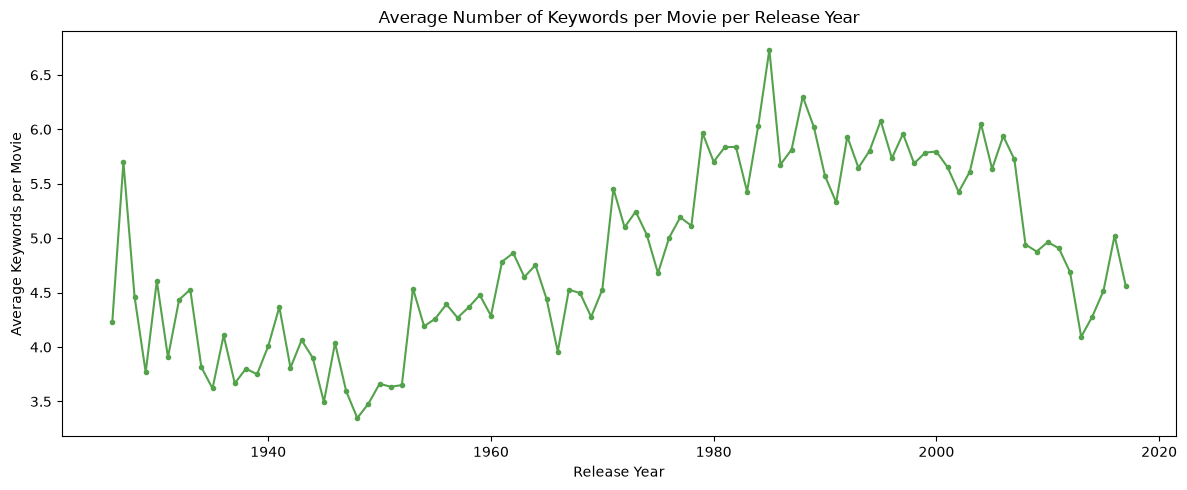

release_year,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Mean,4.84,4.0,3.79,4.15,4.48,5.13,5.95,5.77,5.51,4.61
Movies,298.00,1091.0,1291.00,1674.00,1921.00,2512.00,2737.00,3973.00,7321.00,8037.00


In [117]:
keyword_movies = timeline[timeline["n_keywords"].gt(0)]

keywords_per_movie_per_decade = plot_average_over_time(
    keyword_movies["n_keywords"],
    keyword_movies["release_year"],
    name="Number of Keywords per Movie",
    ylabel="Average Keywords per Movie",
    output_prefix=RESULT_FOLDER + "keywords/average_keywords_per_movie",
    color="#54A24B"
)

display(keywords_per_movie_per_decade.rename(index=decade_label).round(2).T)

**Key findings**

- 14,340 movies (31.6%) have no keywords. The movies with keywords have a median of 4 keywords (mean 5.0, at most 149).
- There are 19,956 distinct keywords, and 43.6% of them are only used by one movie.
- The most common keywords describe the production context rather than the plot: *woman director* (9.8% of the movies with keywords), *independent film* (6.2%) and *based on novel* (2.6%). They are followed by broad themes such as *murder*, *revenge*, *love* and *violence*.
- The average number of keywords rises from about 4 in the 1930s–1940s to 6 in the 1980s and falls to 4.6 in the 2010s. Keywords are added by TMDB users, so the drop for recent movies more likely reflects less complete tagging than fewer themes.

## 22. Distribution of Ratings

### 22.1 Rating Values

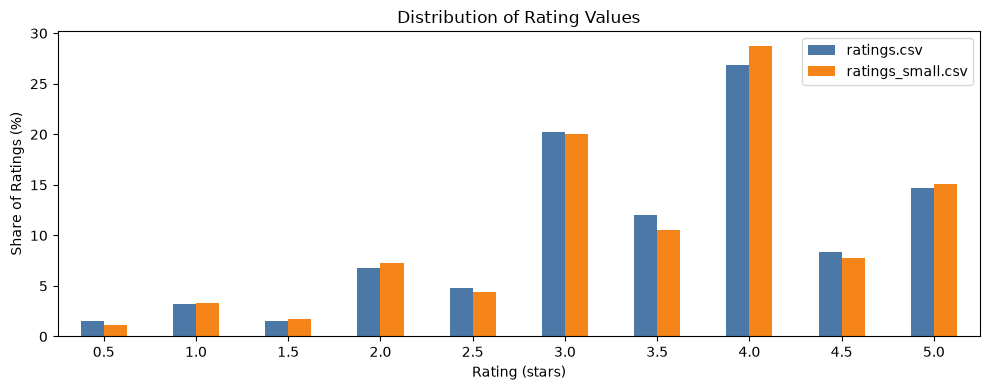

Mean rating: 3.53 (full), 3.54 (small)


Share of whole-star ratings: 71.8%


In [118]:
rating_shares = pd.DataFrame({
    "ratings.csv": ratings_df["rating"].value_counts(normalize=True),
    "ratings_small.csv": ratings_small_df["rating"].value_counts(normalize=True)
}).sort_index() * 100

ax = rating_shares.plot(
    kind="bar",
    figsize=(10, 4),
    color=["#4C78A8", "#F58518"],
    title="Distribution of Rating Values",
    xlabel="Rating (stars)",
    ylabel="Share of Ratings (%)",
    rot=0
)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "ratings/rating_value_distribution.png", bbox_inches="tight")
plt.show()

print(f"Mean rating: {ratings_df['rating'].mean():.2f} (full), {ratings_small_df['rating'].mean():.2f} (small)")
print(f"Share of whole-star ratings: {100 * (ratings_df['rating'] % 1 == 0).mean():.1f}%")

In [119]:
display(rating_shares.round(1).T)
print(f"Median rating: {ratings_df['rating'].median():.1f}, most common rating: {ratings_df['rating'].mode()[0]:.1f}")
print(f"Ratings of 4 stars or more: {100 * (ratings_df['rating'] >= 4).mean():.1f}%, ratings below 2 stars: {100 * (ratings_df['rating'] < 2).mean():.1f}%")

rating,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0
ratings.csv,1.6,3.2,1.6,6.8,4.8,20.2,12.0,26.9,8.3,14.6
ratings_small.csv,1.1,3.3,1.7,7.3,4.4,20.1,10.5,28.7,7.7,15.1


Median rating: 3.5, most common rating: 4.0
Ratings of 4 stars or more: 49.9%, ratings below 2 stars: 6.3%


### 22.2 Ratings over Time

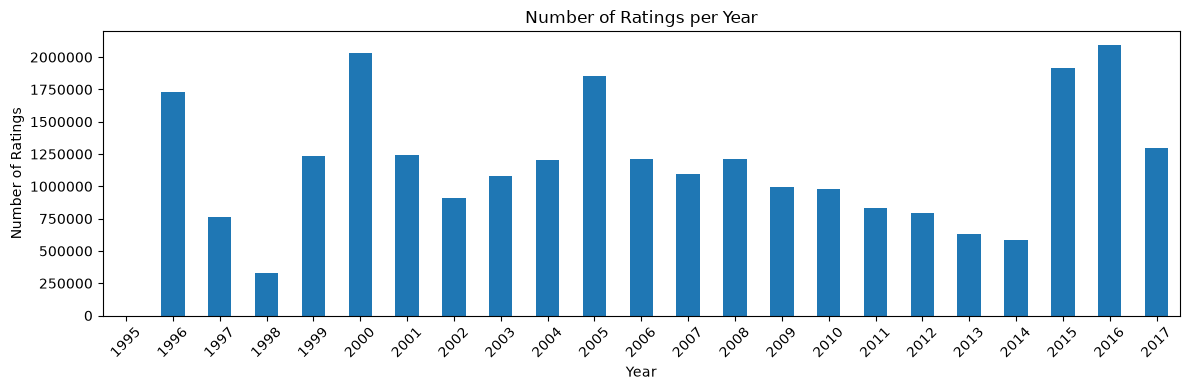

First rating: 1995-01-09 11:46:44 | Last rating: 2017-08-04 06:57:50


In [120]:
ratings_per_year = ratings_df["datetime"].dt.year.value_counts().sort_index()

ax = ratings_per_year.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Ratings per Year",
    xlabel="Year",
    ylabel="Number of Ratings",
    rot=45
)

ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "ratings/number_of_ratings_per_year.png", bbox_inches="tight")
plt.show()

print("First rating:", ratings_df["datetime"].min(), "| Last rating:", ratings_df["datetime"].max())

In [121]:
display(pd.DataFrame({
    "Ratings": ratings_per_year,
    "Share (%)": (100 * ratings_per_year / ratings_per_year.sum()).round(1)
}).rename_axis("Year"))
print(f"Years with most ratings: {', '.join(f'{year} ({count:,})' for year, count in ratings_per_year.nlargest(3).items())}")

,Ratings,Share (%)
Year,,
1995,4,0.0
1996,1733263,6.7
1997,763932,2.9
1998,329720,1.3
1999,1231263,4.7
2000,2034030,7.8
2001,1239718,4.8
2002,910659,3.5
2003,1079511,4.1


Years with most ratings: 2016 (2,094,961), 2000 (2,034,030), 2015 (1,913,720)


### 22.3 Ratings per User and per Movie

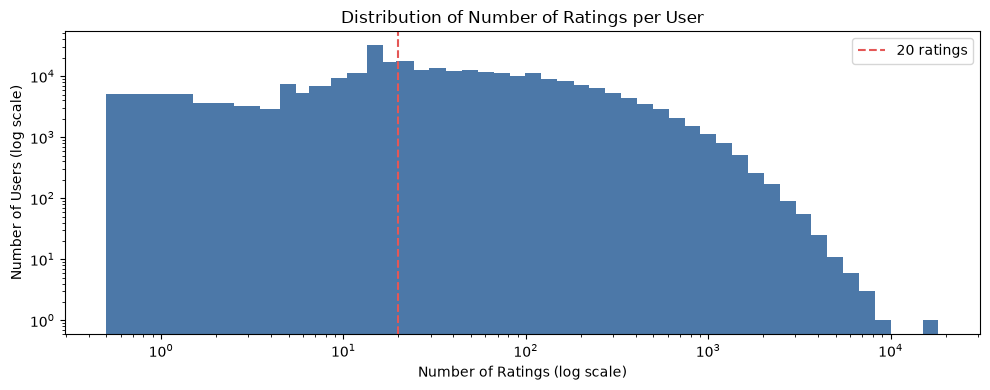

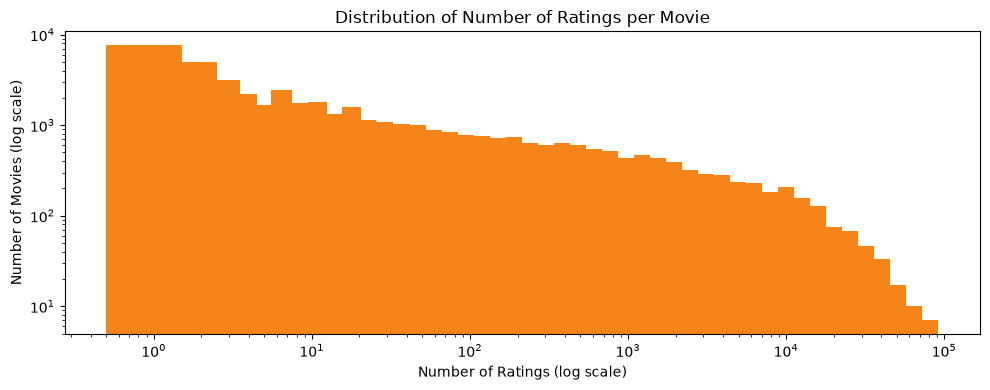

,Ratings per user,Ratings per movie
count,270896.0,45115.0
mean,96.1,576.8
std,205.7,3037.4
min,1.0,1.0
50%,30.0,8.0
90%,236.0,695.0
99%,963.0,12846.9
max,18276.0,91921.0


Users with ≥ 20 ratings: 166,444 of 270,896
Share of all ratings given by the top 1% most active users: 15.5%


In [122]:
ratings_per_user = ratings_df.groupby("userId").size()
ratings_per_movie = ratings_df.groupby("movieId").size()

plot_log_histogram(
    ratings_per_user,
    title="Distribution of Number of Ratings per User",
    xlabel="Number of Ratings (log scale)",
    ylabel="Number of Users (log scale)",
    output_path=RESULT_FOLDER + "ratings/ratings_per_user_distribution.png",
    threshold=MIN_USER_RATINGS,
    threshold_label=f"{MIN_USER_RATINGS} ratings"
)

plot_log_histogram(
    ratings_per_movie,
    title="Distribution of Number of Ratings per Movie",
    xlabel="Number of Ratings (log scale)",
    ylabel="Number of Movies (log scale)",
    output_path=RESULT_FOLDER + "ratings/ratings_per_movie_distribution.png",
    color="#F58518"
)

top_user_share = ratings_per_user.sort_values(ascending=False).head(len(ratings_per_user) // 100).sum() / len(ratings_df)
display(pd.DataFrame({
    "Ratings per user": ratings_per_user.describe(percentiles=[0.5, 0.9, 0.99]),
    "Ratings per movie": ratings_per_movie.describe(percentiles=[0.5, 0.9, 0.99])
}).round(1))
print(f"Users with ≥ {MIN_USER_RATINGS} ratings: {(ratings_per_user >= MIN_USER_RATINGS).sum():,} of {len(ratings_per_user):,}")
print(f"Share of all ratings given by the top 1% most active users: {100 * top_user_share:.1f}%")

### 22.4 User Rating Variance and Genre Breadth

To see how differently users rate and how broad their taste is, every movie's genres are encoded as a 20-bit mask. The mask of each rating is looked up through `links.csv` and OR-ed per user, so the number of set bits is the number of distinct genres the user has rated, computed without exploding the 26 million ratings. The variance is only shown for users with at least 20 ratings, since it is unreliable for fewer.

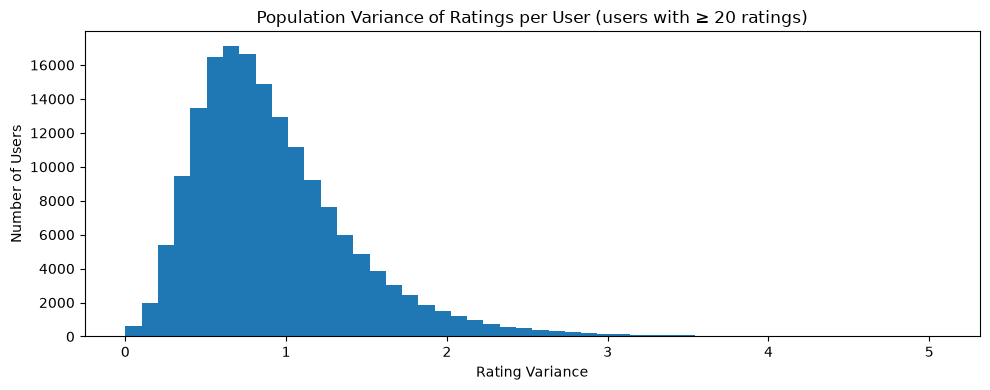

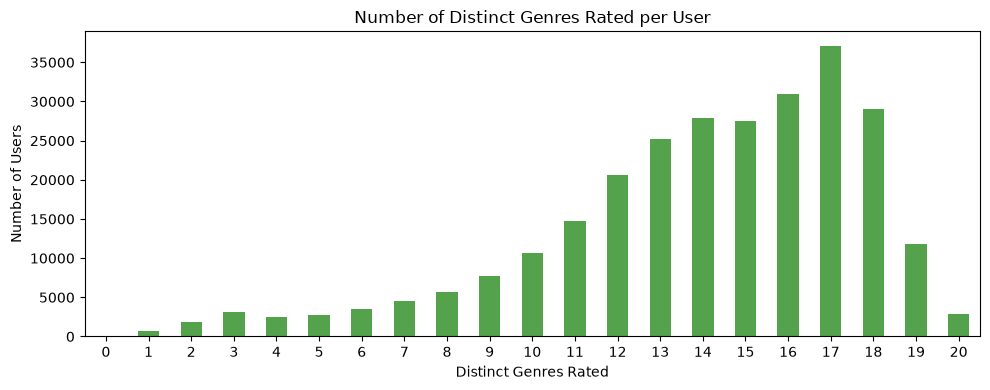

Users with zero variance (always the same rating) among active users: 196
Users who rated all 20 genres: 2,896


In [123]:
genre_bits = {genre: 1 << position for position, genre in enumerate(sorted(genre_counts.index))}

genre_mask_by_tmdb = movies.set_index("id")["genre_names"].map(
    lambda names: sum(genre_bits[name] for name in set(names))
)
genre_mask_by_movie_id = (
    links_df.dropna(subset=["tmdbId"])
    .assign(tmdbId=lambda data: data["tmdbId"].astype(int))
    .drop_duplicates("movieId")
    .set_index("movieId")["tmdbId"]
    .map(genre_mask_by_tmdb)
    .fillna(0)
    .astype(np.int64)
)

rating_masks = ratings_df["movieId"].map(genre_mask_by_movie_id).fillna(0).astype(np.int64).to_numpy()
user_ids = ratings_df["userId"].to_numpy()
user_starts = np.flatnonzero(np.r_[True, user_ids[1:] != user_ids[:-1]])  # ratings.csv is sorted by userId

user_stats = pd.DataFrame({
    "ratings": ratings_per_user,
    "variance": ratings_df.groupby("userId")["rating"].var(ddof=0),
    "distinct_genres": pd.Series(
        np.bitwise_count(np.bitwise_or.reduceat(rating_masks, user_starts)),
        index=user_ids[user_starts]
    )
})
active_users = user_stats[user_stats["ratings"] >= MIN_USER_RATINGS]

ax = active_users["variance"].plot(
    kind="hist",
    bins=50,
    figsize=(10, 4),
    title=f"Population Variance of Ratings per User (users with ≥ {MIN_USER_RATINGS} ratings)",
    xlabel="Rating Variance"
)

ax.set_ylabel("Number of Users")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "ratings/user_rating_variance_distribution.png", bbox_inches="tight")
plt.show()

distinct_genre_counts = user_stats["distinct_genres"].value_counts().sort_index()
ax = distinct_genre_counts.plot(
    kind="bar",
    figsize=(10, 4),
    color="#54A24B",
    title="Number of Distinct Genres Rated per User",
    xlabel="Distinct Genres Rated",
    rot=0
)

ax.set_ylabel("Number of Users")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "ratings/user_genre_breadth_distribution.png", bbox_inches="tight")
plt.show()

print(f"Users with zero variance (always the same rating) among active users: {(active_users['variance'] == 0).sum():,}")
print(f"Users who rated all {len(genre_bits)} genres: {(user_stats['distinct_genres'] == len(genre_bits)).sum():,}")

In [124]:
display(pd.DataFrame({
    f"Rating variance (≥ {MIN_USER_RATINGS} ratings)": active_users["variance"].describe(percentiles=[0.1, 0.5, 0.9]),
    "Distinct genres rated (all users)": user_stats["distinct_genres"].describe(percentiles=[0.1, 0.5, 0.9])
}).round(2).T)
print(f"Spearman correlation between number of ratings and distinct genres: {user_stats['ratings'].corr(user_stats['distinct_genres'], method='spearman'):.2f}")

,count,mean,std,min,10%,50%,90%,max
Rating variance (≥ 20 ratings),166444.0,0.93,0.51,0.0,0.4,0.82,1.57,5.06
Distinct genres rated (all users),270896.0,13.97,3.76,0.0,9.0,15.00,18.00,20.00


Spearman correlation between number of ratings and distinct genres: 0.90


### 22.5 MovieLens Ratings vs TMDB Vote Average

The MovieLens ratings (0.5–5) and the TMDB `vote_average` (0–10) come from different user communities. Comparing them per movie shows whether they measure the same thing.

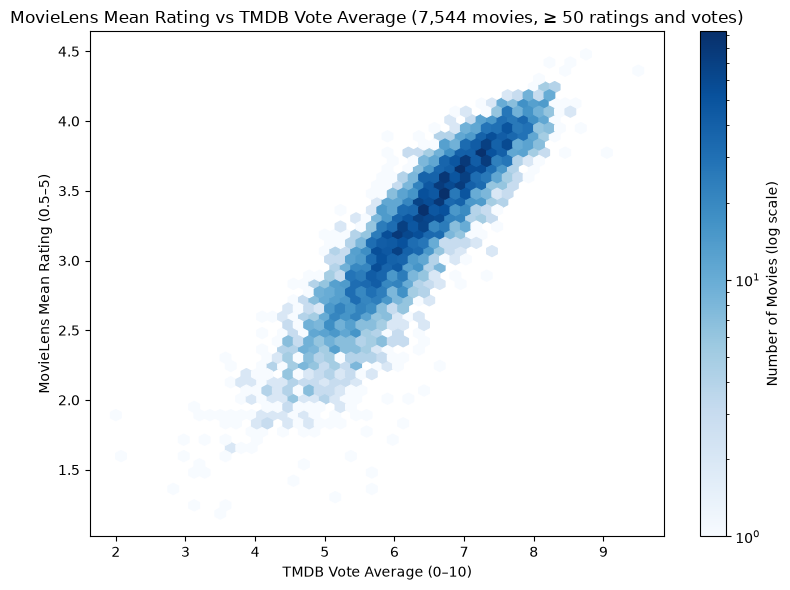

Pearson correlation: 0.91


In [125]:
movielens_stats = ratings_df.groupby("movieId")["rating"].agg(mean_rating="mean", n_ratings="size")

rating_comparison = (
    links_df.dropna(subset=["tmdbId"])
    .assign(tmdbId=lambda data: data["tmdbId"].astype(int))
    .join(movielens_stats, on="movieId", how="inner")
    .merge(movies[["id", "vote_average", "vote_count"]], left_on="tmdbId", right_on="id")
    .query("n_ratings >= @MIN_VOTE_COUNT and vote_count >= @MIN_VOTE_COUNT")
)

plt.figure(figsize=(8, 6))
plt.hexbin(rating_comparison["vote_average"], rating_comparison["mean_rating"], gridsize=50, cmap="Blues", mincnt=1, bins="log")
plt.colorbar(label="Number of Movies (log scale)")
plt.title(
    f"MovieLens Mean Rating vs TMDB Vote Average ({len(rating_comparison):,} movies, "
    f"≥ {MIN_VOTE_COUNT} ratings and votes)"
)
plt.xlabel("TMDB Vote Average (0–10)")
plt.ylabel("MovieLens Mean Rating (0.5–5)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "ratings/movielens_vs_tmdb_rating.png", bbox_inches="tight")
plt.show()

print(f"Pearson correlation: {rating_comparison['vote_average'].corr(rating_comparison['mean_rating']):.2f}")

In [126]:
rating_difference = 2 * rating_comparison["mean_rating"] - rating_comparison["vote_average"]

print(f"Spearman correlation: {rating_comparison['vote_average'].corr(rating_comparison['mean_rating'], method='spearman'):.2f}")
print(f"Mean MovieLens rating (scaled to 0–10): {2 * rating_comparison['mean_rating'].mean():.2f}, mean TMDB vote average: {rating_comparison['vote_average'].mean():.2f}")
print(f"Mean difference (MovieLens × 2 − TMDB): {rating_difference.mean():+.2f} (standard deviation {rating_difference.std():.2f})")

Spearman correlation: 0.92
Mean MovieLens rating (scaled to 0–10): 6.60, mean TMDB vote average: 6.45
Mean difference (MovieLens × 2 − TMDB): +0.15 (standard deviation 0.41)


**Key findings**

- The ratings are skewed towards positive values: the mean is 3.53, the median 3.5 and the most common rating 4.0, and 49.9% of the ratings are 4 stars or more. Users prefer whole stars (71.8% of the ratings), and `ratings_small.csv` has almost the same distribution.
- The ratings span January 1995 to August 2017, with most ratings in 2016, 2000 and 2015 (about 2 million each).
- A user has a median of 30 ratings (at most 18,276), and the 1% most active users give 15.5% of all ratings. 166,444 of the 270,896 users have at least 20 ratings. A movie has a median of 8 ratings, and the most rated movie has 91,921.
- For users with at least 20 ratings, the rating variance is usually 0.4–1.6 (median 0.82), and 196 users always give the same rating. Users have rated a median of 15 of the 20 genres, and the number of distinct genres grows with the number of ratings (Spearman 0.90).
- The MovieLens mean rating and the TMDB vote average agree closely (Pearson 0.91, Spearman 0.92 for 7,544 movies with at least 50 ratings and votes). Scaled to 0–10, the MovieLens ratings are 0.15 points higher on average.

## 23. Relationships Between Variables

### 23.1 Correlation Between Numeric Features

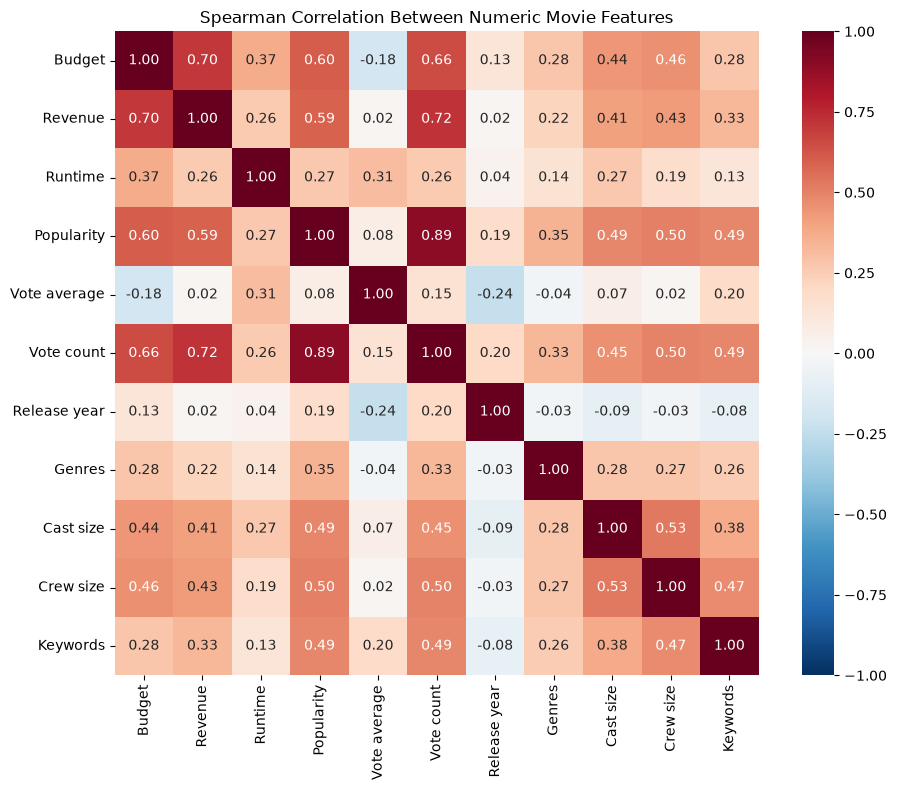

In [127]:
numeric_features = {
    "budget_usd": "Budget",
    "revenue_usd": "Revenue",
    "runtime": "Runtime",
    "popularity": "Popularity",
    "vote_average": "Vote average",
    "vote_count": "Vote count",
    "release_year": "Release year",
    "n_genres": "Genres",
    "n_cast": "Cast size",
    "n_crew": "Crew size",
    "n_keywords": "Keywords"
}

correlation_df = movies[list(numeric_features)].astype(float).rename(columns=numeric_features)
correlation_df.loc[movies["vote_count"] < MIN_VOTE_COUNT, "Vote average"] = np.nan
correlation_df.loc[~movies["runtime"].between(MIN_RUNTIME, MAX_RUNTIME), "Runtime"] = np.nan

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_df.corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Spearman Correlation Between Numeric Movie Features")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "relationships/numeric_correlation_heatmap.png", bbox_inches="tight")
plt.show()

Spearman (rank) correlation is used because budget, revenue, vote count and popularity are extremely right-skewed. Each pair uses the movies where both values are known; vote average is only used for movies with at least 50 votes and runtime only for plausible values.

### 23.2 Vote Average and Revenue by Genre

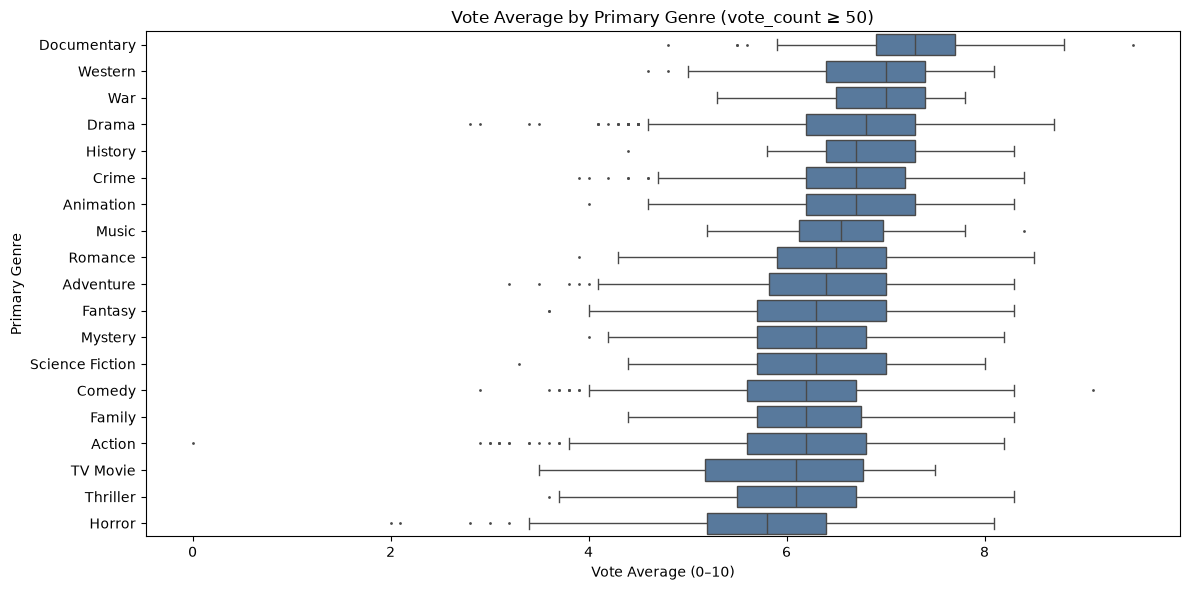

In [128]:
rated_movies = movies[(movies["vote_count"] >= MIN_VOTE_COUNT) & movies["primary_genre"].notna()]
genre_order = rated_movies.groupby("primary_genre")["vote_average"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=rated_movies,
    x="vote_average",
    y="primary_genre",
    order=genre_order,
    color="#4C78A8",
    fliersize=1
)
plt.title(f"Vote Average by Primary Genre (vote_count ≥ {MIN_VOTE_COUNT})")
plt.xlabel("Vote Average (0–10)")
plt.ylabel("Primary Genre")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "relationships/vote_average_by_primary_genre.png", bbox_inches="tight")
plt.show()

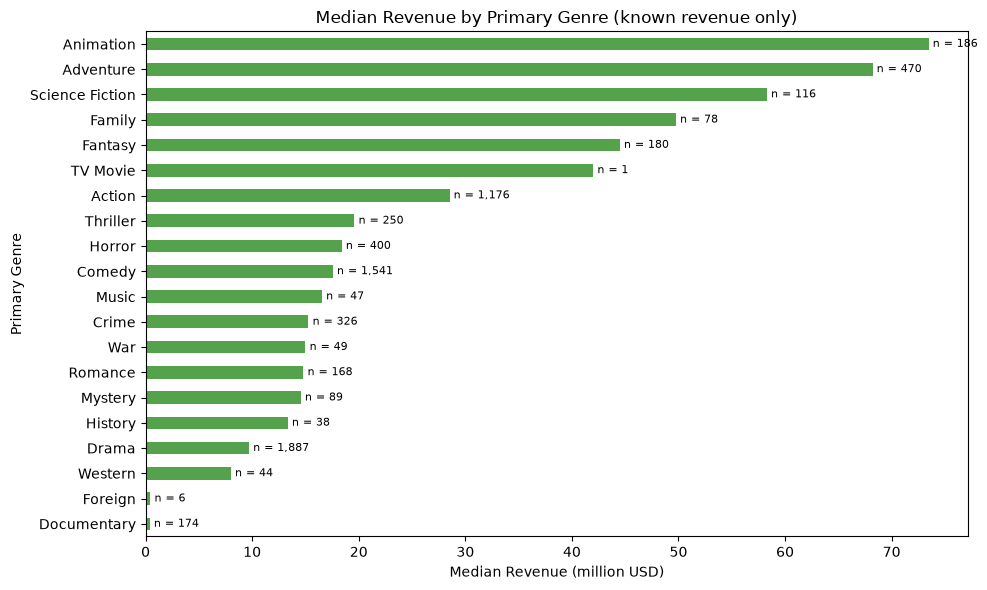

In [129]:
revenue_by_genre = (
    movies.dropna(subset=["revenue_usd", "primary_genre"])
    .groupby("primary_genre")["revenue_usd"]
    .agg(["median", "size"])
    .sort_values("median")
)

ax = (revenue_by_genre["median"] / 1e6).plot(
    kind="barh",
    figsize=(10, 6),
    color="#54A24B",
    title="Median Revenue by Primary Genre (known revenue only)",
    ylabel="Primary Genre"
)

for patch, size in zip(ax.patches, revenue_by_genre["size"]):
    ax.annotate(f"n = {size:,}", (patch.get_width(), patch.get_y() + patch.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)

ax.set_xlabel("Median Revenue (million USD)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "relationships/median_revenue_by_primary_genre.png", bbox_inches="tight")
plt.show()

**Findings:**

- Budget, revenue, vote count, popularity and cast/crew size are strongly correlated (e.g. popularity–vote count 0.89, revenue–vote count 0.72). Together they measure how big and well-known a movie is.
- The vote average is almost independent of budget and revenue (−0.18 and 0.02), is higher for longer movies (0.29), and is lower for newer movies (−0.24, likely because classics that are still rated are already a selection of good films).
- Documentaries, Westerns, War and Drama have the highest median vote average, while Horror has the lowest. Animation, Adventure and Science Fiction have the highest median revenue. The small groups (e.g. TV Movie, Foreign) should not be interpreted.

## 24. Data Quality

This section investigates missing, duplicate and inconsistent data, and whether the references between the files are valid, in more detail than the overview in section 2. Outliers (extreme but possible values, such as placeholder budgets below 1,000 USD or runtimes above 300 minutes) are not handled here. Every finding leads to a cleaning step in `insert.py`, which are summarised in 24.5.

### 24.1 Missing Values

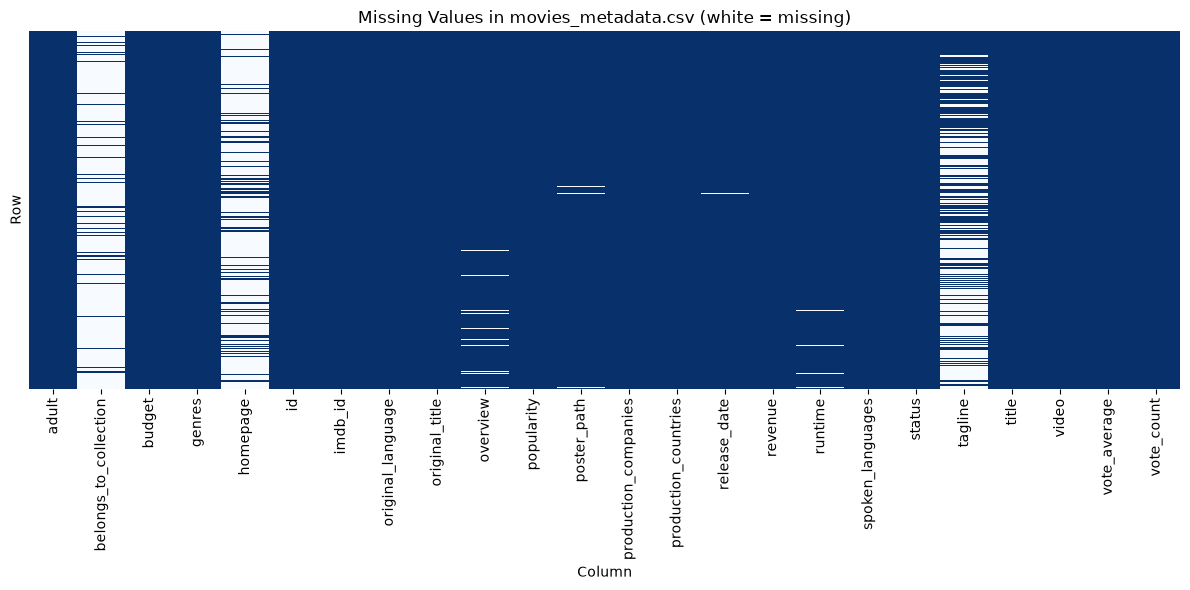

In [130]:
plt.figure(figsize=(12, 6))
sns.heatmap(
    raw_movies_df.isnull(),
    cbar=False,
    cmap="Blues_r",
    yticklabels=False
)

plt.title("Missing Values in movies_metadata.csv (white = missing)")
plt.xlabel("Column")
plt.ylabel("Row")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "data_quality/missing_values_heatmap.png", bbox_inches="tight")
plt.show()

`NaN` only shows part of the missing data. Many values are present, but encode "unknown": a budget, revenue or runtime of 0, a vote average of 0 without votes, placeholder overviews, empty arrays, empty strings and a gender of 0. The table counts both kinds for every field where data is missing, using one row per movie (3.4) and one row per credit (3.5).

In [131]:
spoken_language_objects = pd.DataFrame([item for items in movies["spoken_languages"] for item in items])
keyword_objects = pd.DataFrame([item for items in keywords["keywords"] for item in items])

def missing_row(file_name, field, explicit, implicit, encoding):
    """One row of the missing-value summary: explicit (NaN/None) and implicit missing values of a field."""
    return {
        "File": file_name,
        "Field": field,
        "Rows": len(explicit),
        "Explicit (NaN)": int(explicit.sum()),
        "Implicit": int((implicit & ~explicit).sum()),
        "Implicit encoding": encoding
    }

missing_summary = pd.DataFrame([
    missing_row("movies_metadata", "budget", movies["budget"].isna(), movies["budget"].eq(0), "0"),
    missing_row("movies_metadata", "revenue", movies["revenue"].isna(), movies["revenue"].eq(0), "0"),
    missing_row("movies_metadata", "runtime", movies["runtime"].isna(), movies["runtime"].eq(0), "0"),
    missing_row("movies_metadata", "vote_average", movies["vote_average"].isna(), movies["vote_count"].eq(0), "0 without votes"),
    missing_row("movies_metadata", "release_date", movies["release_date"].isna(), pd.Series(False, index=movies.index), "-"),
    missing_row("movies_metadata", "overview", movies["overview"].isna(), placeholder_overviews, "placeholder text"),
    missing_row("movies_metadata", "tagline", movies["tagline"].isna(), pd.Series(False, index=movies.index), "-"),
    missing_row("movies_metadata", "homepage", movies["homepage"].isna(), pd.Series(False, index=movies.index), "-"),
    missing_row("movies_metadata", "imdb_id", movies["imdb_id"].isna(), pd.Series(False, index=movies.index), "-"),
    missing_row("movies_metadata", "status", movies["status"].isna(), pd.Series(False, index=movies.index), "-"),
    missing_row("movies_metadata", "belongs_to_collection", movies["belongs_to_collection"].isna(), pd.Series(False, index=movies.index), "-"),
    missing_row("movies_metadata", "genres", movies["genres"].isna(), movies["genres"].map(len).eq(0), "[]"),
    missing_row("movies_metadata", "production_companies", movies["production_companies"].isna(), movies["production_companies"].map(len).eq(0), "[]"),
    missing_row("movies_metadata", "production_countries", movies["production_countries"].isna(), movies["production_countries"].map(len).eq(0), "[]"),
    missing_row("movies_metadata", "spoken_languages", movies["spoken_languages"].isna(), movies["spoken_languages"].map(len).eq(0), "[]"),
    missing_row("movies_metadata", "spoken_languages.name", spoken_language_objects["name"].isna(), spoken_language_objects["name"].str.strip().eq(""), '""'),
    missing_row("credits", "cast", credits["cast"].isna(), credits["cast"].map(len).eq(0), "[]"),
    missing_row("credits", "crew", credits["crew"].isna(), credits["crew"].map(len).eq(0), "[]"),
    missing_row("credits", "cast.character", cast_members["character"].isna(), cast_members["character"].str.strip().eq(""), '""'),
    missing_row("credits", "cast.gender", cast_members["gender"].isna(), cast_members["gender"].eq(0), "0"),
    missing_row("credits", "crew.gender", crew_members["gender"].isna(), crew_members["gender"].eq(0), "0"),
    missing_row("credits", "cast.profile_path", cast_members["profile_path"].isna(), pd.Series(False, index=cast_members.index), "-"),
    missing_row("credits", "crew.profile_path", crew_members["profile_path"].isna(), pd.Series(False, index=crew_members.index), "-"),
    missing_row("keywords", "keywords", keywords["keywords"].isna(), keywords["keywords"].map(len).eq(0), "[]"),
    missing_row("keywords", "keywords.name", keyword_objects["name"].isna(), keyword_objects["name"].str.strip().eq(""), '""'),
    missing_row("links", "tmdbId", links_df["tmdbId"].isna(), pd.Series(False, index=links_df.index), "-"),
])
missing_summary["Missing (%)"] = 100 * (missing_summary["Explicit (NaN)"] + missing_summary["Implicit"]) / missing_summary["Rows"]
missing_summary = missing_summary.sort_values("Missing (%)", ascending=False).reset_index(drop=True)

display(missing_summary.round(2))

,File,Field,Rows,Explicit (NaN),Implicit,Implicit encoding,Missing (%)
0,movies_metadata,belongs_to_collection,45433,40945,0,-,90.12
1,movies_metadata,revenue,45433,3,38032,0,83.72
2,movies_metadata,homepage,45433,37659,0,-,82.89
3,movies_metadata,budget,45433,0,36553,0,80.45
4,credits,crew.profile_path,463836,368835,0,-,79.52
5,credits,crew.gender,463836,0,272032,0,58.65
6,movies_metadata,tagline,45433,25032,0,-,55.10
7,credits,cast.gender,562044,0,223765,0,39.81
8,keywords,keywords,45432,0,14340,[],31.56
9,credits,cast.profile_path,562044,173678,0,-,30.90


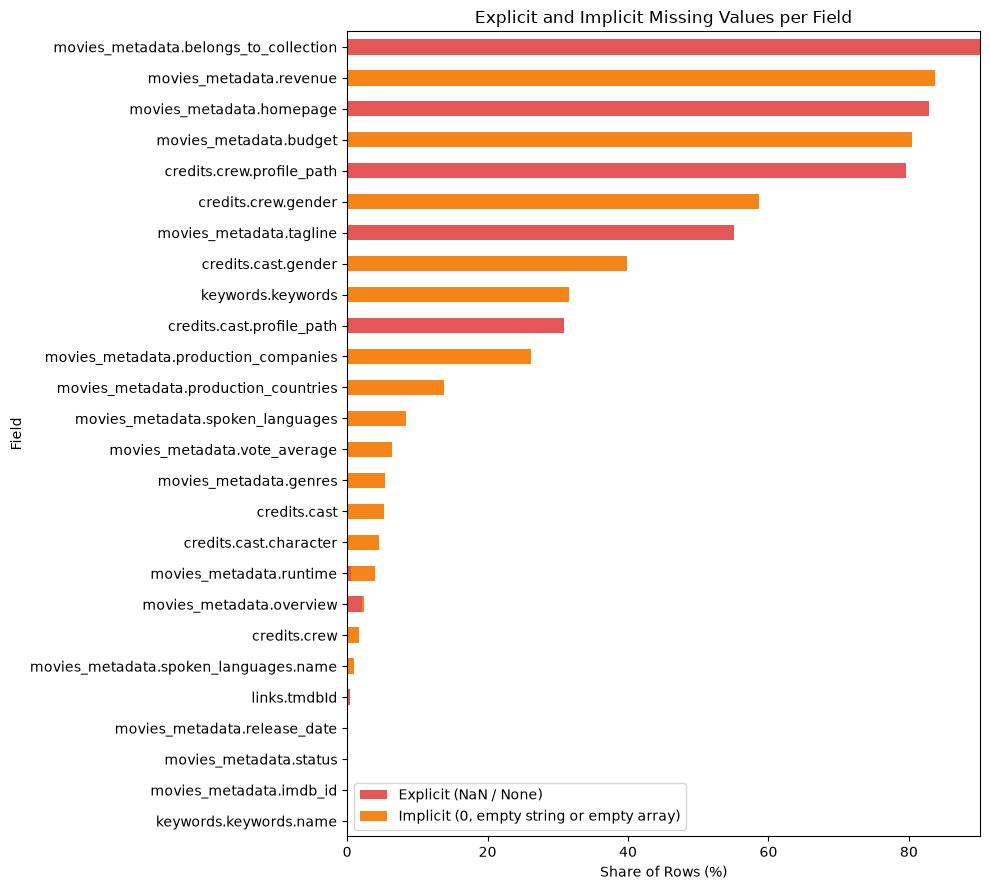

In [132]:
missing_shares = (
    missing_summary.assign(
        Field=missing_summary["File"] + "." + missing_summary["Field"],
        Explicit=100 * missing_summary["Explicit (NaN)"] / missing_summary["Rows"],
        Implicit=100 * missing_summary["Implicit"] / missing_summary["Rows"]
    )
    .set_index("Field")[["Explicit", "Implicit"]]
    .rename(columns={"Explicit": "Explicit (NaN / None)", "Implicit": "Implicit (0, empty string or empty array)"})
)

ax = missing_shares.loc[missing_shares.sum(axis=1).sort_values().index].plot(
    kind="barh",
    stacked=True,
    figsize=(10, 9),
    color=["#E45756", "#F58518"],
    title="Explicit and Implicit Missing Values per Field",
    ylabel="Field"
)

ax.set_xlabel("Share of Rows (%)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "data_quality/missing_values_summary.png", bbox_inches="tight")
plt.show()

**Findings:**

- Explicit `NaN` values are concentrated in optional fields: `belongs_to_collection` (90 %), `homepage` (83 %), `tagline` (55 %) and the profile pictures of the cast (31 %) and crew (80 %). They describe properties a movie may simply not have and are kept as missing.
- The largest gaps are implicit: 84 % of the revenues and 80 % of the budgets are 0, the gender is 0 for 59 % of the crew and 40 % of the cast credits, and 32 % of the movies have an empty keyword list. Without cleaning, these would be treated as real values, e.g. a revenue of 0 USD.
- Empty arrays (no genres, companies, countries, languages, cast or crew) mean that TMDB has no information. They are kept as empty arrays, which is the natural way to store "none" in MongoDB.

Missing values are not spread evenly over the movies. The share of movies with a known value is computed per decade (with at least 100 movies), and for English and non-English movies.

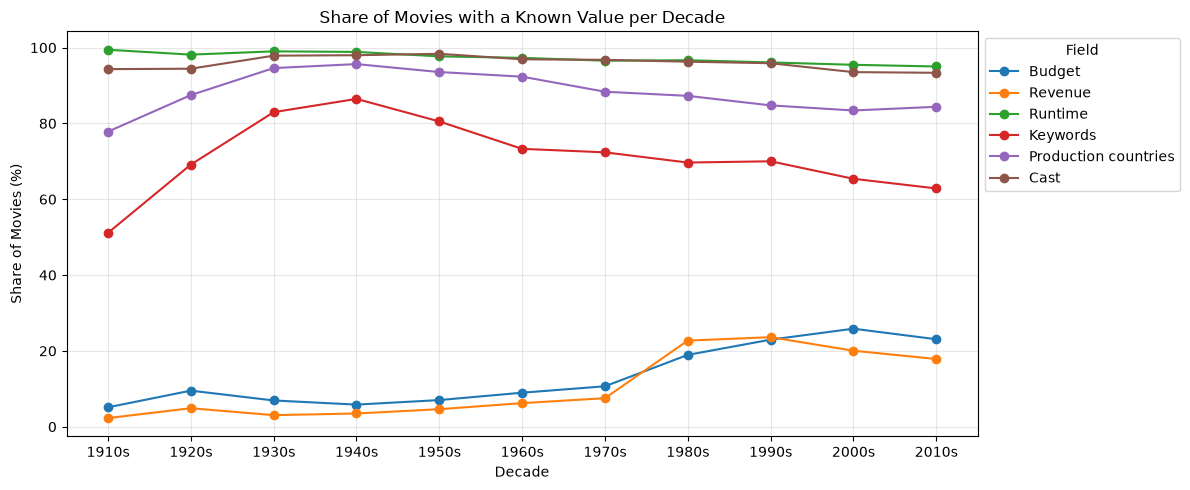

,Budget,Revenue,Runtime,Keywords,Production countries,Cast
original_language,,,,,,
English,23.1,19.7,97.7,72.8,84.0,94.1
Non-English,11.0,8.0,92.0,58.2,92.0,96.5


In [133]:
known_values = pd.DataFrame({
    "Budget": timeline["budget"].gt(0),
    "Revenue": timeline["revenue"].gt(0),
    "Runtime": timeline["runtime"].gt(0),
    "Keywords": timeline["n_keywords"].gt(0),
    "Production countries": timeline["country_codes"].map(len).gt(0),
    "Cast": timeline["n_cast"].gt(0)
})

known_per_decade = 100 * known_values.groupby(timeline["decade"]).mean()
known_per_decade = known_per_decade.loc[movies_per_decade[movies_per_decade >= MIN_MOVIES_PER_DECADE].index]

ax = known_per_decade.rename(index=decade_label).plot(
    figsize=(12, 5),
    marker="o",
    title="Share of Movies with a Known Value per Decade",
    xlabel="Decade",
    ylabel="Share of Movies (%)"
)

ax.set_xticks(range(len(known_per_decade)))
ax.set_xticklabels(known_per_decade.index.map(decade_label))
ax.grid(alpha=0.3)
ax.legend(title="Field", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "data_quality/known_values_per_decade.png", bbox_inches="tight")
plt.show()

language_group = timeline["original_language"].eq("en").map({True: "English", False: "Non-English"})
display((100 * known_values.groupby(language_group).mean()).round(1))

**Findings:** Missing data is not random. Budget and revenue are known for about 10 % or less of the movies before the 1970s and for 20–25 % since the 1980s, and twice as often for English as for non-English movies (23 % vs 11 % of the budgets). Keywords are best covered for the 1930s–1950s. Statistics on budget and revenue therefore mainly describe recent, English-language productions. Cleaning cannot remove this bias, so it must be taken into account when interpreting the results. Runtime, cast and production countries are known for 80–100 % of the movies in every decade.

A person has one TMDB `id` for all their credits, so an unknown gender (`0`) can be filled in when the same person has a known gender in another credit, provided that the known genders of a person never conflict.

In [134]:
people_gender = pd.concat([cast_members[["id", "gender"]], crew_members[["id", "gender"]]])
known_people_gender = people_gender[people_gender["gender"].ne(0)]
genders_per_person = known_people_gender.groupby("id")["gender"].nunique()
unknown_gender = people_gender["gender"].eq(0)
fillable_gender = unknown_gender & people_gender["id"].isin(genders_per_person.index)

display(pd.Series({
    "People with conflicting known genders": int((genders_per_person > 1).sum()),
    "Credits with unknown gender": int(unknown_gender.sum()),
    "... of which the person has a known gender in another credit": int(fillable_gender.sum()),
    "Unknown gender after filling (%)": round(100 * (unknown_gender & ~fillable_gender).sum() / len(people_gender), 2)
}).to_frame("Value"))

,Value
People with conflicting known genders,0.00
Credits with unknown gender,495797.00
... of which the person has a known gender in another credit,59.00
Unknown gender after filling (%),48.32


**Findings:** The known genders of a person never conflict between credits, but only 59 of the 495,797 credits with an unknown gender belong to a person whose gender is known elsewhere. Filling these is safe, but leaves 48 % of the credits with an unknown gender. Gender statistics must therefore still be computed over the known genders only. The remaining unknown genders are stored as missing (`None`) instead of 0.

### 24.2 Duplicate Values

Section 2 counted rows with a repeated primary key. Here the repeated rows are compared to decide which copy to keep, and duplicates are also searched for under other keys and inside the nested lists.

In [135]:
movie_columns = list(raw_movies_df.columns)
repeated_movies = movies_df[movies_df["id"].duplicated(keep=False)]
repeated_movies_text = repeated_movies[movie_columns].astype(str)

differing_columns = pd.Series(Counter(
    column
    for _, group in repeated_movies_text.groupby(repeated_movies["id"])
    for column in movie_columns
    if group[column].nunique() > 1
), dtype=int)

print(f"Repeated movie ids: {repeated_movies['id'].nunique()} ({len(repeated_movies)} rows)")
display(differing_columns.rename("Repeated ids where the column differs").to_frame())

def sorted_credits(people) -> str:
    """Credits of a movie as comparable text, independent of their order."""
    return json.dumps(sorted(people, key=lambda person: person["credit_id"]), sort_keys=True)

repeated_credits = credits_df[credits_df["id"].duplicated(keep=False)]
conflicting_credits = pd.DataFrame([
    {
        "id": movie_id,
        "Rows": len(group),
        "Identical rows": group[["cast", "crew"]].astype(str).drop_duplicates().shape[0] == 1,
        "Same credits in another order": (
            group["cast"].map(sorted_credits).nunique() == 1 and group["crew"].map(sorted_credits).nunique() == 1
        )
    }
    for movie_id, group in repeated_credits.groupby("id")
])
display(conflicting_credits[~conflicting_credits["Identical rows"]])

Repeated movie ids: 29 (59 rows)


,Repeated ids where the column differs
popularity,13
vote_count,2


,id,Rows,Identical rows,Same credits in another order
1,4912,2,False,True
20,69234,2,False,True
24,99080,2,False,True
27,110428,2,False,True
32,132641,2,False,True
37,159849,2,False,True
42,298721,2,False,True


,File,Duplicate check,Extra rows,Handling
0,movies_metadata,Same TMDB id,30,Keep the row with the highest vote_count
1,movies_metadata,Same IMDb id (one row per TMDB id),0,-
2,movies_metadata,Same title and release date,0,-
3,credits,Same movie id,44,Keep the first row
4,keywords,Same movie id,987,Keep the first row
5,links,Same MovieLens id,0,-
6,links,Same TMDB id,30,Link validation (24.4)
7,ratings,Same user and MovieLens id,0,-
8,ratings,Same user and TMDB id (after translation),125,Link validation (24.4)
9,credits,Same actor and character in a movie,4,Keep the first credit


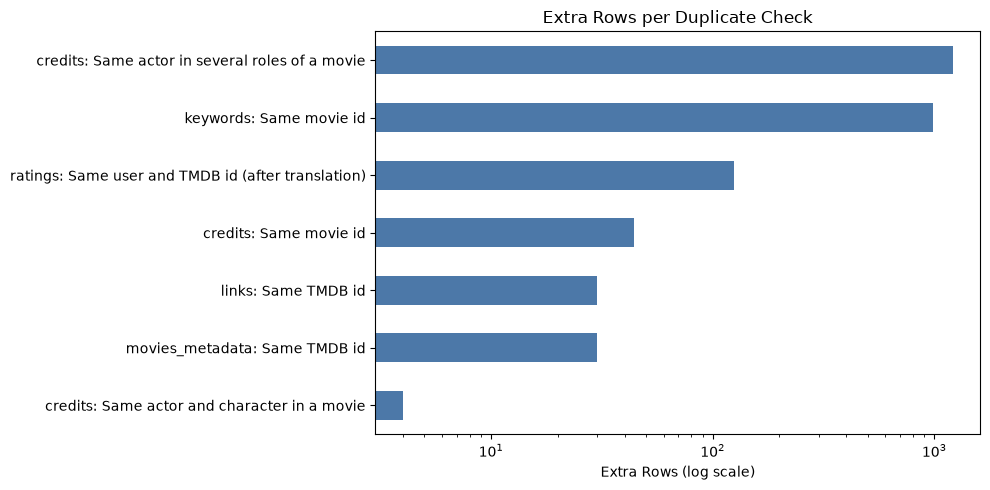

In [136]:
movie_ids_by_movielens_id = links_df.dropna(subset=["tmdbId"]).set_index("movieId")["tmdbId"]
translated_ratings = ratings_df.assign(tmdbId=ratings_df["movieId"].map(movie_ids_by_movielens_id)).dropna(subset=["tmdbId"])
keyword_pairs = pd.DataFrame([
    (movie_id, item["id"]) for movie_id, items in zip(keywords["id"], keywords["keywords"]) for item in items
], columns=["movie_id", "keyword_id"])

duplicate_checks = pd.DataFrame([
    ("movies_metadata", "Same TMDB id", movies_df["id"].duplicated().sum(), "Keep the row with the highest vote_count"),
    ("movies_metadata", "Same IMDb id (one row per TMDB id)", movies["imdb_id"].dropna().duplicated().sum(), "-"),
    ("movies_metadata", "Same title and release date", movies.dropna(subset=["title", "release_date"]).duplicated(["title", "release_date"]).sum(), "-"),
    ("credits", "Same movie id", credits_df["id"].duplicated().sum(), "Keep the first row"),
    ("keywords", "Same movie id", keywords_df["id"].duplicated().sum(), "Keep the first row"),
    ("links", "Same MovieLens id", links_df["movieId"].duplicated().sum(), "-"),
    ("links", "Same TMDB id", links_df["tmdbId"].dropna().duplicated().sum(), "Link validation (24.4)"),
    ("ratings", "Same user and MovieLens id", ratings_df.duplicated(["userId", "movieId"]).sum(), "-"),
    ("ratings", "Same user and TMDB id (after translation)", translated_ratings.duplicated(["userId", "tmdbId"]).sum(), "Link validation (24.4)"),
    ("credits", "Same actor and character in a movie", cast_members.duplicated(["movie_id", "id", "character"]).sum(), "Keep the first credit"),
    ("credits", "Same actor in several roles of a movie", cast_members.duplicated(["movie_id", "id"]).sum(), "Keep (several roles)"),
    ("credits", "Same crew member and job in a movie", crew_members.duplicated(["movie_id", "id", "job"]).sum(), "-"),
    ("keywords", "Same keyword twice in a movie", keyword_pairs.duplicated().sum(), "-"),
], columns=["File", "Duplicate check", "Extra rows", "Handling"])

display(duplicate_checks)

ax = duplicate_checks.assign(Check=duplicate_checks["File"] + ": " + duplicate_checks["Duplicate check"]).set_index("Check")["Extra rows"].loc[lambda rows: rows > 0].sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    logx=True,
    color="#4C78A8",
    title="Extra Rows per Duplicate Check",
    ylabel=""
)

ax.set_xlabel("Extra Rows (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "data_quality/duplicates_summary.png", bbox_inches="tight")
plt.show()

**Findings:**

- The 29 repeated movie ids (59 rows) are either exact copies or only differ in `popularity` (13 ids) and `vote_count` (2 ids). Keeping the row with the highest vote count keeps the most up-to-date values without losing information.
- The 7 repeated credits ids that are not exact copies contain the same credits in another order, and all repeated keyword rows are exact copies, so the first row can be kept.
- There are no duplicates under other keys: no two movies share an IMDb id or a title and release date, and no keyword appears twice in a movie.
- In the cast, 4 credits repeat the same actor and character and are removed. The 1,207 actors with several roles in the same movie are legitimate and kept, and the queries count every person once per movie.
- 29 TMDB ids are linked from more than one MovieLens id (59 links), which gives 125 repeated (user, movie) ratings after translating the ids. This is resolved by the link validation in 24.4.

### 24.3 Inconsistent Values

The three rows that failed in 3.1 are the second half of the row directly above them: the record was split over two lines in the CSV file. The first half holds the columns up to a cut-off `overview`, while the second half starts with the rest of the overview in `adult`, followed by the remaining columns shifted by nine positions (`popularity` is stored in `belongs_to_collection`, `poster_path` in `budget`, and so on). Moving the values back repairs the three records instead of losing them.

In [137]:
first_shifted = movie_columns.index("popularity")
shift = first_shifted - movie_columns.index("belongs_to_collection")

split_records = []
for index in raw_movies_df.index[malformed_mask]:
    first_half, second_half = raw_movies_df.loc[index - 1], raw_movies_df.loc[index]
    repaired = first_half.copy()
    repaired["overview"] = first_half["overview"] + second_half["adult"]
    repaired[movie_columns[first_shifted:]] = second_half[movie_columns[1:len(movie_columns) - shift]].to_numpy()
    split_records.append(repaired)

print(f"Columns shifted by {shift} positions")
display(pd.DataFrame(split_records)[["id", "title", "release_date", "runtime", "status", "vote_average", "vote_count", "popularity"]])

Columns shifted by 9 positions


,id,title,release_date,runtime,status,vote_average,vote_count,popularity
19729,82663,Midnight Man,1997-08-20,104.0,Released,6.0,1,0.065736
29502,122662,Mardock Scramble: The Third Exhaust,2012-09-29,68.0,Released,7.0,12,1.931659
35586,249260,Avalanche Sharks,2014-01-01,82.0,Released,4.3,22,2.185485


In [138]:
spoken_language_names = spoken_language_objects.assign(name=spoken_language_objects["name"].str.strip())
country_objects = pd.DataFrame([item for items in movies["production_countries"] for item in items])
codes_per_country_name = country_objects.groupby("name")["iso_3166_1"].unique()
person_names = pd.concat([cast_members[["id", "name"]], crew_members[["id", "name"]]])
names_per_person = person_names.groupby("id")["name"].nunique()
cast_orders = credits["cast"].map(lambda cast: sorted(member["order"] for member in cast))
not_released = movies["status"].notna() & movies["status"].ne("Released")
link_imdb = movies.set_index("id")["imdb_id"].dropna().str.removeprefix("tt").astype(int)
links_with_movie_imdb = links_df.assign(movie_imdb=links_df["tmdbId"].map(link_imdb)).dropna(subset=["movie_imdb"])

inconsistencies = pd.DataFrame([
    ("movies_metadata", "Record split over two lines (shifted columns)", malformed_mask.sum(), len(raw_movies_df)),
    ("movies_metadata", "adult is not True/False", (~raw_movies_df["adult"].isin(["True", "False"])).sum(), len(raw_movies_df)),
    ("movies_metadata", "vote_average = 0 although the movie has votes", (movies["vote_count"].gt(0) & movies["vote_average"].eq(0)).sum(), len(movies)),
    ("movies_metadata", "Status Released but no release date", (movies["status"].eq("Released") & movies["release_date"].isna()).sum(), len(movies)),
    ("movies_metadata", "Not released but has a revenue", (not_released & movies["revenue"].gt(0)).sum(), len(movies)),
    ("movies_metadata", "Spoken language with an empty name", spoken_language_names["name"].eq("").sum(), len(spoken_language_names)),
    ("movies_metadata", "Country name used for several country codes", (codes_per_country_name.map(len) > 1).sum(), len(codes_per_country_name)),
    ("credits", "Person id with several name spellings", (names_per_person > 1).sum(), len(names_per_person)),
    ("credits", "Cast order with gaps (not 0, 1, 2, ...)", cast_orders.map(lambda orders: orders != list(range(len(orders))) and len(orders) == len(set(orders))).sum(), len(credits)),
    ("credits", "Repeated cast order value in a movie", cast_orders.map(lambda orders: len(orders) != len(set(orders))).sum(), len(credits)),
    ("links", "imdbId differs from the movie's imdb_id", links_with_movie_imdb["imdbId"].ne(links_with_movie_imdb["movie_imdb"]).sum(), len(links_with_movie_imdb)),
], columns=["File", "Check", "Records", "Out of"])
inconsistencies["Share (%)"] = 100 * inconsistencies["Records"] / inconsistencies["Out of"]

display(inconsistencies.round(3))

,File,Check,Records,Out of,Share (%)
0,movies_metadata,Record split over two lines (shifted columns),3,45466,0.007
1,movies_metadata,adult is not True/False,3,45466,0.007
2,movies_metadata,vote_average = 0 although the movie has votes,99,45433,0.218
3,movies_metadata,Status Released but no release date,78,45433,0.172
4,movies_metadata,Not released but has a revenue,11,45433,0.024
5,movies_metadata,Spoken language with an empty name,498,53266,0.935
6,movies_metadata,Country name used for several country codes,1,160,0.625
7,credits,Person id with several name spellings,15,353343,0.004
8,credits,"Cast order with gaps (not 0, 1, 2, ...)",11355,45432,24.993
9,credits,Repeated cast order value in a movie,87,45432,0.191


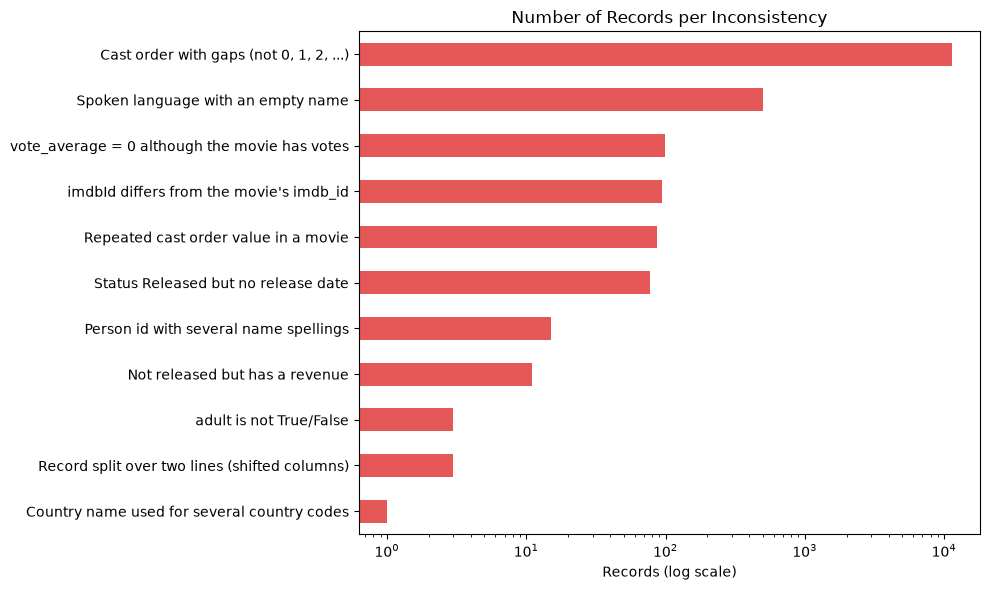

Country names used for several codes: {'Congo': ['CD', 'CG']}
Spoken languages without a name, by code: {'yi': 62, 'tl': 58, 'ml': 43, 'mr': 41, 'gd': 23, 'sh': 21, 'ku': 18, 'hy': 18}


,id,name
3383,9779,Моррис Честнат
530363,9779,Morris Chestnut
4870,23764,Эрика Элениак
562024,23764,Erika Eleniak
6620,58646,Дэмиан Чапа
562028,58646,Damian Chapa
40726,63574,Ka-Fai Cheung
143220,63574,Cheung Ka-Fai
100277,67212,Том Ву
532584,67212,Tom Wu


In [139]:
ax = inconsistencies.set_index("Check")["Records"].loc[lambda records: records > 0].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    logx=True,
    color="#E45756",
    title="Number of Records per Inconsistency",
    ylabel=""
)

ax.set_xlabel("Records (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "data_quality/inconsistent_values.png", bbox_inches="tight")
plt.show()

print("Country names used for several codes:", codes_per_country_name[codes_per_country_name.map(len) > 1].map(list).to_dict())
print("Spoken languages without a name, by code:", spoken_language_names.loc[spoken_language_names["name"].eq(""), "iso_639_1"].value_counts().head(8).to_dict())
display(person_names[person_names["id"].isin(names_per_person[names_per_person > 1].index)].drop_duplicates().sort_values("id").head(10))

**Findings:**

- All three split records can be repaired. After shifting the values back, they have a valid title, release date, runtime and votes (e.g. *Midnight Man*, 1997). The 3 invalid `adult` values are the overview text of the second halves and disappear with the repair.
- 99 movies have votes but a `vote_average` of 0. A TMDB vote is at least 0.5, so this average is impossible and is stored as missing.
- 498 spoken languages have an empty name, mostly less common languages such as Yiddish (`yi`) and Tagalog (`tl`). Their ISO code is valid, so the name can be derived from it. "Congo" is used for both `CD` and `CG`, so grouping by country name would merge two countries.
- 15 people appear with two spellings, mostly the same name in Cyrillic and Latin script (e.g. Моррис Честнат / Morris Chestnut). Every credit gets the most common spelling.
- In 11,355 movies the cast `order` has gaps, and in 87 it has repeated values. "The 5 top-billed actors" is therefore only well-defined after sorting and re-numbering the cast.
- 95 links (0.2 %) point to a TMDB movie with a different IMDb id, so they connect ratings to the wrong movie (see 24.4).
- 78 released movies have no release date and 11 unreleased movies report a revenue. The correct values cannot be derived from the data, so these are kept and only reported.

### 24.4 Referential Integrity

The cleaned data has these references: `credits.id` and `keywords.id` refer to `movies_metadata.id`, and a rating refers to its movie through `ratings.movieId` → `links.movieId` → `links.tmdbId` → `movies_metadata.id`. MongoDB does not enforce foreign keys, so the cleaning must make sure that every reference points to an existing movie.

A link is valid when its `tmdbId` exists among the movies and its `imdbId` agrees with the `imdb_id` of that movie (when both are known). A link that fails is re-mapped through its `imdbId` if that IMDb id belongs to a movie, and is otherwise dropped together with its ratings.

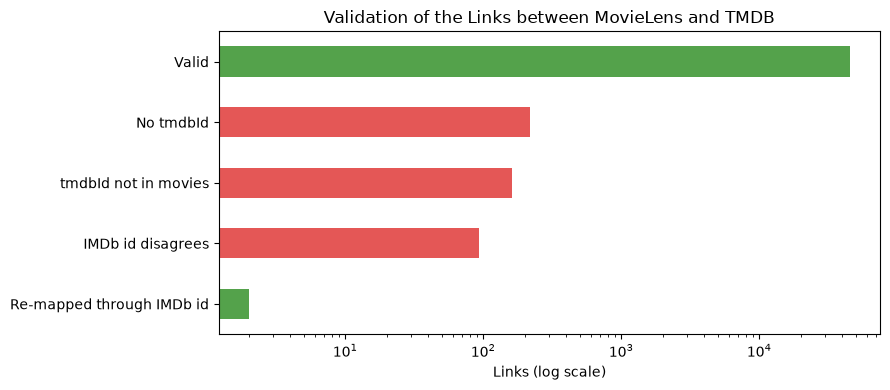

,Links
status,
Valid,45368
No tmdbId,219
tmdbId not in movies,161
IMDb id disagrees,93
Re-mapped through IMDb id,2


In [140]:
movie_ids = set(movies["id"])
tmdb_id_by_imdb_id = pd.Series(link_imdb.index, index=link_imdb.to_numpy())

link_check = links_df.copy()
link_check["movie_imdb"] = link_check["tmdbId"].map(link_imdb)
link_check["status"] = np.select(
    [
        link_check["tmdbId"].isna().to_numpy(),
        (~link_check["tmdbId"].isin(movie_ids)).to_numpy(),
        (link_check["movie_imdb"].notna() & link_check["imdbId"].ne(link_check["movie_imdb"])).to_numpy()
    ],
    ["No tmdbId", "tmdbId not in movies", "IMDb id disagrees"],
    default="Valid"
)
remapped = link_check["status"].ne("Valid") & link_check["imdbId"].isin(tmdb_id_by_imdb_id.index)
link_check["movie_id"] = np.where(
    link_check["status"].eq("Valid"),
    link_check["tmdbId"],
    link_check["imdbId"].map(tmdb_id_by_imdb_id).where(remapped)
)
link_check.loc[remapped, "status"] = "Re-mapped through IMDb id"

link_status = link_check["status"].value_counts()
ax = link_status.sort_values().plot(
    kind="barh",
    figsize=(9, 4),
    logx=True,
    color=["#E45756" if status not in ("Valid", "Re-mapped through IMDb id") else "#54A24B" for status in link_status.sort_values().index],
    title="Validation of the Links between MovieLens and TMDB",
    ylabel=""
)

ax.set_xlabel("Links (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "data_quality/link_validation.png", bbox_inches="tight")
plt.show()

display(link_status.to_frame("Links"))

In [141]:
valid_links = link_check.dropna(subset=["movie_id"]).set_index("movieId")["movie_id"]
ratings_movie_ids = {
    "Direct links (tmdbId)": ratings_df["movieId"].map(movie_ids_by_movielens_id.where(movie_ids_by_movielens_id.isin(movie_ids))),
    "Validated links": ratings_df["movieId"].map(valid_links)
}

display(pd.DataFrame.from_dict({
    name: {
        "Ratings linked to a movie": int(movie_id.notna().sum()),
        "Ratings dropped (no valid movie)": int(movie_id.isna().sum()),
        "Dropped (%)": round(100 * movie_id.isna().mean(), 3),
        "MovieLens ids per TMDB id (max)": int((valid_links if name == "Validated links" else movie_ids_by_movielens_id).value_counts().max()),
        "Repeated (user, movie) pairs": int(ratings_df.assign(movie_id=movie_id).dropna(subset=["movie_id"]).duplicated(["userId", "movie_id"]).sum())
    }
    for name, movie_id in ratings_movie_ids.items()
}, orient="index"))

display(pd.DataFrame([
    match_keys("credits.id", "movies.id", credits["id"], movie_ids),
    match_keys("keywords.id", "movies.id", keywords["id"], movie_ids),
    match_keys("links (validated)", "movies.id", valid_links, movie_ids),
    match_keys("ratings (validated)", "movies.id", ratings_movie_ids["Validated links"].dropna(), movie_ids)
]).round(3))

,Ratings linked to a movie,Ratings dropped (no valid movie),Dropped (%),MovieLens ids per TMDB id (max),"Repeated (user, movie) pairs"
Direct links (tmdbId),25981582,42707,0.164,3,125
Validated links,25969876,54413,0.209,1,0


,Key,References,Rows,Missing key,Unmatched rows,Matched rows (%),Distinct keys,Unmatched distinct keys
0,credits.id,movies.id,45432,0,0,100.0,45432,0
1,keywords.id,movies.id,45432,0,0,100.0,45432,0
2,links (validated),movies.id,45370,0,0,100.0,45370,0
3,ratings (validated),movies.id,25969876,0,0,100.0,44648,0


**Findings:**

- Of the 45,843 links, 45,368 are valid and 2 can be re-mapped through their IMDb id. The other 473 are dropped: 219 have no `tmdbId`, 161 point to a movie that does not exist, and 93 point to a movie with a different IMDb id.
- After validation, every MovieLens id refers to exactly one movie and every movie to at most one MovieLens id, so no user has two ratings of the same movie any more.
- 54,413 ratings (0.21 %) cannot be linked to a valid movie and are dropped, compared with 42,707 when the `tmdbId` is used directly. The additional 11,706 ratings would otherwise be attached to the wrong movie.
- After cleaning, every credit, keyword, link and rating references an existing movie (100 % matched), so the inserted data keeps its referential integrity.

### 24.5 Cleaning Decisions

| Issue | Handling | Step in `insert.py` |
|---|---|---|
| Records split over two lines (3) | Merge the two halves and shift the values back | `repair_split_records` |
| Repeated movie ids (29) | Keep the row with the highest `vote_count` (the rows only differ in `popularity` and `vote_count`) | `remove_duplicate_movies` |
| 0 in `budget`, `revenue`, `runtime`; `vote_average` without votes; placeholder overviews | Store as missing | `handle_missing_movie_values` |
| `vote_average` = 0 although the movie has votes | Store as missing (a vote is at least 0.5) | `fix_inconsistent_movie_values` |
| Spoken languages without a name; "Congo" used for two countries | Fill the name from the ISO code; give each country code its own name | `fix_inconsistent_movie_values` |
| Repeated credits and keywords ids | Keep the first row (the copies contain the same credits) | `remove_duplicate_credits`, `remove_duplicate_keywords` |
| Unknown gender (`0`), empty `character` | Fill the gender from the person's other credits, otherwise store as missing | `clean_cast_and_crew` |
| Same actor and character twice in a movie | Keep the first credit | `clean_cast_and_crew` |
| Gaps and repeated values in the cast `order` | Re-number the cast 0, 1, 2, ... by billing order | `clean_cast_and_crew` |
| Several name spellings for one person | Use the most common spelling for every credit | `clean_cast_and_crew` |
| Credits or keywords of unknown movies | Drop (none in this dataset) | `remove_orphans` |
| Links without a valid movie or with a disagreeing IMDb id | Re-map through the IMDb id, otherwise drop | `validate_links` |
| Ratings without a valid link | Drop, so every rating references an existing movie | `link_ratings_to_movies` |
| Repeated (user, movie) ratings | Keep the latest rating (none remain after link validation) | `remove_duplicate_ratings` |

Empty arrays (no genres, cast, keywords, ...) are kept as empty arrays, since they correctly describe that no information is available. Inconsistencies that cannot be resolved from the data, such as released movies without a release date or unreleased movies with a revenue, are kept as they are.